# Sprint 18 — Projeto Final
## Previsão de Risco de Incêndios no Brasil

### 1. Introdução

Os incêndios representam um desafio para a preservação ambiental, a segurança da população e a gestão dos recursos naturais. A identificação antecipada de condições favoráveis à ocorrência de incêndios pode contribuir para o planejamento de ações preventivas e para a tomada de decisões.

Este projeto tem como objetivo desenvolver uma solução de Machine Learning para classificar o risco de incêndio em diferentes regiões do Brasil, considerando informações históricas de queimadas, condições meteorológicas e características ambientais.

### 2. Problema de negócio

Como utilizar dados históricos de queimadas, informações meteorológicas e características ambientais para estimar o nível de risco de incêndio em determinada região e data?

A solução proposta deverá classificar o risco em três categorias:

- **Baixo:** condições associadas a menor risco de incêndio.
- **Médio:** condições associadas a risco intermediário.
- **Alto:** condições associadas a maior risco de incêndio.

Os critérios utilizados para definir essas categorias serão estabelecidos após a análise das bases de dados.

### 3. Objetivo geral

Desenvolver e avaliar modelos de Machine Learning capazes de classificar o risco de incêndio, utilizando informações históricas e ambientais, com foco na consistência técnica, na interpretação dos resultados e no apoio à tomada de decisões preventivas.

### 4. Objetivos específicos

- Investigar a estrutura e a qualidade das bases de dados.
- Identificar padrões históricos, meteorológicos e ambientais relacionados ao risco de incêndio.
- Realizar a limpeza, o tratamento e a integração dos dados.
- Explorar relações estatísticas e testar hipóteses relevantes para o problema de negócio.
- Preparar uma base consolidada para o treinamento de modelos de Machine Learning.
- Documentar as decisões metodológicas, os resultados e as limitações identificadas.

### 5. Fontes de dados

O projeto utilizará quatro bases disponibilizadas pela TripleTen, originalmente extraídas da plataforma Base dos Dados:

1. **Queimadas:** registros históricos de focos de incêndio.
2. **MapBiomas:** informações sobre características e classes de uso e cobertura do solo.
3. **BDMEP — Estações:** informações geográficas das estações meteorológicas.
4. **BDMEP — Medições:** registros de condições meteorológicas.

### 6. Organização do projeto

O desenvolvimento será estruturado em três etapas obrigatórias:

- **Etapa 1:** diagnóstico, análise exploratória e preparação dos dados.
- **Etapa 2:** modelagem preditiva e análise de impacto de negócio.
- **Etapa 3:** otimização, explicabilidade e avaliação de vieses.

Este notebook corresponde à **Etapa 1**, dedicada ao entendimento, à exploração e à preparação dos dados.

In [1]:
import os

print("Diretório de trabalho atual:")
print(os.getcwd())

Diretório de trabalho atual:
C:\Users\adl_c\Sprint18_Projeto_Final\notebooks


In [2]:
from pathlib import Path

# Define a pasta principal do projeto
projeto = Path.home() / "Sprint18_Projeto_Final"

# Define as subpastas
pastas = [
    projeto / "dados" / "originais",
    projeto / "dados" / "processados",
    projeto / "notebooks",
    projeto / "relatorios"
]

# Cria as pastas, caso ainda não existam
for pasta in pastas:
    pasta.mkdir(parents=True, exist_ok=True)
    print(f"Pasta criada ou existente: {pasta}")

Pasta criada ou existente: C:\Users\adl_c\Sprint18_Projeto_Final\dados\originais
Pasta criada ou existente: C:\Users\adl_c\Sprint18_Projeto_Final\dados\processados
Pasta criada ou existente: C:\Users\adl_c\Sprint18_Projeto_Final\notebooks
Pasta criada ou existente: C:\Users\adl_c\Sprint18_Projeto_Final\relatorios


In [3]:
from pathlib import Path

# Caminho esperado para o notebook
caminho_notebook = (
    Path.home()
    / "Sprint18_Projeto_Final"
    / "notebooks"
    / "Sprint18_Etapa1_EDA_Preparacao.ipynb"
)

# Verifica se o arquivo existe
print("Notebook encontrado:", caminho_notebook.is_file())
print("Localização esperada:", caminho_notebook)

Notebook encontrado: True
Localização esperada: C:\Users\adl_c\Sprint18_Projeto_Final\notebooks\Sprint18_Etapa1_EDA_Preparacao.ipynb


In [4]:
from pathlib import Path

# Define o caminho da pasta de dados originais
pasta_dados = Path.home() / "Sprint18_Projeto_Final" / "dados" / "originais"

# Define o caminho do arquivo
arquivo_estacoes = pasta_dados / "BDMEP-estacao.csv"

# Verifica se o arquivo existe
print("Arquivo encontrado:", arquivo_estacoes.is_file())

# Exibe o tamanho do arquivo
if arquivo_estacoes.is_file():
    tamanho_kb = arquivo_estacoes.stat().st_size / 1024
    print(f"Tamanho do arquivo: {tamanho_kb:.2f} KB")

Arquivo encontrado: True
Tamanho do arquivo: 47.59 KB


In [5]:
# Inspeciona as primeiras linhas do arquivo original
with open(arquivo_estacoes, "r", encoding="utf-8-sig") as arquivo:
    for i in range(5):
        linha = arquivo.readline()
        print(f"Linha {i + 1}: {linha.strip()}")

Linha 1: id_municipio,id_municipio_nome,id_estacao,estacao,data_fundacao,latitude,longitude,altitude
Linha 2: 5300108,Brasília,A001,Brasilia,2000-05-07,-15.78944444,-47.92583332,1160.96
Linha 3: 5300108,Brasília,A042,Brazlandia,2017-07-19,-15.59972221,-48.1311111,1143.0
Linha 4: 5300108,Brasília,A045,Aguas Emendadas,2008-10-03,-15.596491,-47.625801,1030.36
Linha 5: 5300108,Brasília,A046,Gama (Ponte Alta),2014-10-01,-15.93527777,-48.13749999,990.0


In [6]:
# Carrega os dados das estações meteorológicas
import pandas as pd
df_estacoes = pd.read_csv(
    arquivo_estacoes,
    sep=",",
    encoding="utf-8-sig",
    dtype={
        "id_municipio": "string",
        "id_estacao": "string"
    }
)

# Exibe as dimensões da base
print("Dimensões da base:", df_estacoes.shape)

# Exibe os cinco primeiros registros
display(df_estacoes.head())

Dimensões da base: (612, 8)


,id_municipio,id_municipio_nome,id_estacao,estacao,data_fundacao,latitude,longitude,altitude
0,5300108,Brasília,A001,Brasilia,2000-05-07,-15.789444,-47.925833,1160.96
1,5300108,Brasília,A042,Brazlandia,2017-07-19,-15.599722,-48.131111,1143.00
2,5300108,Brasília,A045,Aguas Emendadas,2008-10-03,-15.596491,-47.625801,1030.36
3,5300108,Brasília,A046,Gama (Ponte Alta),2014-10-01,-15.935278,-48.137500,990.00
4,5300108,Brasília,A047,Paranoa (Coopa-Df),2017-02-07,-16.012222,-47.557417,1043.00


In [7]:
# Verifica a estrutura e os tipos de dados
df_estacoes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_municipio       610 non-null    string 
 1   id_municipio_nome  610 non-null    object 
 2   id_estacao         612 non-null    string 
 3   estacao            612 non-null    object 
 4   data_fundacao      612 non-null    object 
 5   latitude           612 non-null    float64
 6   longitude          612 non-null    float64
 7   altitude           595 non-null    float64
dtypes: float64(3), object(3), string(2)
memory usage: 38.4+ KB


In [8]:
# Verifica registros completamente duplicados
duplicatas_completas = df_estacoes.duplicated().sum()

# Verifica identificadores de estações repetidos
duplicatas_estacoes = df_estacoes["id_estacao"].duplicated().sum()

# Conta as estações distintas
estacoes_unicas = df_estacoes["id_estacao"].nunique()

print("Registros completamente duplicados:", duplicatas_completas)
print("Identificadores de estações repetidos:", duplicatas_estacoes)
print("Estações distintas:", estacoes_unicas)

Registros completamente duplicados: 0
Identificadores de estações repetidos: 0
Estações distintas: 612


In [9]:
# Seleciona os registros com pelo menos um valor ausente
estacoes_ausentes = df_estacoes[
    df_estacoes.isna().any(axis=1)
]

# Exibe a quantidade de registros afetados
print(
    "Registros com pelo menos um valor ausente:",
    len(estacoes_ausentes)
)

# Apresenta os registros identificados
display(estacoes_ausentes)

Registros com pelo menos um valor ausente: 19


,id_municipio,id_municipio_nome,id_estacao,estacao,data_fundacao,latitude,longitude,altitude
588,<NA>,NaN,A302,Arq.sao Pedro E Sao Paulo,2003-11-02,0.916877,-29.345904,15.0
589,<NA>,NaN,C891,Criosfera,2012-01-09,-84.000000,-79.494167,1285.0
592,2110500,São Bento,S108,Sao Bento,2016-12-01,-2.700000,-44.850000,NaN
594,1303700,Santo Antônio do Içá,S102,Pef Ipiranga,2016-12-01,-2.930556,-69.695278,NaN
595,1302603,Manaus,S103,Crmn Manaus,2016-12-01,-3.022500,-60.055556,NaN
596,1304062,Tabatinga,S105,Dtcea Tabatinga,2016-12-01,-4.250556,-69.935000,NaN
597,1303809,São Gabriel da Cachoeira,S115,Pef Yauarete,2016-12-01,0.599444,-69.191944,NaN
598,1300201,Atalaia do Norte,S116,Pef Estirao Do Equador,2016-12-01,-4.530000,-71.617500,NaN
599,1304203,Tefé,S117,Dtcea Tefe,2016-12-01,-3.377222,-64.723056,NaN
600,1303601,Santa Isabel do Rio Negro,S121,Santa Isabel Do Rio Negro,2016-12-01,-0.414444,-65.017500,NaN


### Análise preliminar — Cadastro das estações meteorológicas

A base `BDMEP-estacao.csv` contém 612 registros e 8 variáveis, incluindo informações de identificação, localização geográfica e características das estações meteorológicas.

A inspeção inicial identificou os seguintes aspectos:

- **Integridade dos identificadores:** os 612 registros possuem códigos de estação distintos, sem duplicatas completas ou identificadores repetidos.
- **Valores ausentes:** foram encontrados 19 registros com pelo menos uma informação ausente, correspondendo a aproximadamente 3,1% da base.
- **Identificação municipal:** dois registros não apresentam código nem nome do município.
- **Altitude:** 17 registros apresentam valores ausentes nessa variável.
- **Coordenadas geográficas:** todos os registros possuem latitude e longitude preenchidas.
- **Tipos de dados:** a coluna `data_fundacao` foi identificada como texto (`object`) e poderá exigir conversão para o formato de data.
- **Dicionário de dados:** foi identificada a coluna adicional `id_municipio_nome`, não documentada no dicionário fornecido.

**Conclusão preliminar**

A base apresenta boa integridade estrutural, especialmente quanto à identificação individual das estações e à disponibilidade de coordenadas geográficas.

As informações ausentes não justificam, neste momento, a exclusão de registros. A necessidade de tratamento será avaliada posteriormente, considerando a integração com as demais bases e a relevância das variáveis para o problema preditivo.

Nenhuma transformação ou exclusão de dados foi realizada nesta etapa.

In [10]:
# Análise estatística das variáveis numéricas
df_estacoes[["latitude", "longitude", "altitude"]].describe()

,latitude,longitude,altitude
count,612.000000,612.000000,595.000000
mean,-15.709950,-48.400933,417.517782
std,8.752006,7.373967,345.548799
min,-84.000000,-79.494167,1.000000
25%,-22.251555,-52.939767,131.060000
50%,-16.124167,-48.228333,365.790000
75%,-8.649722,-42.788472,629.445000
max,4.477500,-29.345904,2450.000000


In [11]:
# Identifica estações com coordenadas fora dos limites aproximados do Brasil
coordenadas_suspeitas = df_estacoes[
    (~df_estacoes["latitude"].between(-34, 6)) |
    (~df_estacoes["longitude"].between(-74, -28))
]

# Exibe a quantidade de registros identificados
print("Estações com coordenadas suspeitas:", len(coordenadas_suspeitas))

# Apresenta os registros para investigação
display(coordenadas_suspeitas)

Estações com coordenadas suspeitas: 1


,id_municipio,id_municipio_nome,id_estacao,estacao,data_fundacao,latitude,longitude,altitude
589,<NA>,NaN,C891,Criosfera,2012-01-09,-84.0,-79.494167,1285.0


In [12]:
# Seleciona as estações sem identificação do município
estacoes_sem_municipio = df_estacoes[
    df_estacoes["id_municipio"].isna()
]

# Exibe a quantidade de registros
print(
    "Estações sem identificação municipal:",
    len(estacoes_sem_municipio)
)

# Apresenta os registros
display(estacoes_sem_municipio)

Estações sem identificação municipal: 2


,id_municipio,id_municipio_nome,id_estacao,estacao,data_fundacao,latitude,longitude,altitude
588,<NA>,NaN,A302,Arq.sao Pedro E Sao Paulo,2003-11-02,0.916877,-29.345904,15.0
589,<NA>,NaN,C891,Criosfera,2012-01-09,-84.000000,-79.494167,1285.0


### Investigação da consistência geográfica

A análise estatística das coordenadas identificou uma estação com latitude fora dos limites aproximados do território brasileiro.

A investigação revelou tratar-se da estação **Criosfera (C891)**, localizada na Antártida. Portanto, o valor extremo não representa necessariamente um erro de registro, mas uma localização geográfica incompatível com o escopo territorial inicialmente previsto para o projeto.

Também foram identificadas duas estações sem código de município:

- **A302 — Arquipélago de São Pedro e São Paulo:** localizada em território brasileiro, mas sem identificação municipal na base.
- **C891 — Criosfera:** localizada na Antártida e sem identificação municipal.

**Conclusão**

As inconsistências identificadas exigem atenção durante a integração das bases, especialmente porque o projeto utilizará informações geográficas e meteorológicas para estimar o risco de incêndio.

A estação Criosfera poderá ser excluída da base de modelagem por estar fora do escopo geográfico do projeto.

A estação do Arquipélago de São Pedro e São Paulo será reavaliada conforme a estratégia de integração territorial adotada.

Neste momento, nenhuma exclusão ou alteração foi realizada. Os registros originais permanecem preservados.

In [13]:
# Converte a data de fundação para o formato datetime
df_estacoes["data_fundacao"] = pd.to_datetime(
    df_estacoes["data_fundacao"],
    errors="coerce"
)

# Verifica o período das datas de fundação
print("Data mais antiga:", df_estacoes["data_fundacao"].min())
print("Data mais recente:", df_estacoes["data_fundacao"].max())

# Verifica possíveis datas inválidas
print(
    "Datas ausentes ou inválidas:",
    df_estacoes["data_fundacao"].isna().sum()
)

Data mais antiga: 2000-05-07 00:00:00
Data mais recente: 2020-12-18 00:00:00
Datas ausentes ou inválidas: 0


### Análise temporal das estações meteorológicas

A variável `data_fundacao` foi convertida do tipo `object` para `datetime`, permitindo sua análise temporal.

Os resultados indicaram:

- **Data de fundação mais antiga:** 07/05/2000.
- **Data de fundação mais recente:** 18/12/2020.
- **Datas ausentes ou inválidas:** nenhuma.

A conversão foi realizada com sucesso para todos os 612 registros.

**Interpretação**

O cadastro apresenta estações com diferentes períodos de fundação, abrangendo aproximadamente duas décadas.

Entretanto, a data de fundação não permite determinar o período efetivo de disponibilidade dos registros meteorológicos.

Essa informação deverá ser investigada na base de medições `BDMEP-2025.csv`, especialmente para avaliar a compatibilidade temporal entre as bases utilizadas no projeto.

**Conclusão**

A coluna `data_fundacao` apresenta consistência inicial e não exige tratamento adicional nesta fase.

A transformação foi realizada apenas no DataFrame em memória, preservando o arquivo CSV original.

In [14]:
# Define o caminho do arquivo de medições meteorológicas
arquivo_meteorologia = pasta_dados / "BDMEP-2025.csv"

# Verifica se o arquivo existe
print("Arquivo encontrado:", arquivo_meteorologia.is_file())

# Exibe o tamanho do arquivo
if arquivo_meteorologia.is_file():
    tamanho_mb = arquivo_meteorologia.stat().st_size / (1024**2)
    print(f"Tamanho do arquivo: {tamanho_mb:.2f} MiB")

Arquivo encontrado: True
Tamanho do arquivo: 444.76 MiB


In [15]:
# Inspeciona as primeiras linhas da base meteorológica
with open(arquivo_meteorologia, "r", encoding="utf-8-sig") as arquivo:
    for i in range(5):
        linha = arquivo.readline()
        print(f"Linha {i + 1}: {linha.strip()}")

Linha 1: ano,data,hora,id_estacao,precipitacao_total,pressao_atm_hora,pressao_atm_max,pressao_atm_min,radiacao_global,temperatura_bulbo_hora,temperatura_orvalho_hora,temperatura_max,temperatura_min,temperatura_orvalho_max,temperatura_orvalho_min,umidade_rel_max,umidade_rel_min,umidade_rel_hora,vento_direcao,vento_rajada_max,vento_velocidade
Linha 2: 2025,2025-05-29,13:00:00,A316,0.0,997.6,997.9,997.5,2523.7,30.7,16.0,31.1,28.8,18.5,15.9,53.0,41.0,41.0,106.0,9.1,4.2
Linha 3: 2025,2025-01-21,16:00:00,A867,0.0,1007.7,1008.4,1007.7,3896.8,32.6,17.6,32.8,31.6,18.6,14.8,46.0,34.0,41.0,256.0,8.8,4.5
Linha 4: 2025,2025-05-14,18:00:00,A366,0.0,958.9,959.3,958.7,2227.9,30.3,11.8,31.2,29.5,13.7,11.8,36.0,31.0,32.0,119.0,11.7,5.5
Linha 5: 2025,2025-05-27,16:00:00,A849,0.0,971.3,972.2,971.3,2279.0,29.8,15.3,29.8,27.9,15.4,14.5,45.0,41.0,41.0,,10.3,5.5


In [16]:
# Carrega uma amostra inicial de 1.000 registros
df_meteorologia_amostra = pd.read_csv(
    arquivo_meteorologia,
    sep=",",
    encoding="utf-8-sig",
    nrows=1000,
    dtype={
        "id_estacao": "string"
    }
)

# Exibe as dimensões da amostra
print("Dimensões da amostra:", df_meteorologia_amostra.shape)

# Exibe os primeiros cinco registros
display(df_meteorologia_amostra.head())

Dimensões da amostra: (1000, 21)


,ano,data,hora,id_estacao,precipitacao_total,pressao_atm_hora,pressao_atm_max,pressao_atm_min,radiacao_global,temperatura_bulbo_hora,...,temperatura_max,temperatura_min,temperatura_orvalho_max,temperatura_orvalho_min,umidade_rel_max,umidade_rel_min,umidade_rel_hora,vento_direcao,vento_rajada_max,vento_velocidade
0,2025,2025-05-29,13:00:00,A316,0.0,997.6,997.9,997.5,2523.7,30.7,...,31.1,28.8,18.5,15.9,53.0,41.0,41.0,106.0,9.1,4.2
1,2025,2025-01-21,16:00:00,A867,0.0,1007.7,1008.4,1007.7,3896.8,32.6,...,32.8,31.6,18.6,14.8,46.0,34.0,41.0,256.0,8.8,4.5
2,2025,2025-05-14,18:00:00,A366,0.0,958.9,959.3,958.7,2227.9,30.3,...,31.2,29.5,13.7,11.8,36.0,31.0,32.0,119.0,11.7,5.5
3,2025,2025-05-27,16:00:00,A849,0.0,971.3,972.2,971.3,2279.0,29.8,...,29.8,27.9,15.4,14.5,45.0,41.0,41.0,NaN,10.3,5.5
4,2025,2025-04-01,19:00:00,A349,0.0,959.8,959.9,959.7,1831.7,33.6,...,34.3,33.3,16.3,15.4,35.0,33.0,35.0,165.0,10.7,5.2


In [17]:
# Verifica a estrutura e os tipos de dados da amostra
df_meteorologia_amostra.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ano                       1000 non-null   int64  
 1   data                      1000 non-null   object 
 2   hora                      1000 non-null   object 
 3   id_estacao                1000 non-null   string 
 4   precipitacao_total        828 non-null    float64
 5   pressao_atm_hora          998 non-null    float64
 6   pressao_atm_max           997 non-null    float64
 7   pressao_atm_min           997 non-null    float64
 8   radiacao_global           893 non-null    float64
 9   temperatura_bulbo_hora    986 non-null    float64
 10  temperatura_orvalho_hora  808 non-null    float64
 11  temperatura_max           985 non-null    float64
 12  temperatura_min           985 non-null    float64
 13  temperatura_orvalho_max   808 non-null    float64
 14  temperatu

In [18]:
# Calcula a quantidade de valores ausentes por coluna
valores_ausentes = df_meteorologia_amostra.isna().sum()

# Calcula o percentual de valores ausentes
percentual_ausentes = (
    df_meteorologia_amostra.isna().mean() * 100
)

# Organiza os resultados em uma tabela
resumo_ausentes = pd.DataFrame({
    "Valores ausentes": valores_ausentes,
    "Percentual (%)": percentual_ausentes
})

# Ordena as colunas pelo percentual de valores ausentes
resumo_ausentes = resumo_ausentes.sort_values(
    by="Percentual (%)",
    ascending=False
)

display(resumo_ausentes)

,Valores ausentes,Percentual (%)
temperatura_orvalho_hora,192,19.2
temperatura_orvalho_max,192,19.2
temperatura_orvalho_min,191,19.1
umidade_rel_min,187,18.7
umidade_rel_hora,187,18.7
umidade_rel_max,187,18.7
precipitacao_total,172,17.2
radiacao_global,107,10.7
temperatura_max,15,1.5
temperatura_min,15,1.5


In [19]:
# Conta os registros do arquivo sem carregá-lo integralmente
with open(arquivo_meteorologia, "r", encoding="utf-8-sig") as arquivo:
    total_linhas = sum(1 for linha in arquivo)

# Desconta a linha do cabeçalho
total_registros = total_linhas - 1

print(f"Total de linhas no arquivo: {total_linhas:,}")
print(f"Total de registros meteorológicos: {total_registros:,}")

Total de linhas no arquivo: 4,891,177
Total de registros meteorológicos: 4,891,176


In [20]:
# Define o tamanho dos blocos de leitura
tamanho_bloco = 100000

# Inicializa as variáveis de controle
data_minima = None
data_maxima = None
anos_encontrados = set()

# Percorre o arquivo em blocos
for bloco in pd.read_csv(
    arquivo_meteorologia,
    usecols=["ano", "data"],
    chunksize=tamanho_bloco
):

    # Identifica as datas extremas do bloco
    menor_data = bloco["data"].min()
    maior_data = bloco["data"].max()

    # Atualiza as datas extremas da base
    if data_minima is None or menor_data < data_minima:
        data_minima = menor_data

    if data_maxima is None or maior_data > data_maxima:
        data_maxima = maior_data

    # Registra os anos encontrados
    anos_encontrados.update(bloco["ano"].dropna().unique())

# Exibe os resultados
print("Data mais antiga:", data_minima)
print("Data mais recente:", data_maxima)
print("Anos encontrados:", sorted(anos_encontrados))

Data mais antiga: 2025-01-01
Data mais recente: 2025-06-30
Anos encontrados: [np.int64(2025)]


In [21]:
# Inicializa o contador de registros por mês
registros_mensais = {}

# Percorre o arquivo em blocos
for bloco in pd.read_csv(
    arquivo_meteorologia,
    usecols=["data"],
    chunksize=100000
):

    # Extrai o mês a partir da data
    meses = bloco["data"].str.slice(0, 7)

    # Conta os registros de cada mês
    contagem = meses.value_counts()

    # Acumula os resultados
    for mes, quantidade in contagem.items():
        registros_mensais[mes] = (
            registros_mensais.get(mes, 0) + quantidade
        )

# Organiza os resultados em uma tabela
df_registros_mensais = pd.DataFrame(
    sorted(registros_mensais.items()),
    columns=["Mês", "Quantidade de registros"]
)

# Exibe os resultados
display(df_registros_mensais)

,Mês,Quantidade de registros
0,2025-01,834024
1,2025-02,754368
2,2025-03,837000
3,2025-04,810000
4,2025-05,841464
5,2025-06,814320


In [22]:
# Cria uma cópia da tabela mensal
df_media_diaria = df_registros_mensais.copy()

# Converte a coluna de mês para datetime
df_media_diaria["Mês"] = pd.to_datetime(
    df_media_diaria["Mês"]
)

# Identifica a quantidade de dias de cada mês
df_media_diaria["Dias no mês"] = (
    df_media_diaria["Mês"].dt.days_in_month
)

# Calcula a média de registros por dia
df_media_diaria["Média diária"] = (
    df_media_diaria["Quantidade de registros"]
    / df_media_diaria["Dias no mês"]
)

# Exibe os resultados
display(df_media_diaria)

,Mês,Quantidade de registros,Dias no mês,Média diária
0,2025-01-01,834024,31,26904.000000
1,2025-02-01,754368,28,26941.714286
2,2025-03-01,837000,31,27000.000000
3,2025-04-01,810000,30,27000.000000
4,2025-05-01,841464,31,27144.000000
5,2025-06-01,814320,30,27144.000000


In [23]:
# Inicializa o conjunto de estações distintas
estacoes_meteorologia = set()

# Inicializa o contador de identificadores ausentes
ids_ausentes = 0

# Percorre o arquivo em blocos
for bloco in pd.read_csv(
    arquivo_meteorologia,
    usecols=["id_estacao"],
    dtype={"id_estacao": "string"},
    chunksize=100000
):

    # Armazena os identificadores distintos
    estacoes_meteorologia.update(
        bloco["id_estacao"].dropna().unique()
    )

    # Conta os identificadores ausentes
    ids_ausentes += bloco["id_estacao"].isna().sum()

# Exibe os resultados
print("Estações distintas na base meteorológica:", len(estacoes_meteorologia))
print("Registros sem identificação de estação:", ids_ausentes)

Estações distintas na base meteorológica: 567
Registros sem identificação de estação: 0


In [24]:
# Identificadores das estações cadastradas
estacoes_cadastro = set(
    df_estacoes["id_estacao"].dropna()
)

# Estações presentes nas duas bases
estacoes_comuns = (
    estacoes_cadastro & estacoes_meteorologia
)

# Estações cadastradas sem medições em 2025
estacoes_sem_medicoes = (
    estacoes_cadastro - estacoes_meteorologia
)

# Estações com medições, mas ausentes no cadastro
estacoes_sem_cadastro = (
    estacoes_meteorologia - estacoes_cadastro
)

# Apresenta os resultados
print("Estações presentes nas duas bases:", len(estacoes_comuns))
print("Estações cadastradas sem medições:", len(estacoes_sem_medicoes))
print("Estações com medições sem cadastro:", len(estacoes_sem_cadastro))

Estações presentes nas duas bases: 559
Estações cadastradas sem medições: 53
Estações com medições sem cadastro: 8


In [25]:
# Organiza os identificadores das estações sem cadastro
lista_estacoes_sem_cadastro = sorted(estacoes_sem_cadastro)

# Exibe a quantidade de estações
print(
    "Quantidade de estações sem cadastro:",
    len(lista_estacoes_sem_cadastro)
)

# Apresenta os identificadores encontrados
print("\nIdentificadores das estações:")

for id_estacao in lista_estacoes_sem_cadastro:
    print(id_estacao)

Quantidade de estações sem cadastro: 8

Identificadores das estações:
A245
A560
A637
B808
B809
B810
B812
B825


In [26]:
# Inicializa o contador de registros sem correspondência cadastral
registros_sem_cadastro = 0

# Percorre a base meteorológica em blocos
for bloco in pd.read_csv(
    arquivo_meteorologia,
    usecols=["id_estacao"],
    dtype={"id_estacao": "string"},
    chunksize=100000
):

    # Identifica os registros das estações sem cadastro
    registros_sem_cadastro += (
        bloco["id_estacao"]
        .isin(estacoes_sem_cadastro)
        .sum()
    )

# Calcula o percentual em relação à base completa
percentual_sem_cadastro = (
    registros_sem_cadastro / total_registros
) * 100

# Apresenta os resultados
print("Total de registros meteorológicos:", f"{total_registros:,}")
print("Registros de estações sem cadastro:", f"{registros_sem_cadastro:,}")
print(f"Percentual de registros sem cadastro: {percentual_sem_cadastro:.2f}%")

Total de registros meteorológicos: 4,891,176
Registros de estações sem cadastro: 47,616
Percentual de registros sem cadastro: 0.97%


### Análise de correspondência entre as bases meteorológicas

A comparação entre o cadastro de estações (`BDMEP-estacao.csv`) e a base de medições (`BDMEP-2025.csv`) permitiu avaliar a compatibilidade dos identificadores utilizados para relacionar as informações meteorológicas às respectivas localizações geográficas.

**Resultados identificados:**

- **Estações cadastradas:** 612.
- **Estações presentes nas medições de 2025:** 567.
- **Estações presentes nas duas bases:** 559.
- **Estações cadastradas sem medições no período:** 53.
- **Estações com medições, mas sem correspondência cadastral:** 8.

As oito estações sem cadastro são: A245, A560, A637, B808, B809, B810, B812 e B825.

Essas estações representam **47.616 registros meteorológicos**, correspondentes a aproximadamente **0,97%** das 4.891.176 observações disponíveis.

**Interpretação**

A maior parte das estações presentes na base de medições possui correspondência no cadastro, permitindo associar seus registros às informações geográficas disponíveis.

Entretanto, a ausência de cadastro para oito estações poderá dificultar a integração espacial dessas observações.

Embora representem uma parcela quantitativamente pequena da base, seu impacto geográfico ainda não foi determinado.

**Conclusão preliminar**

Os resultados indicam boa compatibilidade entre os identificadores das bases meteorológicas, mas revelam a necessidade de investigar as estações sem correspondência cadastral.

Nenhum registro será excluído nesta fase. A decisão sobre o aproveitamento dessas observações será tomada durante a preparação e integração dos dados, considerando sua relevância e a disponibilidade de informações geográficas.

In [27]:
# Inicializa o contador de valores ausentes
ausentes_total = None

# Percorre a base meteorológica em blocos
for bloco in pd.read_csv(
    arquivo_meteorologia,
    chunksize=100000,
    dtype={"id_estacao": "string"}
):

    # Conta os valores ausentes em cada bloco
    ausentes_bloco = bloco.isna().sum()

    # Acumula os resultados
    if ausentes_total is None:
        ausentes_total = ausentes_bloco
    else:
        ausentes_total += ausentes_bloco

# Calcula os percentuais de valores ausentes
percentuais_total = (
    ausentes_total / total_registros
) * 100

# Organiza os resultados
df_ausentes_total = pd.DataFrame({
    "Valores ausentes": ausentes_total,
    "Percentual (%)": percentuais_total
})

# Ordena do maior para o menor percentual
df_ausentes_total = df_ausentes_total.sort_values(
    by="Percentual (%)",
    ascending=False
)

# Exibe os resultados
display(df_ausentes_total.round(2))

,Valores ausentes,Percentual (%)
radiacao_global,2699978,55.20
precipitacao_total,1865449,38.14
temperatura_orvalho_min,1650893,33.75
temperatura_orvalho_max,1649431,33.72
temperatura_orvalho_hora,1638487,33.50
vento_rajada_max,1634544,33.42
vento_velocidade,1626893,33.26
umidade_rel_max,1626329,33.25
umidade_rel_min,1623709,33.20
vento_direcao,1622496,33.17


In [28]:
# Inicializa os contadores por estação
registros_por_estacao = {}
ausentes_por_estacao = {}

# Percorre a base em blocos
for bloco in pd.read_csv(
    arquivo_meteorologia,
    usecols=["id_estacao", "precipitacao_total"],
    dtype={"id_estacao": "string"},
    chunksize=100000
):

    # Conta o total de registros por estação
    totais = bloco.groupby("id_estacao").size()

    # Conta os valores ausentes de precipitação por estação
    ausentes = bloco.groupby("id_estacao")["precipitacao_total"].apply(
        lambda coluna: coluna.isna().sum()
    )

    # Acumula os resultados
    for estacao, quantidade in totais.items():
        registros_por_estacao[estacao] = (
            registros_por_estacao.get(estacao, 0) + quantidade
        )

    for estacao, quantidade in ausentes.items():
        ausentes_por_estacao[estacao] = (
            ausentes_por_estacao.get(estacao, 0) + quantidade
        )

# Organiza os resultados
df_ausentes_estacao = pd.DataFrame({
    "Total de registros": pd.Series(registros_por_estacao),
    "Valores ausentes": pd.Series(ausentes_por_estacao)
})

# Calcula o percentual de ausência
df_ausentes_estacao["Percentual (%)"] = (
    df_ausentes_estacao["Valores ausentes"]
    / df_ausentes_estacao["Total de registros"]
) * 100

# Exibe as 10 estações com maiores percentuais
display(
    df_ausentes_estacao.sort_values(
        by="Percentual (%)",
        ascending=False
    ).head(10).round(2)
)

,Total de registros,Valores ausentes,Percentual (%)
A361,8688,8688,100.0
A317,8688,8688,100.0
A307,8688,8688,100.0
A308,8688,8688,100.0
A311,8688,8688,100.0
A312,8688,8688,100.0
A906,8688,8688,100.0
A314,8688,8688,100.0
A315,8688,8688,100.0
A905,8688,8688,100.0


In [29]:
# Identifica estações com 100% de precipitação ausente
estacoes_sem_precipitacao = df_ausentes_estacao[
    df_ausentes_estacao["Percentual (%)"] == 100
]

# Conta as estações identificadas
total_estacoes_sem_precipitacao = len(estacoes_sem_precipitacao)

# Calcula o percentual em relação às estações analisadas
percentual_estacoes = (
    total_estacoes_sem_precipitacao
    / len(df_ausentes_estacao)
) * 100

# Exibe os resultados
print(
    "Estações com 100% de precipitação ausente:",
    total_estacoes_sem_precipitacao
)

print(
    f"Percentual de estações afetadas: {percentual_estacoes:.2f}%"
)

Estações com 100% de precipitação ausente: 139
Percentual de estações afetadas: 24.51%


In [30]:
# Identifica os códigos das estações sem precipitação
ids_sem_precipitacao = set(estacoes_sem_precipitacao.index)

# Inicializa os contadores
registros_analisados = 0

temperatura_validos = 0
umidade_validos = 0
vento_validos = 0

# Percorre o arquivo em blocos
for bloco in pd.read_csv(
    arquivo_meteorologia,
    usecols=[
        "id_estacao",
        "temperatura_bulbo_hora",
        "umidade_rel_hora",
        "vento_velocidade"
    ],
    dtype={"id_estacao": "string"},
    chunksize=100000
):

    # Seleciona as estações sem precipitação
    bloco_filtrado = bloco[
        bloco["id_estacao"].isin(ids_sem_precipitacao)
    ]

    # Acumula o total de registros
    registros_analisados += len(bloco_filtrado)

    # Conta as medições válidas
    temperatura_validos += bloco_filtrado[
        "temperatura_bulbo_hora"
    ].notna().sum()

    umidade_validos += bloco_filtrado[
        "umidade_rel_hora"
    ].notna().sum()

    vento_validos += bloco_filtrado[
        "vento_velocidade"
    ].notna().sum()

# Exibe os resultados
print("Registros das 139 estações:", registros_analisados)
print("Temperatura válida:", temperatura_validos)
print("Umidade válida:", umidade_validos)
print("Vento válido:", vento_validos)

Registros das 139 estações: 1185744
Temperatura válida: 370310
Umidade válida: 326198
Vento válido: 321098


In [31]:
# Inicializa o contador de registros com as três variáveis disponíveis
registros_completos = 0

# Define as variáveis que serão analisadas
variaveis = [
    "temperatura_bulbo_hora",
    "umidade_rel_hora",
    "vento_velocidade"
]

# Percorre o arquivo em blocos
for bloco in pd.read_csv(
    arquivo_meteorologia,
    usecols=["id_estacao"] + variaveis,
    dtype={"id_estacao": "string"},
    chunksize=100000
):

    # Seleciona as 139 estações sem precipitação
    bloco_filtrado = bloco[
        bloco["id_estacao"].isin(ids_sem_precipitacao)
    ]

    # Conta os registros com as três variáveis preenchidas
    registros_completos += (
        bloco_filtrado[variaveis]
        .notna()
        .all(axis=1)
        .sum()
    )

# Calcula o percentual de registros completos
percentual_completos = (
    registros_completos / registros_analisados
) * 100

# Apresenta os resultados
print("Total de registros analisados:", registros_analisados)
print("Registros com as três variáveis disponíveis:", registros_completos)
print(f"Percentual de registros completos: {percentual_completos:.2f}%")

Total de registros analisados: 1185744
Registros com as três variáveis disponíveis: 282058
Percentual de registros completos: 23.79%


### Análise de completude das medições meteorológicas

A investigação da base `BDMEP-2025.csv`, composta por 4.891.176 registros, identificou percentuais significativos de valores ausentes em diversas variáveis meteorológicas.

Entre as variáveis potencialmente relevantes para o problema preditivo, destacam-se:

- **Radiação global:** 55,20% de valores ausentes.
- **Precipitação total:** 38,14%.
- **Temperatura do ar (horária):** 27,49%.
- **Umidade relativa (horária):** 33,01%.
- **Velocidade do vento:** 33,26%.

A análise por estação revelou que **139 das 567 estações (24,51%)** não apresentam nenhuma medição válida de precipitação no período disponibilizado.

Essas 139 estações correspondem a 1.185.744 registros meteorológicos.

Apesar da ausência completa de precipitação, foram identificadas outras medições disponíveis:

- Temperatura: 370.310 registros válidos.
- Umidade relativa: 326.198 registros válidos.
- Velocidade do vento: 321.098 registros válidos.

A investigação da disponibilidade simultânea dessas três variáveis revelou **282.058 registros completos**, correspondentes a **23,79%** das observações das 139 estações.

#### Interpretação

Os resultados indicam que a ausência de informações meteorológicas não ocorre de maneira uniforme entre as variáveis e que determinadas estações apresentam ausência sistemática de precipitação.

Entretanto, ainda não foi determinada a distribuição temporal dessas ausências nem sua ocorrência conjunta em todas as variáveis.

Como o objetivo do projeto envolve previsões por região e dia, a disponibilidade de informações deverá ser reavaliada considerando uma possível agregação temporal diária.

#### Conclusão preliminar

A base apresenta limitações importantes de completude, mas essas limitações não justificam, isoladamente, a exclusão de estações ou registros.

As estratégias de tratamento serão definidas posteriormente, considerando a integração com as demais bases, a disponibilidade temporal das medições e a prevenção de vazamento de dados.

Nenhuma exclusão ou imputação foi realizada nesta etapa.

In [32]:
# Inicializa o contador de registros repetidos
duplicatas_temporais = 0

# Armazena as combinações já encontradas
chaves_encontradas = set()

# Percorre o arquivo em blocos
for bloco in pd.read_csv(
    arquivo_meteorologia,
    usecols=["id_estacao", "data", "hora"],
    dtype={"id_estacao": "string"},
    chunksize=100000
):

    # Cria as combinações de estação, data e hora
    chaves_bloco = zip(
        bloco["id_estacao"],
        bloco["data"],
        bloco["hora"]
    )

    # Verifica se cada combinação já apareceu
    for chave in chaves_bloco:
        if chave in chaves_encontradas:
            duplicatas_temporais += 1
        else:
            chaves_encontradas.add(chave)

# Exibe o resultado
print("Total de registros:", total_registros)
print("Combinações repetidas:", duplicatas_temporais)
print("Combinações distintas:", len(chaves_encontradas))

Total de registros: 4891176
Combinações repetidas: 2439072
Combinações distintas: 2452104


In [33]:
# Seleciona uma combinação repetida para investigação
amostra_duplicada = None

# Percorre o arquivo em blocos
for bloco in pd.read_csv(
    arquivo_meteorologia,
    chunksize=100000,
    dtype={"id_estacao": "string"}
):

    # Identifica combinações repetidas dentro do bloco
    duplicadas = bloco.duplicated(
        subset=["id_estacao", "data", "hora"],
        keep=False
    )

    if duplicadas.any():
        amostra_duplicada = bloco.loc[
            duplicadas,
            ["id_estacao", "data", "hora"]
        ].iloc[0]

        break

# Exibe a combinação encontrada
if amostra_duplicada is not None:
    print("Combinação identificada:")
    print(amostra_duplicada)
else:
    print("Nenhuma repetição encontrada dentro dos blocos.")

Combinação identificada:
id_estacao          A349
data          2025-04-01
hora            19:00:00
Name: 4, dtype: object


In [34]:
# Define a combinação que será investigada
estacao_alvo = "A349"
data_alvo = "2025-04-01"
hora_alvo = "19:00:00"

# Armazena os registros encontrados
registros_encontrados = []

# Percorre o arquivo em blocos
for bloco in pd.read_csv(
    arquivo_meteorologia,
    chunksize=100000,
    dtype={"id_estacao": "string"}
):

    # Seleciona os registros da combinação investigada
    filtro = (
        (bloco["id_estacao"] == estacao_alvo) &
        (bloco["data"] == data_alvo) &
        (bloco["hora"] == hora_alvo)
    )

    # Armazena somente os registros correspondentes
    if filtro.any():
        registros_encontrados.append(bloco.loc[filtro].copy())

# Reúne os registros encontrados
if registros_encontrados:
    df_duplicatas_exemplo = pd.concat(
        registros_encontrados,
        ignore_index=True
    )

    print("Registros encontrados:", len(df_duplicatas_exemplo))

    print(
        "Linhas completamente distintas:",
        len(df_duplicatas_exemplo.drop_duplicates())
    )

    display(df_duplicatas_exemplo.T)

else:
    print("Nenhum registro encontrado.")

Registros encontrados: 2
Linhas completamente distintas: 1


,0,1
ano,2025,2025
data,2025-04-01,2025-04-01
hora,19:00:00,19:00:00
id_estacao,A349,A349
precipitacao_total,0.0,0.0
pressao_atm_hora,959.8,959.8
pressao_atm_max,959.9,959.9
pressao_atm_min,959.7,959.7
radiacao_global,1831.7,1831.7
temperatura_bulbo_hora,33.6,33.6


In [35]:
# Carrega os primeiros 100 mil registros
df_amostra_duplicatas = pd.read_csv(
    arquivo_meteorologia,
    nrows=100000,
    dtype={"id_estacao": "string"}
)

# Conta duplicatas completas
duplicatas_completas_amostra = (
    df_amostra_duplicatas.duplicated().sum()
)

# Conta duplicatas da combinação estação, data e hora
duplicatas_chave_amostra = (
    df_amostra_duplicatas.duplicated(
        subset=["id_estacao", "data", "hora"]
    ).sum()
)

# Apresenta os resultados
print("Registros analisados:", len(df_amostra_duplicatas))

print(
    "Duplicatas completas:",
    duplicatas_completas_amostra
)

print(
    "Duplicatas por estação, data e hora:",
    duplicatas_chave_amostra
)

Registros analisados: 100000
Duplicatas completas: 1573
Duplicatas por estação, data e hora: 1579


In [36]:
# Define as colunas que identificam cada observação
chaves = ["id_estacao", "data", "hora"]

# Seleciona registros com chaves temporais repetidas
registros_repetidos = df_amostra_duplicatas[
    df_amostra_duplicatas.duplicated(
        subset=chaves,
        keep=False
    )
].copy()

# Remove linhas completamente idênticas
registros_distintos = registros_repetidos.drop_duplicates()

# Identifica combinações temporais com mais de uma versão
contagem_versoes = registros_distintos.groupby(
    chaves
).size()

chaves_conflitantes = contagem_versoes[
    contagem_versoes > 1
]

# Exibe os resultados
print(
    "Combinações temporais com registros diferentes:",
    len(chaves_conflitantes)
)

display(chaves_conflitantes)

Combinações temporais com registros diferentes: 6


id_estacao  data        hora    
A023        2025-06-27  11:00:00    2
A128        2025-01-26  06:00:00    2
            2025-05-20  08:00:00    2
A344        2025-01-19  14:00:00    2
            2025-06-15  22:00:00    2
A915        2025-02-22  05:00:00    2
dtype: int64

In [37]:
# Seleciona as combinações temporais conflitantes
indices_conflitantes = chaves_conflitantes.index

# Localiza os registros correspondentes
df_conflitos = registros_distintos.set_index(
    ["id_estacao", "data", "hora"]
).loc[indices_conflitantes]

# Organiza os registros para comparação
df_conflitos = df_conflitos.reset_index()

# Exibe as dimensões
print("Registros encontrados:", len(df_conflitos))

# Apresenta os registros conflitantes
display(df_conflitos)

Registros encontrados: 12


,id_estacao,data,hora,ano,precipitacao_total,pressao_atm_hora,pressao_atm_max,pressao_atm_min,radiacao_global,temperatura_bulbo_hora,...,temperatura_max,temperatura_min,temperatura_orvalho_max,temperatura_orvalho_min,umidade_rel_max,umidade_rel_min,umidade_rel_hora,vento_direcao,vento_rajada_max,vento_velocidade
0,A023,2025-06-27,11:00:00,2025,0.0,935.5,935.5,935.0,179.6,18.5,...,18.5,17.3,15.9,15.5,89.0,84.0,85.0,241.0,0.0,0.0
1,A023,2025-06-27,11:00:00,2025,NaN,935.5,935.5,935.0,179.6,18.5,...,18.5,17.3,15.9,15.5,89.0,84.0,85.0,241.0,0.0,0.0
2,A128,2025-01-26,06:00:00,2025,0.0,1008.6,1008.9,1008.5,0.0,23.8,...,23.9,23.8,22.6,22.5,93.0,92.0,93.0,158.0,1.7,0.0
3,A128,2025-01-26,06:00:00,2025,0.0,1008.6,1008.9,1008.5,0.0,23.8,...,23.9,23.8,22.6,22.5,93.0,92.0,93.0,NaN,1.7,0.0
4,A128,2025-05-20,08:00:00,2025,0.0,1007.4,1007.6,1007.2,0.0,24.2,...,24.3,24.0,23.0,22.7,93.0,92.0,93.0,NaN,2.3,0.1
5,A128,2025-05-20,08:00:00,2025,0.0,1007.4,1007.6,1007.2,0.0,24.2,...,24.3,24.0,23.0,22.7,93.0,92.0,93.0,163.0,2.3,0.1
6,A344,2025-01-19,14:00:00,2025,NaN,1012.2,1012.3,1012.1,3517.2,30.3,...,31.0,29.0,21.3,19.4,57.0,56.0,56.0,154.0,6.6,4.6
7,A344,2025-01-19,14:00:00,2025,NaN,1012.2,1012.3,1012.1,3517.2,30.3,...,31.0,29.0,21.3,19.4,57.0,56.0,56.0,NaN,NaN,NaN
8,A344,2025-06-15,22:00:00,2025,NaN,1014.4,1014.4,1014.0,0.0,26.2,...,26.4,25.9,23.5,20.5,86.0,71.0,81.0,NaN,NaN,NaN
9,A344,2025-06-15,22:00:00,2025,NaN,1014.4,1014.4,1014.0,NaN,26.2,...,26.4,25.9,23.5,20.5,86.0,71.0,81.0,NaN,NaN,NaN


In [38]:
# Define as colunas de identificação
chaves = ["id_estacao", "data", "hora"]

# Seleciona as variáveis meteorológicas
colunas_comparacao = [
    coluna for coluna in df_conflitos.columns
    if coluna not in chaves
]

# Identifica as variáveis divergentes
for chave, grupo in df_conflitos.groupby(chaves):

    print(f"\nEstação: {chave[0]}")
    print(f"Data: {chave[1]} | Hora: {chave[2]}")

    for coluna in colunas_comparacao:

        valores = grupo[coluna]

        if valores.nunique(dropna=False) > 1:
            print(f"  {coluna}: {valores.tolist()}")


Estação: A023
Data: 2025-06-27 | Hora: 11:00:00
  precipitacao_total: [0.0, nan]

Estação: A128
Data: 2025-01-26 | Hora: 06:00:00
  vento_direcao: [158.0, nan]

Estação: A128
Data: 2025-05-20 | Hora: 08:00:00
  vento_direcao: [nan, 163.0]

Estação: A344
Data: 2025-01-19 | Hora: 14:00:00
  vento_direcao: [154.0, nan]
  vento_rajada_max: [6.6, nan]
  vento_velocidade: [4.6, nan]

Estação: A344
Data: 2025-06-15 | Hora: 22:00:00
  radiacao_global: [0.0, nan]

Estação: A915
Data: 2025-02-22 | Hora: 05:00:00
  radiacao_global: [356.8, nan]


### Investigação de duplicatas e consistência temporal

A análise da base meteorológica identificou 2.439.072 ocorrências excedentes de combinações repetidas de `id_estacao`, `data` e `hora`, considerando os 4.891.176 registros disponíveis.

Essa quantidade não representa necessariamente o total de duplicatas completas, pois diferentes registros podem compartilhar a mesma identificação temporal.

Para investigar esse comportamento, foi selecionada uma amostra composta pelos primeiros 100.000 registros.

**Resultados da amostra:**

- Duplicatas completas excedentes: 1.573.
- Repetições excedentes da combinação estação, data e hora: 1.579.
- Combinações temporais com versões distintas: 6.

A comparação das seis combinações identificou diferenças relacionadas exclusivamente à presença ou ausência de valores meteorológicos.

As divergências envolveram as variáveis precipitação total, direção do vento, velocidade do vento, rajada máxima e radiação global.

Não foram identificados valores numéricos contraditórios para uma mesma variável dentro das seis combinações investigadas.

#### Interpretação

Os resultados sugerem que parte dos registros repetidos apresenta informações complementares.

Essa característica poderá permitir a consolidação de determinadas observações, preservando valores disponíveis sem introduzir informações artificiais.

Entretanto, a estratégia de tratamento dependerá da verificação das duplicatas na base completa.

#### Conclusão preliminar

A presença de registros repetidos exige atenção durante a preparação dos dados, especialmente para evitar contagens indevidas, distorções estatísticas e problemas na integração das bases.

Nenhum registro foi excluído ou modificado nesta investigação.

A definição da estratégia de consolidação será realizada após a avaliação da base completa, preservando a rastreabilidade das decisões metodológicas.

In [39]:
import shutil

# Verifica o espaço disponível na unidade do projeto
disco = shutil.disk_usage(projeto)

# Converte os valores para GiB
total_gb = disco.total / (1024**3)
livre_gb = disco.free / (1024**3)

# Exibe os resultados
print(f"Capacidade total do disco: {total_gb:.2f} GiB")
print(f"Espaço disponível: {livre_gb:.2f} GiB")

Capacidade total do disco: 475.20 GiB
Espaço disponível: 282.77 GiB


In [40]:
# Verifica a disponibilidade do SQLite
import sqlite3

print("Versão do SQLite:", sqlite3.sqlite_version)
print("Módulo sqlite3 disponível: Sim")

Versão do SQLite: 3.51.0
Módulo sqlite3 disponível: Sim


In [41]:
# Define a pasta para arquivos auxiliares
pasta_auxiliar = projeto / "dados" / "auxiliares"

# Cria a pasta, caso ainda não exista
pasta_auxiliar.mkdir(parents=True, exist_ok=True)

# Define o caminho do banco de dados SQLite
caminho_banco = pasta_auxiliar / "meteorologia_diagnostico.db"

# Cria ou abre o banco de dados
conexao = sqlite3.connect(caminho_banco)

# Verifica se a conexão foi estabelecida
print("Banco SQLite conectado com sucesso!")
print("Localização:", caminho_banco)

# Encerra a conexão
conexao.close()

print("Conexão encerrada com segurança.")

Banco SQLite conectado com sucesso!
Localização: C:\Users\adl_c\Sprint18_Projeto_Final\dados\auxiliares\meteorologia_diagnostico.db
Conexão encerrada com segurança.


In [42]:
# Importação meteorológica protegida
import sqlite3
import pandas as pd

total_esperado = 4891176

# Abre o banco SQLite
conexao = sqlite3.connect(caminho_banco)

try:
    # Verifica se a tabela original existe
    tabela_existe = conexao.execute(
        '''
        SELECT COUNT(*)
        FROM sqlite_master
        WHERE type = 'table'
          AND name = 'meteorologia'
        '''
    ).fetchone()[0]

    if tabela_existe:

        # Confere os registros existentes
        total_banco = conexao.execute(
            'SELECT COUNT(*) FROM meteorologia'
        ).fetchone()[0]

        if total_banco == total_esperado:
            print('Tabela meteorologia já está completa.')
            print('Importação não realizada.')

        else:
            raise ValueError(
                f'Tabela existente com {total_banco:,} registros. '
                'Verifique antes de importar novamente.'
            )

    else:
        # Importa o CSV em blocos
        total_importado = 0

        for numero_bloco, bloco in enumerate(
            pd.read_csv(
                arquivo_meteorologia,
                sep=',',
                chunksize=100000
            ),
            start=1
        ):
            bloco.to_sql(
                'meteorologia',
                conexao,
                if_exists='append',
                index=False
            )

            total_importado += len(bloco)

            if numero_bloco % 10 == 0:
                print(
                    f'Blocos: {numero_bloco} | '
                    f'Registros: {total_importado:,}'
                )

        total_banco = conexao.execute(
            'SELECT COUNT(*) FROM meteorologia'
        ).fetchone()[0]

        if total_banco != total_esperado:
            raise ValueError(
                f'Importação incompleta: {total_banco:,} registros.'
            )

        print('Importação concluída e validada!')

    print(f'Registros no SQLite: {total_banco:,}')

finally:
    conexao.close()


Tabela meteorologia já está completa.
Importação não realizada.
Registros no SQLite: 4,891,176


### Registro histórico — Importação meteorológica

**Célula desativada na versão de entrega.** Esta rotina foi substituída por uma importação posterior.

```python
# Abre a conexão com o banco SQLite
conexao = sqlite3.connect(caminho_banco)

# Define o tamanho dos blocos
tamanho_bloco = 100000

# Inicializa o contador
total_importado = 0

# Remove a tabela anterior, caso exista,
# para evitar duplicações ao executar novamente
conexao.execute("DROP TABLE IF EXISTS meteorologia")
conexao.commit()

# Importa os registros em blocos
for bloco in pd.read_csv(
    arquivo_meteorologia,
    chunksize=tamanho_bloco,
    dtype={"id_estacao": "string"}
):

    # Armazena o bloco no banco de dados
    bloco.to_sql(
        "meteorologia",
        conexao,
        if_exists="append",
        index=False
    )

    # Atualiza a contagem
    total_importado += len(bloco)

# Confirma os dados armazenados
conexao.commit()

# Encerra a conexão
conexao.close()

# Apresenta o resultado
print(f"Registros importados: {total_importado:,}")
print("Importação concluída.")
```


In [43]:
# Abre a conexão com o banco SQLite
conexao = sqlite3.connect(caminho_banco)

# Conta os registros armazenados
total_sqlite = conexao.execute(
    "SELECT COUNT(*) FROM meteorologia"
).fetchone()[0]

# Consulta a estrutura da tabela
estrutura = conexao.execute(
    "PRAGMA table_info(meteorologia)"
).fetchall()

# Encerra a conexão
conexao.close()

# Apresenta os resultados
print(f"Registros no CSV: {total_registros:,}")
print(f"Registros no SQLite: {total_sqlite:,}")
print(f"Colunas no SQLite: {len(estrutura)}")

# Verifica a correspondência
print(
    "Importação íntegra:",
    total_sqlite == total_registros and len(estrutura) == 21
)

Registros no CSV: 4,891,176
Registros no SQLite: 4,891,176
Colunas no SQLite: 21
Importação íntegra: True


In [44]:
# Abre a conexão com o banco SQLite
conexao = sqlite3.connect(caminho_banco)

# Obtém os nomes das colunas da tabela
colunas = [
    coluna[1]
    for coluna in conexao.execute(
        "PRAGMA table_info(meteorologia)"
    ).fetchall()
]

# Monta a lista de colunas para o agrupamento
colunas_sql = ", ".join(
    f'"{coluna}"' for coluna in colunas
)

# Consulta a quantidade de registros distintos
consulta = f"""
SELECT COUNT(*)
FROM (
    SELECT 1
    FROM meteorologia
    GROUP BY {colunas_sql}
)
"""

total_distintos = conexao.execute(consulta).fetchone()[0]

# Encerra a conexão
conexao.close()

# Calcula as duplicatas completas excedentes
duplicatas_completas = total_sqlite - total_distintos

# Apresenta os resultados
print(f"Total de registros: {total_sqlite:,}")
print(f"Registros completamente distintos: {total_distintos:,}")
print(f"Duplicatas completas excedentes: {duplicatas_completas:,}")

Total de registros: 4,891,176
Registros completamente distintos: 2,463,184
Duplicatas completas excedentes: 2,427,992


### Diagnóstico consolidado de duplicatas — Base meteorológica

A investigação de duplicatas foi realizada sobre os 4.891.176 registros da base `BDMEP-2025.csv`, utilizando SQLite como ferramenta auxiliar para permitir o processamento eficiente do conjunto completo de dados.

A importação para o SQLite foi validada quanto à quantidade de registros e à estrutura de 21 colunas.

#### Resultados obtidos

- **Total de registros:** 4.891.176.
- **Registros completamente distintos:** 2.463.184.
- **Duplicatas completas excedentes:** 2.427.992 (49,64%).
- **Combinações distintas de estação, data e hora:** 2.452.104.
- **Repetições excedentes da chave temporal:** 2.439.072.

A comparação entre os critérios identificou 11.080 versões distintas excedentes que compartilham a mesma combinação de estação, data e hora.

#### Interpretação

Os resultados demonstram que a base apresenta elevado volume de registros completamente duplicados.

A remoção dessas duplicatas poderá reduzir significativamente o volume de dados, preservando as observações distintas.

Entretanto, também foram identificados registros com a mesma chave temporal e informações meteorológicas diferentes.

Na investigação amostral, essas diferenças estavam relacionadas à presença ou ausência de valores, sugerindo possíveis informações complementares.

Ainda não foi determinado se esse comportamento se mantém em toda a base.

#### Conclusão preliminar

A limpeza deverá distinguir duplicatas completas de registros temporalmente repetidos que apresentam informações distintas.

As duplicatas completas poderão ser removidas, enquanto as demais ocorrências exigirão critérios de consolidação fundamentados na natureza das diferenças identificadas.

Nenhuma exclusão ou modificação foi realizada nesta etapa. Os arquivos originais permanecem preservados.

In [45]:
# Abre a conexão com o SQLite
conexao = sqlite3.connect(caminho_banco)

# Consulta combinações temporais com valores numéricos diferentes
consulta_conflitos = """
SELECT
    id_estacao,
    data,
    hora
FROM meteorologia
GROUP BY id_estacao, data, hora
HAVING
    COUNT(DISTINCT precipitacao_total) > 1
    OR COUNT(DISTINCT temperatura_bulbo_hora) > 1
    OR COUNT(DISTINCT umidade_rel_hora) > 1
"""

# Conta as combinações com conflitos
consulta_contagem = f"""
SELECT COUNT(*)
FROM ({consulta_conflitos.strip().rstrip(';')})
"""

total_conflitos = conexao.execute(
    consulta_contagem
).fetchone()[0]

# Encerra a conexão
conexao.close()

# Apresenta o resultado
print(
    "Combinações temporais com valores numéricos conflitantes:",
    total_conflitos
)

Combinações temporais com valores numéricos conflitantes: 0


In [46]:
# Define as variáveis meteorológicas que serão verificadas
variaveis_meteorologicas = [
    coluna for coluna in colunas
    if coluna not in ["ano", "data", "hora", "id_estacao"]
]

# Constrói as condições para identificar conflitos
condicoes = " OR ".join(
    f'COUNT(DISTINCT "{coluna}") > 1'
    for coluna in variaveis_meteorologicas
)

# Monta a consulta SQL
consulta = f"""
SELECT COUNT(*)
FROM (
    SELECT
        id_estacao,
        data,
        hora
    FROM meteorologia
    GROUP BY id_estacao, data, hora
    HAVING {condicoes}
)
"""

# Executa a consulta
conexao = sqlite3.connect(caminho_banco)

total_conflitos_geral = conexao.execute(
    consulta
).fetchone()[0]

conexao.close()

# Apresenta o resultado
print("Variáveis meteorológicas verificadas:", len(variaveis_meteorologicas))

print(
    "Combinações temporais com valores conflitantes:",
    total_conflitos_geral
)

Variáveis meteorológicas verificadas: 17
Combinações temporais com valores conflitantes: 0


### Conclusão da investigação de duplicatas meteorológicas

A análise consolidada da base `BDMEP-2025.csv`, composta por 4.891.176 registros, identificou uma quantidade significativa de duplicatas completas e repetições da combinação `id_estacao`, `data` e `hora`.

**Resultados principais:**

- Registros originais: 4.891.176.
- Duplicatas completas excedentes: 2.427.992 (49,64%).
- Registros completamente distintos: 2.463.184.
- Combinações temporais distintas: 2.452.104.
- Versões temporais distintas excedentes: 11.080.

A investigação de conflitos foi realizada considerando todas as 17 variáveis meteorológicas.

**Resultado:** nenhuma combinação temporal apresentou valores numéricos conflitantes para uma mesma variável.

#### Interpretação

Os resultados indicam que as diferenças entre versões temporais estão associadas à presença ou ausência de informações meteorológicas, sem divergências numéricas identificadas nas variáveis analisadas.

Esse comportamento permite propor uma estratégia de consolidação que preserve os valores disponíveis de cada variável, evitando a perda de informações complementares.

#### Estratégia proposta para a preparação

Durante a limpeza e consolidação da base, serão consideradas as seguintes ações:

1. Remover duplicatas completas.
2. Consolidar observações da mesma estação, data e hora.
3. Preservar os valores meteorológicos válidos disponíveis.
4. Manter valores ausentes quando não existirem medições correspondentes.
5. Validar a integridade e a unicidade dos registros consolidados.

A implementação será acompanhada de verificações de consistência e documentação dos resultados.

#### Conclusão

A investigação forneceu evidências suficientes para orientar o tratamento das duplicatas durante a preparação da base meteorológica.

Nenhuma alteração foi realizada no arquivo CSV original. As transformações serão executadas posteriormente, preservando os dados brutos e a rastreabilidade do processamento.

In [47]:
# Define o caminho do arquivo de queimadas
arquivo_queimadas = pasta_dados / "queimadas_2024_2025.csv"

# Verifica se o arquivo existe
print("Arquivo encontrado:", arquivo_queimadas.is_file())

# Exibe o tamanho do arquivo
if arquivo_queimadas.is_file():
    tamanho_mb = arquivo_queimadas.stat().st_size / (1024**2)
    print(f"Tamanho do arquivo: {tamanho_mb:.2f} MiB")

Arquivo encontrado: True
Tamanho do arquivo: 909.40 MiB


In [48]:
# Inspeciona as primeiras linhas da base de queimadas
with open(arquivo_queimadas, "r", encoding="utf-8-sig") as arquivo:
    for i in range(5):
        linha = arquivo.readline()
        print(f"Linha {i + 1}: {linha.strip()}")

Linha 1: ano;mes;data_hora;bioma;sigla_uf;sigla_uf_nome;id_municipio;id_municipio_nome;latitude;longitude;satelite;dias_sem_chuva;precipitacao;risco_fogo;potencia_radiativa_fogo
Linha 2: 2024;9;2024-09-13 04:29:00;Mata Atlântica;MG;Minas Gerais;3166907;Serrania;-21.56454;-46.03047;NPP-375D;19.0;0.0;1.0;7.3
Linha 3: 2024;9;2024-09-13 04:29:00;Mata Atlântica;ES;Espírito Santo;3202652;Irupi;-20.27151;-41.69187;NPP-375D;34.0;0.0;1.0;3.8
Linha 4: 2024;9;2024-09-13 04:29:00;Mata Atlântica;RJ;Rio de Janeiro;3300308;Barra do Piraí;-22.42786;-43.81413;NPP-375D;18.0;0.0;1.0;2.5
Linha 5: 2024;9;2024-09-13 04:29:00;Mata Atlântica;RJ;Rio de Janeiro;3303708;Paraíba do Sul;-22.18328;-43.35031;NPP-375D;18.0;0.0;1.0;26.5


In [49]:
# Carrega uma amostra inicial de 1.000 registros da base de queimadas
df_queimadas_amostra = pd.read_csv(
    arquivo_queimadas,
    sep=";",
    encoding="utf-8-sig",
    nrows=1000,
    dtype={
        "id_municipio": "string",
        "sigla_uf": "string"
    }
)

# Exibe as dimensões da amostra
print("Dimensões da amostra:", df_queimadas_amostra.shape)

# Exibe os cinco primeiros registros
display(df_queimadas_amostra.head())

Dimensões da amostra: (1000, 15)


,ano,mes,data_hora,bioma,sigla_uf,sigla_uf_nome,id_municipio,id_municipio_nome,latitude,longitude,satelite,dias_sem_chuva,precipitacao,risco_fogo,potencia_radiativa_fogo
0,2024,9,2024-09-13 04:29:00,Mata Atlântica,MG,Minas Gerais,3166907,Serrania,-21.56454,-46.03047,NPP-375D,19.0,0.0,1.0,7.3
1,2024,9,2024-09-13 04:29:00,Mata Atlântica,ES,Espírito Santo,3202652,Irupi,-20.27151,-41.69187,NPP-375D,34.0,0.0,1.0,3.8
2,2024,9,2024-09-13 04:29:00,Mata Atlântica,RJ,Rio de Janeiro,3300308,Barra do Piraí,-22.42786,-43.81413,NPP-375D,18.0,0.0,1.0,2.5
3,2024,9,2024-09-13 04:29:00,Mata Atlântica,RJ,Rio de Janeiro,3303708,Paraíba do Sul,-22.18328,-43.35031,NPP-375D,18.0,0.0,1.0,26.5
4,2024,9,2024-09-13 04:29:00,Mata Atlântica,RJ,Rio de Janeiro,3303906,Petrópolis,-22.53255,-43.13242,NPP-375D,-999.0,0.0,1.0,2.0


In [50]:
# Verifica a estrutura e os tipos de dados da amostra de queimadas
df_queimadas_amostra.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ano                      1000 non-null   int64  
 1   mes                      1000 non-null   int64  
 2   data_hora                1000 non-null   object 
 3   bioma                    1000 non-null   object 
 4   sigla_uf                 1000 non-null   string 
 5   sigla_uf_nome            1000 non-null   object 
 6   id_municipio             1000 non-null   string 
 7   id_municipio_nome        1000 non-null   object 
 8   latitude                 1000 non-null   float64
 9   longitude                1000 non-null   float64
 10  satelite                 1000 non-null   object 
 11  dias_sem_chuva           927 non-null    float64
 12  precipitacao             927 non-null    float64
 13  risco_fogo               927 non-null    float64
 14  potencia_radiativa_fogo  

In [51]:
# Seleciona as variáveis para investigação
variaveis_verificacao = [
    "dias_sem_chuva",
    "precipitacao",
    "risco_fogo",
    "potencia_radiativa_fogo"
]

# Conta a ocorrência do valor -999 em cada variável
for coluna in variaveis_verificacao:

    quantidade = (
        df_queimadas_amostra[coluna] == -999
    ).sum()

    print(f"{coluna}: {quantidade} ocorrências de -999")

dias_sem_chuva: 9 ocorrências de -999
precipitacao: 0 ocorrências de -999
risco_fogo: 5 ocorrências de -999
potencia_radiativa_fogo: 0 ocorrências de -999


In [52]:
# Seleciona a variável risco_fogo
risco = df_queimadas_amostra["risco_fogo"]

# Apresenta as estatísticas descritivas
print("Estatísticas da variável risco_fogo:")
display(risco.describe())

# Investiga valores que merecem atenção
print("Valores negativos:", (risco < 0).sum())
print("Valores iguais a zero:", (risco == 0).sum())
print("Valores iguais a -999:", (risco == -999).sum())
print("Valores ausentes:", risco.isna().sum())

Estatísticas da variável risco_fogo:


count    927.000000
mean      -4.448986
std       73.279417
min     -999.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        1.000000
Name: risco_fogo, dtype: float64

Valores negativos: 5
Valores iguais a zero: 2
Valores iguais a -999: 5
Valores ausentes: 73


In [53]:
# Seleciona apenas os valores de risco entre 0 e 1
risco_valido = df_queimadas_amostra.loc[
    df_queimadas_amostra["risco_fogo"].between(0, 1),
    "risco_fogo"
]

# Exibe a quantidade de valores válidos
print("Registros com risco válido:", len(risco_valido))

# Apresenta as estatísticas descritivas
print("\nEstatísticas dos valores válidos:")
display(risco_valido.describe())

# Verifica a quantidade de valores distintos
print("Valores distintos:", risco_valido.nunique())

# Apresenta os valores mais frequentes
print("\nValores mais frequentes:")
display(risco_valido.value_counts().head(10))

Registros com risco válido: 922

Estatísticas dos valores válidos:


count    922.000000
mean       0.944458
std        0.159534
min        0.000000
25%        1.000000
50%        1.000000
75%        1.000000
max        1.000000
Name: risco_fogo, dtype: float64

Valores distintos: 64

Valores mais frequentes:


risco_fogo
1.00    722
0.98     17
0.97     16
0.99     10
0.96      8
0.93      7
0.95      7
0.92      6
0.81      5
0.62      5
Name: count, dtype: int64

In [54]:
# Inicializa os contadores
total_risco = 0
risco_ausente = 0
risco_invalido = 0
risco_valido_total = 0
risco_maximo = 0

# Percorre o arquivo em blocos
for bloco in pd.read_csv(
    arquivo_queimadas,
    sep=";",
    usecols=["risco_fogo"],
    chunksize=100000
):

    # Seleciona a coluna de risco
    risco_bloco = bloco["risco_fogo"]

    # Conta os registros
    total_risco += len(risco_bloco)

    # Conta os valores ausentes
    risco_ausente += risco_bloco.isna().sum()

    # Identifica valores fora do intervalo de 0 a 1
    risco_invalido += (
        risco_bloco.notna() &
        ~risco_bloco.between(0, 1)
    ).sum()

    # Seleciona os valores válidos
    validos = risco_bloco[
        risco_bloco.between(0, 1)
    ]

    # Acumula os valores válidos
    risco_valido_total += len(validos)

    # Conta os valores iguais a 1
    risco_maximo += (validos == 1).sum()

# Apresenta os resultados
print(f"Total de registros: {total_risco:,}")
print(f"Valores ausentes: {risco_ausente:,}")
print(f"Valores inválidos: {risco_invalido:,}")
print(f"Valores válidos: {risco_valido_total:,}")
print(f"Valores iguais a 1: {risco_maximo:,}")

if risco_valido_total > 0:
    percentual_maximo = (
        risco_maximo / risco_valido_total
    ) * 100

    print(f"Percentual de risco máximo: {percentual_maximo:.2f}%")

Total de registros: 8,226,944
Valores ausentes: 112,670
Valores inválidos: 89,779
Valores válidos: 8,024,495
Valores iguais a 1: 4,938,904
Percentual de risco máximo: 61.55%


In [55]:
# Inicializa o contador dos valores fora do intervalo de 0 a 1
valores_invalidos = {}

# Percorre a base em blocos
for bloco in pd.read_csv(
    arquivo_queimadas,
    sep=";",
    usecols=["risco_fogo"],
    chunksize=100000
):

    # Seleciona valores não nulos fora do intervalo
    invalidos = bloco.loc[
        bloco["risco_fogo"].notna()
        & ~bloco["risco_fogo"].between(0, 1),
        "risco_fogo"
    ]

    # Conta as ocorrências de cada valor
    contagem = invalidos.value_counts()

    # Acumula os resultados
    for valor, quantidade in contagem.items():
        valores_invalidos[valor] = (
            valores_invalidos.get(valor, 0) + quantidade
        )

# Organiza os resultados
df_valores_invalidos = pd.DataFrame(
    sorted(valores_invalidos.items()),
    columns=["Valor", "Quantidade"]
)

# Exibe os resultados
print("Valores distintos fora do intervalo:", len(df_valores_invalidos))
print("Total de ocorrências:", df_valores_invalidos["Quantidade"].sum())

display(df_valores_invalidos)

Valores distintos fora do intervalo: 1
Total de ocorrências: 89779


,Valor,Quantidade
0,-999.0,89779


In [56]:
# Inicializa os contadores das faixas exploratórias
faixas_risco = {
    "0,00 a 0,33": 0,
    "Acima de 0,33 até 0,66": 0,
    "Acima de 0,66 até 1,00": 0
}

# Percorre a base em blocos
for bloco in pd.read_csv(
    arquivo_queimadas,
    sep=";",
    usecols=["risco_fogo"],
    chunksize=100000
):

    # Seleciona apenas valores entre 0 e 1
    risco_valido_bloco = bloco.loc[
        bloco["risco_fogo"].between(0, 1),
        "risco_fogo"
    ]

    # Conta os registros em cada faixa
    faixas_risco["0,00 a 0,33"] += (
        risco_valido_bloco <= 0.33
    ).sum()

    faixas_risco["Acima de 0,33 até 0,66"] += (
        (risco_valido_bloco > 0.33) &
        (risco_valido_bloco <= 0.66)
    ).sum()

    faixas_risco["Acima de 0,66 até 1,00"] += (
        risco_valido_bloco > 0.66
    ).sum()

# Organiza os resultados
df_faixas_risco = pd.DataFrame(
    faixas_risco.items(),
    columns=["Faixa de risco", "Quantidade"]
)

# Calcula os percentuais
df_faixas_risco["Percentual (%)"] = (
    df_faixas_risco["Quantidade"] /
    risco_valido_total * 100
)

# Apresenta os resultados
display(df_faixas_risco.round(2))

print(
    "Total de registros classificados nas faixas:",
    f"{df_faixas_risco['Quantidade'].sum():,}"
)

,Faixa de risco,Quantidade,Percentual (%)
0,"0,00 a 0,33",755475,9.41
1,"Acima de 0,33 até 0,66",646968,8.06
2,"Acima de 0,66 até 1,00",6622052,82.52


Total de registros classificados nas faixas: 8,024,495


In [57]:
# Inicializa as variáveis de controle
data_minima_queimadas = None
data_maxima_queimadas = None
anos_queimadas = set()

# Percorre a base de queimadas em blocos
for bloco in pd.read_csv(
    arquivo_queimadas,
    sep=";",
    usecols=["ano", "data_hora"],
    chunksize=100000
):

    # Identifica as datas extremas do bloco
    menor_data = bloco["data_hora"].min()
    maior_data = bloco["data_hora"].max()

    # Atualiza a menor data encontrada
    if data_minima_queimadas is None or menor_data < data_minima_queimadas:
        data_minima_queimadas = menor_data

    # Atualiza a maior data encontrada
    if data_maxima_queimadas is None or maior_data > data_maxima_queimadas:
        data_maxima_queimadas = maior_data

    # Armazena os anos encontrados
    anos_queimadas.update(
        bloco["ano"].dropna().unique()
    )

# Exibe os resultados
print("Data mais antiga:", data_minima_queimadas)
print("Data mais recente:", data_maxima_queimadas)
print("Anos encontrados:", sorted(anos_queimadas))

Data mais antiga: 2024-01-01 00:06:16
Data mais recente: 2025-02-12 23:10:00
Anos encontrados: [np.int64(2024), np.int64(2025)]


In [58]:
# Inicializa o contador mensal de queimadas
queimadas_mensais = {}

# Percorre a base em blocos
for bloco in pd.read_csv(
    arquivo_queimadas,
    sep=";",
    usecols=["data_hora"],
    chunksize=100000
):

    # Extrai o ano e o mês
    meses = bloco["data_hora"].str.slice(0, 7)

    # Conta os registros por mês
    contagem = meses.value_counts()

    # Acumula os resultados
    for mes, quantidade in contagem.items():
        queimadas_mensais[mes] = (
            queimadas_mensais.get(mes, 0) + quantidade
        )

# Organiza os resultados em uma tabela
df_queimadas_mensais = pd.DataFrame(
    sorted(queimadas_mensais.items()),
    columns=["Mês", "Quantidade de registros"]
)

# Exibe a tabela
display(df_queimadas_mensais)

# Verifica o total
print(
    "Total de registros contabilizados:",
    f"{df_queimadas_mensais['Quantidade de registros'].sum():,}"
)

,Mês,Quantidade de registros
0,2024-01,152585
1,2024-02,156857
2,2024-03,118873
3,2024-04,49823
4,2024-05,152051
5,2024-06,353043
6,2024-07,504172
7,2024-08,2263187
8,2024-09,2568158
9,2024-10,1007697


Total de registros contabilizados: 8,226,944


In [59]:
# Inicializa o conjunto de municípios
municipios_queimadas_2025 = set()

# Inicializa o contador de registros
registros_periodo_comum = 0

# Percorre a base em blocos
for bloco in pd.read_csv(
    arquivo_queimadas,
    sep=";",
    usecols=["data_hora", "id_municipio"],
    dtype={"id_municipio": "string"},
    chunksize=100000
):

    # Seleciona registros do período comum
    filtro = (
        (bloco["data_hora"] >= "2025-01-01") &
        (bloco["data_hora"] < "2025-02-13")
    )

    bloco_filtrado = bloco.loc[filtro]

    # Conta os registros encontrados
    registros_periodo_comum += len(bloco_filtrado)

    # Armazena os municípios distintos
    municipios_queimadas_2025.update(
        bloco_filtrado["id_municipio"].dropna().unique()
    )

# Exibe os resultados
print("Registros no período comum:", registros_periodo_comum)

print(
    "Municípios distintos no período:",
    len(municipios_queimadas_2025)
)

Registros no período comum: 78100
Municípios distintos no período: 3910


In [60]:
# Identifica os municípios presentes no cadastro de estações
municipios_estacoes = set(
    df_estacoes["id_municipio"].dropna().unique()
)

# Identifica os municípios presentes nas duas bases
municipios_comuns = (
    municipios_queimadas_2025 & municipios_estacoes
)

# Identifica os municípios com queimadas sem estação cadastrada
municipios_sem_estacao = (
    municipios_queimadas_2025 - municipios_estacoes
)

# Calcula o percentual de municípios com correspondência
percentual_correspondencia = (
    len(municipios_comuns) / len(municipios_queimadas_2025)
) * 100

# Apresenta os resultados
print("Municípios com registros de queimadas:", len(municipios_queimadas_2025))
print("Municípios com estação cadastrada:", len(municipios_estacoes))
print("Municípios presentes nas duas bases:", len(municipios_comuns))
print("Municípios com queimadas sem estação cadastrada:", len(municipios_sem_estacao))
print(f"Percentual de correspondência: {percentual_correspondencia:.2f}%")

Municípios com registros de queimadas: 3910
Municípios com estação cadastrada: 587
Municípios presentes nas duas bases: 519
Municípios com queimadas sem estação cadastrada: 3391
Percentual de correspondência: 13.27%


In [61]:
# Seleciona as estações cadastradas com medições em 2025
df_estacoes_ativas = df_estacoes[
    df_estacoes["id_estacao"].isin(estacoes_comuns)
].copy()

# Identifica os municípios dessas estações
municipios_estacoes_ativas = set(
    df_estacoes_ativas["id_municipio"].dropna().unique()
)

# Identifica municípios com queimadas e medições meteorológicas
municipios_com_medicoes = (
    municipios_queimadas_2025 & municipios_estacoes_ativas
)

# Calcula a correspondência
percentual_com_medicoes = (
    len(municipios_com_medicoes) /
    len(municipios_queimadas_2025)
) * 100

# Apresenta os resultados
print("Estações com cadastro e medições:", len(df_estacoes_ativas))
print("Municípios com estações e medições:", len(municipios_estacoes_ativas))
print("Municípios com queimadas e estações com medições:", len(municipios_com_medicoes))
print(f"Correspondência geográfica: {percentual_com_medicoes:.2f}%")

Estações com cadastro e medições: 559
Municípios com estações e medições: 542
Municípios com queimadas e estações com medições: 477
Correspondência geográfica: 12.20%


### Análise preliminar da integração geográfica

A investigação da compatibilidade geográfica entre as bases de queimadas e meteorologia considerou o período de 1º de janeiro a 12 de fevereiro de 2025, correspondente à sobreposição temporal identificada entre os arquivos.

Nesse período, foram encontrados 78.100 registros de focos de queimadas, distribuídos por 3.910 municípios distintos.

#### Correspondência com o cadastro meteorológico

A comparação entre os identificadores municipais apresentou os seguintes resultados:

- Municípios com registros de queimadas: 3.910.
- Municípios com pelo menos uma estação cadastrada: 587.
- Municípios presentes nas duas bases: 519.
- Correspondência municipal direta: 13,27%.

Ao considerar somente as estações cadastradas que apresentam registros de medições meteorológicas em 2025, foram identificados:

- Estações com cadastro e medições: 559.
- Municípios representados por essas estações: 542.
- Municípios com queimadas e estações com medições: 477.
- Correspondência municipal direta: 12,20%.

#### Interpretação

Os resultados demonstram que a correspondência direta por município é limitada.

Uma integração baseada exclusivamente em identificadores municipais poderia restringir significativamente a abrangência territorial da base consolidada.

Entretanto, municípios sem estações próprias poderão apresentar cobertura meteorológica por meio de estações localizadas em regiões próximas.

A utilização dessa alternativa dependerá da avaliação das coordenadas geográficas, da disponibilidade temporal das medições e das limitações de representatividade espacial.

#### Conclusão preliminar

A correspondência municipal direta não será adotada automaticamente como estratégia definitiva de integração.

A definição metodológica será realizada após a investigação das demais bases e a avaliação conjunta da compatibilidade temporal e geográfica.

Nenhuma integração, exclusão ou transformação definitiva foi realizada nesta etapa.

In [62]:
# Define o caminho do arquivo MapBiomas
arquivo_mapbiomas = pasta_dados / "MapBiomas.csv"

# Verifica se o arquivo existe
print("Arquivo encontrado:", arquivo_mapbiomas.is_file())

# Exibe o tamanho do arquivo
if arquivo_mapbiomas.is_file():
    tamanho_mb = arquivo_mapbiomas.stat().st_size / (1024**2)
    print(f"Tamanho do arquivo: {tamanho_mb:.2f} MiB")

Arquivo encontrado: True
Tamanho do arquivo: 136.04 MiB


In [63]:
# Inspeciona as primeiras linhas da base MapBiomas
with open(arquivo_mapbiomas, "r", encoding="utf-8-sig") as arquivo:
    for i in range(5):
        linha = arquivo.readline()
        print(f"Linha {i + 1}: {linha.strip()}")

Linha 1: ano,sigla_uf,sigla_uf_nome,id_municipio,id_municipio_nome,id_classe,area
Linha 2: 1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,3,5107.484729863638
Linha 3: 1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,4,270.6616019153414
Linha 4: 1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,11,7.426764431152351
Linha 5: 1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,12,937.3812330437854


In [65]:
# Carrega uma amostra inicial de 1.000 registros do MapBiomas
df_mapbiomas_amostra = pd.read_csv(
    arquivo_mapbiomas,
    sep=",",
    encoding="utf-8-sig",
    nrows=1000,
    dtype={
        "id_municipio": "string",
        "id_classe": "string"
    }
)

# Exibe as dimensões da amostra
print("Dimensões da amostra:", df_mapbiomas_amostra.shape)

# Exibe os cinco primeiros registros
display(df_mapbiomas_amostra.head())

Dimensões da amostra: (1000, 7)


,ano,sigla_uf,sigla_uf_nome,id_municipio,id_municipio_nome,id_classe,area
0,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,3,5107.484730
1,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,4,270.661602
2,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,11,7.426764
3,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,12,937.381233
4,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,15,613.888604


In [66]:
# Verifica os códigos das classes presentes na amostra MapBiomas

print("Códigos de classes encontrados na amostra:")

print(
    sorted(df_mapbiomas_amostra["id_classe"].dropna().unique())
)

Códigos de classes encontrados na amostra:
['0', '11', '12', '15', '21', '24', '25', '3', '30', '33', '39', '4', '41']


In [67]:
# Verifica a estrutura e os tipos de dados da amostra MapBiomas
df_mapbiomas_amostra.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ano                1000 non-null   int64  
 1   sigla_uf           1000 non-null   object 
 2   sigla_uf_nome      1000 non-null   object 
 3   id_municipio       1000 non-null   string 
 4   id_municipio_nome  1000 non-null   object 
 5   id_classe          1000 non-null   string 
 6   area               1000 non-null   float64
dtypes: float64(1), int64(1), object(3), string(2)
memory usage: 54.8+ KB


In [68]:
# Inicializa as variáveis de controle
ano_minimo_mapbiomas = None
ano_maximo_mapbiomas = None
anos_mapbiomas = set()

# Percorre a base em blocos
for bloco in pd.read_csv(
    arquivo_mapbiomas,
    usecols=["ano"],
    chunksize=100000
):

    # Identifica os anos extremos do bloco
    menor_ano = bloco["ano"].min()
    maior_ano = bloco["ano"].max()

    # Atualiza os limites temporais
    if ano_minimo_mapbiomas is None or menor_ano < ano_minimo_mapbiomas:
        ano_minimo_mapbiomas = menor_ano

    if ano_maximo_mapbiomas is None or maior_ano > ano_maximo_mapbiomas:
        ano_maximo_mapbiomas = maior_ano

    # Armazena os anos distintos
    anos_mapbiomas.update(bloco["ano"].dropna().unique())

# Exibe os resultados
print("Ano mais antigo:", ano_minimo_mapbiomas)
print("Ano mais recente:", ano_maximo_mapbiomas)
print("Quantidade de anos distintos:", len(anos_mapbiomas))
print("Anos disponíveis:", sorted(anos_mapbiomas))

Ano mais antigo: 1985
Ano mais recente: 2021
Quantidade de anos distintos: 37
Anos disponíveis: [np.int64(1985), np.int64(1986), np.int64(1987), np.int64(1988), np.int64(1989), np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021)]


In [69]:
# Inicializa os contadores
total_mapbiomas = 0

# Inicializa os conjuntos de identificadores distintos
municipios_mapbiomas = set()
classes_mapbiomas = set()

# Percorre a base em blocos
for bloco in pd.read_csv(
    arquivo_mapbiomas,
    usecols=["id_municipio", "id_classe"],
    dtype={
        "id_municipio": "string",
        "id_classe": "string"
    },
    chunksize=100000
):

    # Conta os registros
    total_mapbiomas += len(bloco)

    # Armazena os municípios distintos
    municipios_mapbiomas.update(
        bloco["id_municipio"].dropna().unique()
    )

    # Armazena as classes distintas
    classes_mapbiomas.update(
        bloco["id_classe"].dropna().unique()
    )

# Exibe os resultados
print(f"Total de registros: {total_mapbiomas:,}")
print("Municípios distintos:", len(municipios_mapbiomas))
print("Classes distintas:", len(classes_mapbiomas))
print("Identificadores das classes:", sorted(classes_mapbiomas))

Total de registros: 2,286,656
Municípios distintos: 5566
Classes distintas: 28
Identificadores das classes: ['0', '11', '12', '13', '15', '20', '21', '23', '24', '25', '29', '3', '30', '31', '32', '33', '39', '4', '40', '41', '46', '47', '48', '49', '5', '50', '62', '9']


In [70]:
# Identifica os municípios presentes nas duas bases
municipios_comuns_mapbiomas = (
    municipios_queimadas_2025 & municipios_mapbiomas
)

# Identifica municípios com queimadas sem correspondência
municipios_sem_mapbiomas = (
    municipios_queimadas_2025 - municipios_mapbiomas
)

# Calcula o percentual de correspondência
percentual_mapbiomas = (
    len(municipios_comuns_mapbiomas)
    / len(municipios_queimadas_2025)
) * 100

# Apresenta os resultados
print(
    "Municípios com registros de queimadas:",
    len(municipios_queimadas_2025)
)

print(
    "Municípios presentes no MapBiomas:",
    len(municipios_mapbiomas)
)

print(
    "Municípios presentes nas duas bases:",
    len(municipios_comuns_mapbiomas)
)

print(
    "Municípios com queimadas sem MapBiomas:",
    len(municipios_sem_mapbiomas)
)

print(
    f"Percentual de correspondência: {percentual_mapbiomas:.2f}%"
)

Municípios com registros de queimadas: 3910
Municípios presentes no MapBiomas: 5566
Municípios presentes nas duas bases: 3907
Municípios com queimadas sem MapBiomas: 3
Percentual de correspondência: 99.92%


In [71]:
# Inicializa o conjunto de municípios com dados em 2021
municipios_mapbiomas_2021 = set()

# Inicializa o contador de registros de 2021
registros_mapbiomas_2021 = 0

# Percorre o arquivo em blocos
for bloco in pd.read_csv(
    arquivo_mapbiomas,
    usecols=["ano", "id_municipio"],
    dtype={"id_municipio": "string"},
    chunksize=100000
):

    # Seleciona apenas os registros de 2021
    bloco_2021 = bloco[bloco["ano"] == 2021]

    # Conta os registros encontrados
    registros_mapbiomas_2021 += len(bloco_2021)

    # Armazena os municípios distintos
    municipios_mapbiomas_2021.update(
        bloco_2021["id_municipio"].dropna().unique()
    )

# Identifica os municípios presentes nas duas bases
municipios_comuns_2021 = (
    municipios_queimadas_2025 & municipios_mapbiomas_2021
)

# Calcula o percentual de correspondência
percentual_2021 = (
    len(municipios_comuns_2021)
    / len(municipios_queimadas_2025)
) * 100

# Exibe os resultados
print(f"Registros do MapBiomas em 2021: {registros_mapbiomas_2021:,}")
print("Municípios com dados em 2021:", len(municipios_mapbiomas_2021))
print("Municípios com queimadas e MapBiomas 2021:", len(municipios_comuns_2021))
print(f"Percentual de correspondência em 2021: {percentual_2021:.2f}%")

Registros do MapBiomas em 2021: 65,943
Municípios com dados em 2021: 5566
Municípios com queimadas e MapBiomas 2021: 3907
Percentual de correspondência em 2021: 99.92%


In [72]:
# Inicializa os contadores
total_area_2021 = 0
areas_ausentes = 0
areas_negativas = 0
areas_zeradas = 0

# Inicializa os valores extremos
area_minima = None
area_maxima = None

# Percorre a base em blocos
for bloco in pd.read_csv(
    arquivo_mapbiomas,
    usecols=["ano", "area"],
    chunksize=100000
):

    # Seleciona os registros de 2021
    bloco_2021 = bloco[bloco["ano"] == 2021]

    # Seleciona a variável area
    areas = bloco_2021["area"]

    # Atualiza os contadores
    total_area_2021 += len(areas)
    areas_ausentes += areas.isna().sum()
    areas_negativas += (areas < 0).sum()
    areas_zeradas += (areas == 0).sum()

    # Considera apenas valores não ausentes
    areas_validas = areas.dropna()

    if not areas_validas.empty:
        menor = areas_validas.min()
        maior = areas_validas.max()

        if area_minima is None or menor < area_minima:
            area_minima = menor

        if area_maxima is None or maior > area_maxima:
            area_maxima = maior

# Apresenta os resultados
print("Registros analisados:", total_area_2021)
print("Áreas ausentes:", areas_ausentes)
print("Áreas negativas:", areas_negativas)
print("Áreas iguais a zero:", areas_zeradas)
print("Área mínima:", area_minima)
print("Área máxima:", area_maxima)

Registros analisados: 65943
Áreas ausentes: 0
Áreas negativas: 0
Áreas iguais a zero: 0
Área mínima: 0.000760043762207
Área máxima: 145223.3409968277


In [73]:
# Inicializa o registro com maior área
registro_maior_area = None

# Percorre a base em blocos
for bloco in pd.read_csv(
    arquivo_mapbiomas,
    dtype={
        "id_municipio": "string",
        "id_classe": "string"
    },
    chunksize=100000
):

    # Seleciona apenas os registros de 2021
    bloco_2021 = bloco[bloco["ano"] == 2021]

    # Verifica se existem registros no bloco
    if not bloco_2021.empty:

        # Identifica o registro com maior área
        indice_maior = bloco_2021["area"].idxmax()
        registro = bloco_2021.loc[indice_maior]

        # Atualiza o maior valor encontrado
        if (
            registro_maior_area is None
            or registro["area"] > registro_maior_area["area"]
        ):
            registro_maior_area = registro.copy()

# Apresenta o resultado
print("Registro com maior área em 2021:")
display(registro_maior_area)

Registro com maior área em 2021:


ano                           2021
sigla_uf                        PA
sigla_uf_nome                 Pará
id_municipio               1500602
id_municipio_nome         Altamira
id_classe                        3
area                 145223.340997
Name: 675509, dtype: object

In [74]:
# Inicializa os contadores
total_registros_2021 = 0
duplicatas_chave_2021 = 0

# Armazena as combinações encontradas
chaves_2021 = set()

# Percorre a base em blocos
for bloco in pd.read_csv(
    arquivo_mapbiomas,
    usecols=["ano", "id_municipio", "id_classe"],
    dtype={
        "id_municipio": "string",
        "id_classe": "string"
    },
    chunksize=100000
):

    # Seleciona somente os registros de 2021
    bloco_2021 = bloco[bloco["ano"] == 2021]

    total_registros_2021 += len(bloco_2021)

    # Verifica cada combinação de município e classe
    for chave in zip(
        bloco_2021["id_municipio"],
        bloco_2021["id_classe"]
    ):

        if chave in chaves_2021:
            duplicatas_chave_2021 += 1
        else:
            chaves_2021.add(chave)

# Apresenta os resultados
print("Registros de 2021:", total_registros_2021)
print("Combinações distintas:", len(chaves_2021))
print("Combinações repetidas:", duplicatas_chave_2021)

Registros de 2021: 65943
Combinações distintas: 65943
Combinações repetidas: 0


### Diagnóstico preliminar — Base MapBiomas

A base `MapBiomas.csv` foi analisada para compreender sua estrutura, cobertura temporal, abrangência geográfica e qualidade inicial dos registros.

#### 1. Características gerais

A base apresenta:

- **Total de registros:** 2.286.656.
- **Municípios distintos:** 5.566.
- **Classes ambientais distintas:** 28.
- **Cobertura temporal:** 1985 a 2021, totalizando 37 anos consecutivos.
- **Quantidade de variáveis:** 7.

Foram identificadas duas colunas adicionais em relação ao dicionário fornecido pela TripleTen: `sigla_uf_nome` e `id_municipio_nome`.

#### 2. Cobertura municipal em 2021

O último ano disponível apresenta 65.943 registros, distribuídos por 5.566 municípios.

A comparação com os 3.910 municípios que possuem registros de queimadas entre janeiro e fevereiro de 2025 revelou:

- Municípios com correspondência no MapBiomas de 2021: 3.907.
- Municípios sem correspondência: 3.
- **Percentual de correspondência: 99,92%.**

Esse resultado indica elevada compatibilidade entre os identificadores municipais das duas bases.

#### 3. Qualidade da variável `area`

A investigação dos registros de 2021 identificou:

- Valores ausentes: 0.
- Áreas negativas: 0.
- Áreas iguais a zero: 0.
- Área mínima: aproximadamente 0,00076 km².
- Área máxima: aproximadamente 145.223,34 km².

O maior valor corresponde ao município de Altamira, no Pará, na classe ambiental identificada pelo código `3`.

Considerando a extensão territorial de Altamira, o valor é geograficamente plausível, embora a interpretação definitiva da classe dependa da confirmação da legenda oficial.

#### 4. Integridade dos identificadores

A combinação de município e classe ambiental apresentou:

- Registros analisados em 2021: 65.943.
- Combinações distintas: 65.943.
- Combinações repetidas: 0.

Portanto, não foram identificadas duplicidades nessa chave para o ano investigado.

#### 5. Limitações identificadas

A principal limitação é a defasagem temporal.

Os registros ambientais mais recentes correspondem a 2021, enquanto as bases de queimadas e meteorologia incluem observações de 2024 e 2025.

Consequentemente, as características ambientais de 2021 não deverão ser interpretadas automaticamente como representações exatas das condições existentes em 2025.

Também será necessário confirmar o significado das 28 classes ambientais antes de utilizá-las na modelagem.

#### 6. Conclusão preliminar

A base MapBiomas apresenta elevada cobertura municipal, boa integridade estrutural no recorte de 2021 e potencial para contribuir com características ambientais históricas.

Sua utilização na base consolidada dependerá da definição da estratégia de integração e da interpretação adequada das classes ambientais.

Nenhuma transformação definitiva foi realizada. O arquivo original permanece preservado.

In [75]:
# Inicializa os contadores
grupos_analisados = 0
grupos_com_variacao = 0

# Seleciona uma amostra inicial
df_risco_municipio = pd.read_csv(
    arquivo_queimadas,
    sep=";",
    usecols=["data_hora", "id_municipio", "risco_fogo"],
    dtype={"id_municipio": "string"},
    nrows=100000
)

# Extrai a data, sem considerar o horário
df_risco_municipio["data"] = (
    df_risco_municipio["data_hora"].str.slice(0, 10)
)

# Considera apenas os valores provisoriamente válidos
df_risco_valido = df_risco_municipio[
    df_risco_municipio["risco_fogo"].between(0, 1)
]

# Agrupa por município e dia
variacao_risco = df_risco_valido.groupby(
    ["id_municipio", "data"]
)["risco_fogo"].nunique()

# Conta os grupos analisados
grupos_analisados = len(variacao_risco)

# Conta os grupos que possuem mais de um valor de risco
grupos_com_variacao = (variacao_risco > 1).sum()

# Apresenta os resultados
print("Municípios-dia analisados:", grupos_analisados)
print("Municípios-dia com riscos diferentes:", grupos_com_variacao)

if grupos_analisados > 0:
    percentual_variacao = (
        grupos_com_variacao / grupos_analisados
    ) * 100

    print(f"Percentual com variação: {percentual_variacao:.2f}%")

Municípios-dia analisados: 24142
Municípios-dia com riscos diferentes: 3636
Percentual com variação: 15.06%


In [76]:
# Calcula os valores mínimo e máximo de risco por município e dia
resumo_variacao = df_risco_valido.groupby(
    ["id_municipio", "data"]
)["risco_fogo"].agg(["min", "max"])

# Calcula a amplitude dos valores de risco
resumo_variacao["amplitude"] = (
    resumo_variacao["max"] - resumo_variacao["min"]
)

# Seleciona somente os grupos com variação
grupos_variaveis = resumo_variacao[
    resumo_variacao["amplitude"] > 0
]

# Apresenta as estatísticas das amplitudes
print("Municípios-dia com variação:", len(grupos_variaveis))

print("\nEstatísticas das amplitudes:")
display(grupos_variaveis["amplitude"].describe())

# Exibe os cinco grupos com maiores diferenças
print("\nCinco maiores amplitudes:")
display(
    grupos_variaveis.sort_values(
        by="amplitude",
        ascending=False
    ).head(5)
)

Municípios-dia com variação: 3636

Estatísticas das amplitudes:


count    3636.000000
mean        0.201867
std         0.217861
min         0.010000
25%         0.040000
50%         0.120000
75%         0.290000
max         1.000000
Name: amplitude, dtype: float64


Cinco maiores amplitudes:


,,min,max,amplitude
id_municipio,data,,,
1505502,2024-11-22,0.00,1.0,1.00
1303304,2024-08-16,0.00,1.0,1.00
1506005,2024-11-11,0.00,1.0,1.00
1505486,2024-12-10,0.01,1.0,0.99
2102002,2024-11-18,0.01,1.0,0.99


In [77]:
# Calcula as estatísticas de risco por município e dia
comparacao_agregacoes = df_risco_valido.groupby(
    ["id_municipio", "data"]
)["risco_fogo"].agg(["min", "mean", "median", "max"])

# Seleciona somente municípios-dia com variação
comparacao_agregacoes = comparacao_agregacoes[
    comparacao_agregacoes["max"] >
    comparacao_agregacoes["min"]
]

# Apresenta as estatísticas gerais
print("Comparação das estratégias de agregação:")

display(
    comparacao_agregacoes[
        ["mean", "median", "max"]
    ].describe().round(3)
)

Comparação das estratégias de agregação:


,mean,median,max
count,3636.000,3636.000,3636.000
mean,0.702,0.706,0.792
std,0.292,0.303,0.287
min,0.002,0.000,0.010
25%,0.512,0.500,0.660
50%,0.809,0.815,0.950
75%,0.952,0.970,1.000
max,1.000,1.000,1.000


### Comparação preliminar das estratégias de agregação do risco

Considerando que a unidade de observação proposta para o projeto é a combinação município-dia, investigou-se a variabilidade do indicador `risco_fogo` dentro dessas unidades.

A análise exploratória dos primeiros 100.000 registros identificou:

- **24.142 combinações município-dia** com valores válidos de risco.
- **3.636 combinações (15,06%)** com mais de um valor distinto.
- Amplitude média das variações: aproximadamente 0,202.
- Amplitude mediana: 0,120.
- Amplitude máxima: 1,000.

Para os 3.636 grupos com variação, foram comparadas três estratégias de agregação:

| Indicador | Média | Mediana | Máximo |
|---|---:|---:|---:|
| Média geral | 0,702 | 0,706 | 0,792 |
| Mediana geral | 0,809 | 0,815 | 0,950 |
| Terceiro quartil | 0,952 | 0,970 | 1,000 |

#### Interpretação

As estratégias de média e mediana apresentaram distribuições semelhantes, enquanto o máximo produziu valores agregados mais elevados.

A utilização do máximo poderia ser adequada para representar a maior condição de risco observada, mas também poderia ampliar o desequilíbrio das futuras categorias.

Entretanto, nenhuma dessas estratégias representa necessariamente o risco de todo o município, pois os dados disponíveis estão associados a locais e momentos em que foram detectados focos de queimadas.

#### Conclusão preliminar

A regra de agregação ainda não foi definida.

Sua escolha dependerá da interpretação oficial do indicador `risco_fogo`, da formulação do problema preditivo e da prevenção de vazamento de dados.

Os resultados apresentados possuem caráter exploratório e não foram utilizados para construir a variável-alvo definitiva.

### Validação oficial do indicador `risco_fogo`

A documentação do Programa Queimadas do Instituto Nacional de Pesquisas Espaciais (INPE) foi consultada para verificar o significado e os critérios de validade da variável `risco_fogo`.

#### Definição do indicador

O Risco de Fogo é um indicador calculado pelo INPE para representar condições favoráveis à ocorrência de fogo na vegetação.

Nos registros de focos detectados, o atributo corresponde ao risco previsto para o dia da detecção.

A documentação oficial estabelece:

- **Intervalo válido:** 0,0 a 1,0.
- **Valor inválido:** -999.

O valor -999 pode estar associado a situações em que o cálculo não é aplicável, como determinadas áreas urbanas e corpos d'água.

#### Implicações para o projeto

A utilização de `risco_fogo` como variável-alvo permitirá investigar a classificação de níveis de um indicador de risco previamente calculado.

Entretanto, essa abordagem não equivale diretamente à previsão da ocorrência de incêndios.

Também existe uma limitação de representatividade, pois a base disponibilizada contém valores associados a focos detectados, não contemplando necessariamente todos os municípios e dias sem detecções.

#### Conclusão metodológica

A variável `risco_fogo` permanece como candidata à construção da classificação multiclasse exigida pela TripleTen.

Os valores -999 serão considerados inválidos na preparação dos dados, enquanto os valores entre 0 e 1 poderão ser utilizados conforme a estratégia de modelagem adotada.

A definição definitiva das classes Baixo, Médio e Alto, bem como a regra de agregação por município-dia, dependerá de justificativa técnica e avaliação das limitações identificadas.

Nenhuma transformação foi realizada nesta etapa.

#### Referências

INPE — Programa Queimadas. Perguntas frequentes e documentação do indicador Risco de Fogo.

INPE — Método do Cálculo do Risco de Fogo, versão 11, junho de 2019.

### Definição das categorias de risco de fogo

O projeto tem como objetivo desenvolver um modelo de classificação multiclasse capaz de estimar o nível de risco de fogo para determinado município e dia.

A variável `risco_fogo`, disponibilizada na base de queimadas, foi selecionada como candidata à construção da variável-alvo.

#### 1. Referência metodológica

A classificação proposta utiliza como referência as cinco categorias de Risco de Fogo apresentadas na documentação do Instituto Nacional de Pesquisas Espaciais (INPE).

Para atender ao requisito da TripleTen de trabalhar com três categorias, foi definida uma adaptação que agrupa níveis adjacentes da classificação original.

#### 2. Categorias adotadas

| Categoria | Intervalo do indicador | Correspondência com o INPE |
|---|---|---|
| Baixo | 0,00 ≤ risco ≤ 0,40 | Mínimo e Baixo |
| Médio | 0,40 < risco ≤ 0,70 | Médio |
| Alto | 0,70 < risco ≤ 1,00 | Alto e Crítico |

Essa organização preserva os limites utilizados como referência e permite construir uma variável-alvo categórica com três classes.

A classificação de três níveis constitui uma adaptação metodológica do projeto, não uma classificação oficial do INPE.

#### 3. Tratamento de valores inválidos

A documentação do indicador estabelece que os valores válidos pertencem ao intervalo de 0 a 1.

O código especial `-999` representa uma informação inválida e não deverá ser interpretado como risco baixo.

Valores ausentes também não serão classificados automaticamente.

O tratamento desses registros será realizado durante a preparação dos dados, preservando os arquivos originais.

#### 4. Momento da previsão

Foi estabelecido que o modelo deverá produzir a previsão no início do dia, utilizando somente informações disponíveis até o dia anterior.

Essa definição orientará a engenharia de atributos e a estratégia de validação temporal, contribuindo para prevenir vazamento de dados.

#### 5. Limitações metodológicas

A base de queimadas contém indicadores associados a focos detectados por satélites.

Portanto, os registros disponíveis não representam necessariamente todos os municípios e dias, especialmente aqueles sem detecções.

A definição das categorias não elimina essa limitação.

Além disso, ainda será necessário estabelecer uma regra fundamentada para agregar os diferentes valores de risco observados em um mesmo município e dia.

#### 6. Conclusão

Os limites das três categorias foram definidos e aprovados para o desenvolvimento do projeto.

A variável `risco_fogo` permanece como candidata à variável-alvo definitiva, condicionada à validação da agregação município-dia e da adequação dos dados ao problema preditivo.

Nenhuma transformação foi realizada nesta etapa.

In [78]:
# Inicializa os contadores das categorias
contagem_classes = {
    "Baixo": 0,
    "Médio": 0,
    "Alto": 0
}

# Percorre a base de queimadas em blocos
for bloco in pd.read_csv(
    arquivo_queimadas,
    sep=";",
    usecols=["risco_fogo"],
    chunksize=100000
):

    # Seleciona somente os valores válidos
    risco_valido_bloco = bloco.loc[
        bloco["risco_fogo"].between(0, 1),
        "risco_fogo"
    ]

    # Conta os registros de cada categoria
    contagem_classes["Baixo"] += (
        risco_valido_bloco <= 0.40
    ).sum()

    contagem_classes["Médio"] += (
        (risco_valido_bloco > 0.40) &
        (risco_valido_bloco <= 0.70)
    ).sum()

    contagem_classes["Alto"] += (
        risco_valido_bloco > 0.70
    ).sum()

# Organiza os resultados em uma tabela
df_distribuicao_classes = pd.DataFrame(
    contagem_classes.items(),
    columns=["Categoria", "Quantidade"]
)

# Calcula os percentuais
df_distribuicao_classes["Percentual (%)"] = (
    df_distribuicao_classes["Quantidade"]
    / risco_valido_total * 100
)

# Apresenta os resultados
display(df_distribuicao_classes.round(2))

# Verifica a consistência das contagens
print(
    "Total de registros classificados:",
    f"{df_distribuicao_classes['Quantidade'].sum():,}"
)

print(
    "Total de registros válidos:",
    f"{risco_valido_total:,}"
)

,Categoria,Quantidade,Percentual (%)
0,Baixo,867374,10.81
1,Médio,647319,8.07
2,Alto,6509802,81.12


Total de registros classificados: 8,024,495
Total de registros válidos: 8,024,495


### Distribuição preliminar das categorias de risco

Após a definição das três categorias de risco, foi realizada uma análise da distribuição dos registros válidos da base de queimadas.

A classificação utilizou os seguintes intervalos:

- **Baixo:** 0,00 ≤ risco ≤ 0,40.
- **Médio:** 0,40 < risco ≤ 0,70.
- **Alto:** 0,70 < risco ≤ 1,00.

#### Resultados

| Categoria | Quantidade | Percentual |
|---|---:|---:|
| Baixo | 867.374 | 10,81% |
| Médio | 647.319 | 8,07% |
| Alto | 6.509.802 | 81,12% |
| **Total** | **8.024.495** | **100,00%** |

A soma das categorias corresponde integralmente ao total de registros com valores válidos de `risco_fogo`, confirmando a consistência da classificação aplicada.

#### Interpretação

Foi identificado um desbalanceamento expressivo, com predominância da categoria Alto, responsável por 81,12% dos registros classificados.

Esse comportamento deverá ser considerado na seleção dos algoritmos e na definição das métricas de avaliação.

A acurácia isolada poderá apresentar resultados excessivamente otimistas, sendo recomendada sua análise conjunta com métricas como F1-macro, recall por classe e matriz de confusão.

#### Limitações

A distribuição apresentada corresponde aos registros individuais de focos detectados por satélites.

Esses percentuais não representam a proporção de municípios ou dias classificados em cada nível de risco.

A distribuição das classes deverá ser recalculada após a definição da regra de agregação por município-dia.

#### Conclusão

A classificação preliminar foi executada com sucesso e apresentou consistência nas contagens.

O desbalanceamento identificado constitui uma característica relevante dos dados e deverá ser considerado nas etapas posteriores de modelagem.

Nenhuma técnica de balanceamento ou transformação definitiva da variável-alvo foi aplicada nesta análise.

In [79]:
# Inicializa o conjunto de combinações município-dia
combinacoes_municipio_dia = set()

# Define o período comum às bases
data_inicio = pd.Timestamp("2025-01-01")
data_fim = pd.Timestamp("2025-02-12")

# Percorre a base de queimadas em blocos
for bloco in pd.read_csv(
    arquivo_queimadas,
    sep=";",
    usecols=["data_hora", "id_municipio", "risco_fogo"],
    dtype={"id_municipio": "string"},
    chunksize=100000
):

    # Converte a data e o horário
    datas = pd.to_datetime(
        bloco["data_hora"],
        errors="coerce"
    ).dt.normalize()

    # Seleciona o período de sobreposição
    periodo_valido = datas.between(
        data_inicio,
        data_fim
    )

    # Seleciona registros com risco válido
    risco_valido = bloco["risco_fogo"].between(0, 1)

    # Mantém os registros elegíveis
    bloco_filtrado = bloco.loc[
        periodo_valido & risco_valido,
        ["id_municipio"]
    ].copy()

    # Acrescenta a data
    bloco_filtrado["data"] = datas.loc[
        bloco_filtrado.index
    ].dt.strftime("%Y-%m-%d")

    # Identifica as combinações únicas do bloco
    combinacoes_bloco = set(
        bloco_filtrado.dropna().itertuples(
            index=False,
            name=None
        )
    )

    # Acumula as combinações únicas
    combinacoes_municipio_dia.update(
        combinacoes_bloco
    )

# Apresenta os resultados
print(
    "Combinações município-dia com risco válido:",
    len(combinacoes_municipio_dia)
)

print(
    "Municípios distintos:",
    len({
        municipio
        for municipio, data in combinacoes_municipio_dia
    })
)

print(
    "Dias distintos:",
    len({
        data
        for municipio, data in combinacoes_municipio_dia
    })
)

Combinações município-dia com risco válido: 19206
Municípios distintos: 3801
Dias distintos: 43


In [80]:
# Organiza as combinações únicas em um DataFrame
df_municipio_dia = pd.DataFrame(
    combinacoes_municipio_dia,
    columns=["id_municipio", "data"]
)

# Conta os municípios-dia disponíveis em cada data
distribuicao_diaria = (
    df_municipio_dia
    .groupby("data")
    .size()
    .sort_index()
)

# Apresenta as estatísticas da distribuição
print("Estatísticas das observações por dia:")
display(distribuicao_diaria.describe().round(2))

# Apresenta os primeiros e últimos cinco dias
print("\nPrimeiros cinco dias:")
display(distribuicao_diaria.head(5))

print("\nÚltimos cinco dias:")
display(distribuicao_diaria.tail(5))

# Confere a quantidade total
print(
    "\nTotal de observações município-dia:",
    distribuicao_diaria.sum()
)

Estatísticas das observações por dia:


count     43.00
mean     446.65
std      164.07
min      194.00
25%      329.50
50%      448.00
75%      553.50
max      888.00
dtype: float64


Primeiros cinco dias:


data
2025-01-01    554
2025-01-02    705
2025-01-03    888
2025-01-04    806
2025-01-05    565
dtype: int64


Últimos cinco dias:


data
2025-02-08    288
2025-02-09    194
2025-02-10    360
2025-02-11    491
2025-02-12    529
dtype: int64


Total de observações município-dia: 19206


In [81]:
# Abre conexão com o banco SQLite
conexao = sqlite3.connect(caminho_banco)

# Consulta a quantidade de estações por dia
consulta = """
SELECT
    data,
    COUNT(DISTINCT id_estacao) AS estacoes
FROM meteorologia
WHERE data BETWEEN '2025-01-01' AND '2025-02-12'
GROUP BY data
ORDER BY data
"""

df_estacoes_dia = pd.read_sql_query(
    consulta,
    conexao
)

# Fecha a conexão
conexao.close()

# Apresenta os resultados
print("Estatísticas da cobertura diária:")
display(df_estacoes_dia["estacoes"].describe().round(2))

print("\nPrimeiros cinco dias:")
display(df_estacoes_dia.head())

print("\nÚltimos cinco dias:")
display(df_estacoes_dia.tail())

print(
    "\nDias com registros meteorológicos:",
    len(df_estacoes_dia)
)

Estatísticas da cobertura diária:


count     43.0
mean     562.0
std        0.0
min      562.0
25%      562.0
50%      562.0
75%      562.0
max      562.0
Name: estacoes, dtype: float64


Primeiros cinco dias:


,data,estacoes
0,2025-01-01,562
1,2025-01-02,562
2,2025-01-03,562
3,2025-01-04,562
4,2025-01-05,562



Últimos cinco dias:


,data,estacoes
38,2025-02-08,562
39,2025-02-09,562
40,2025-02-10,562
41,2025-02-11,562
42,2025-02-12,562



Dias com registros meteorológicos: 43


In [82]:
# Abre a conexão com o SQLite
conexao = sqlite3.connect(caminho_banco)

# Consulta a disponibilidade de precipitação
consulta_precipitacao = """
SELECT
    data,

    COUNT(DISTINCT id_estacao) AS estacoes_registradas,

    COUNT(DISTINCT CASE
        WHEN precipitacao_total IS NOT NULL
        THEN id_estacao
    END) AS estacoes_com_precipitacao

FROM meteorologia

WHERE data IN (
    '2025-01-01',
    '2025-01-15',
    '2025-02-11'
)

GROUP BY data
ORDER BY data
"""

# Executa a consulta
df_cobertura_precipitacao = pd.read_sql_query(
    consulta_precipitacao,
    conexao
)

# Fecha a conexão
conexao.close()

# Calcula a cobertura percentual
df_cobertura_precipitacao["cobertura_percentual"] = (
    df_cobertura_precipitacao["estacoes_com_precipitacao"]
    / df_cobertura_precipitacao["estacoes_registradas"]
    * 100
)

# Apresenta os resultados
display(df_cobertura_precipitacao.round(2))

,data,estacoes_registradas,estacoes_com_precipitacao,cobertura_percentual
0,2025-01-01,562,391,69.57
1,2025-01-15,562,385,68.51
2,2025-02-11,562,374,66.55


In [83]:
# Identifica as estações presentes na base meteorológica
estacoes_ativas = set(
    df_estacoes_dia["estacoes"]
) if False else estacoes_comuns

# Seleciona estações cadastradas com registros meteorológicos
df_estacoes_ativas = df_estacoes[
    df_estacoes["id_estacao"].isin(estacoes_ativas)
].copy()

# Identifica os municípios com estações
municipios_com_estacao = set(
    df_estacoes_ativas["id_municipio"].dropna().astype(str)
)

# Verifica quais observações município-dia possuem estação local
df_municipio_dia["possui_estacao_local"] = (
    df_municipio_dia["id_municipio"]
    .astype(str)
    .isin(municipios_com_estacao)
)

# Resume os resultados
total_observacoes = len(df_municipio_dia)

observacoes_com_estacao = (
    df_municipio_dia["possui_estacao_local"].sum()
)

percentual_cobertura = (
    observacoes_com_estacao / total_observacoes * 100
)

print("Total de observações município-dia:", total_observacoes)

print(
    "Observações em municípios com estação:",
    observacoes_com_estacao
)

print(
    "Observações em municípios sem estação:",
    total_observacoes - observacoes_com_estacao
)

print(
    f"Cobertura municipal direta: {percentual_cobertura:.2f}%"
)

Total de observações município-dia: 19206
Observações em municípios com estação: 3415
Observações em municípios sem estação: 15791
Cobertura municipal direta: 17.78%


In [84]:
# Seleciona as estações cadastradas com registros meteorológicos
df_coordenadas_estacoes = df_estacoes[
    df_estacoes["id_estacao"].isin(estacoes_comuns)
].copy()

# Apresenta os nomes das colunas disponíveis
print("Colunas do cadastro:")
print(df_coordenadas_estacoes.columns.tolist())

# Apresenta as primeiras cinco estações
print("\nPrimeiras cinco estações:")
display(df_coordenadas_estacoes.head())

# Verifica os valores ausentes
print("\nValores ausentes por coluna:")
display(df_coordenadas_estacoes.isna().sum())

Colunas do cadastro:
['id_municipio', 'id_municipio_nome', 'id_estacao', 'estacao', 'data_fundacao', 'latitude', 'longitude', 'altitude']

Primeiras cinco estações:


,id_municipio,id_municipio_nome,id_estacao,estacao,data_fundacao,latitude,longitude,altitude
0,5300108,Brasília,A001,Brasilia,2000-05-07,-15.789444,-47.925833,1160.96
1,5300108,Brasília,A042,Brazlandia,2017-07-19,-15.599722,-48.131111,1143.00
2,5300108,Brasília,A045,Aguas Emendadas,2008-10-03,-15.596491,-47.625801,1030.36
3,5300108,Brasília,A046,Gama (Ponte Alta),2014-10-01,-15.935278,-48.137500,990.00
4,5300108,Brasília,A047,Paranoa (Coopa-Df),2017-02-07,-16.012222,-47.557417,1043.00



Valores ausentes por coluna:


id_municipio         0
id_municipio_nome    0
id_estacao           0
estacao              0
data_fundacao        0
latitude             0
longitude            0
altitude             0
dtype: int64

In [85]:
# Organiza as bases já utilizadas no projeto
bases_disponiveis = {
    "Estações meteorológicas": df_estacoes,
    "Medições meteorológicas": df_meteorologia_amostra,
    "Queimadas": df_queimadas_amostra,
    "MapBiomas": df_mapbiomas_amostra
}

# Examina as colunas de cada base
for nome_base, dataframe in bases_disponiveis.items():

    print(f"\n{nome_base}")

    print("Colunas disponíveis:")
    print(dataframe.columns.tolist())

    # Identifica possíveis colunas geográficas
    colunas_geograficas = [
        coluna
        for coluna in dataframe.columns
        if (
            "lat" in coluna.lower()
            or "lon" in coluna.lower()
            or "coord" in coluna.lower()
        )
    ]

    print(
        "Possíveis colunas geográficas:",
        colunas_geograficas
    )


Estações meteorológicas
Colunas disponíveis:
['id_municipio', 'id_municipio_nome', 'id_estacao', 'estacao', 'data_fundacao', 'latitude', 'longitude', 'altitude']
Possíveis colunas geográficas: ['latitude', 'longitude']

Medições meteorológicas
Colunas disponíveis:
['ano', 'data', 'hora', 'id_estacao', 'precipitacao_total', 'pressao_atm_hora', 'pressao_atm_max', 'pressao_atm_min', 'radiacao_global', 'temperatura_bulbo_hora', 'temperatura_orvalho_hora', 'temperatura_max', 'temperatura_min', 'temperatura_orvalho_max', 'temperatura_orvalho_min', 'umidade_rel_max', 'umidade_rel_min', 'umidade_rel_hora', 'vento_direcao', 'vento_rajada_max', 'vento_velocidade']
Possíveis colunas geográficas: []

Queimadas
Colunas disponíveis:
['ano', 'mes', 'data_hora', 'bioma', 'sigla_uf', 'sigla_uf_nome', 'id_municipio', 'id_municipio_nome', 'latitude', 'longitude', 'satelite', 'dias_sem_chuva', 'precipitacao', 'risco_fogo', 'potencia_radiativa_fogo']
Possíveis colunas geográficas: ['latitude', 'longitude'

In [86]:
# Bibliotecas necessárias
import zipfile

# Caminho do arquivo geográfico do IBGE
arquivo_ibge = (
    projeto
    / "dados"
    / "auxiliares"
    / "BR_Municipios_2024.zip"
)

# Verifica se o arquivo existe
print("Arquivo encontrado:", arquivo_ibge.exists())

if arquivo_ibge.exists():

    # Verifica o tamanho do arquivo
    tamanho_mb = (
        arquivo_ibge.stat().st_size / (1024 ** 2)
    )

    print(f"Tamanho do arquivo: {tamanho_mb:.2f} MB")

    # Verifica a integridade da estrutura ZIP
    print("Arquivo ZIP válido:", zipfile.is_zipfile(arquivo_ibge))

    # Lista os arquivos internos
    if zipfile.is_zipfile(arquivo_ibge):

        with zipfile.ZipFile(arquivo_ibge, "r") as zip_ibge:

            print("\nArquivos encontrados:")

            for nome in zip_ibge.namelist():
                print(nome)

Arquivo encontrado: True
Tamanho do arquivo: 198.51 MB
Arquivo ZIP válido: True

Arquivos encontrados:
BR_Municipios_2024.cpg
BR_Municipios_2024.dbf
BR_Municipios_2024.prj
BR_Municipios_2024.shp
BR_Municipios_2024.shx


In [87]:
# Verifica se a biblioteca GeoPandas está instalada
import importlib.util

biblioteca = importlib.util.find_spec("geopandas")

if biblioteca is not None:
    print("GeoPandas está instalada.")
else:
    print("GeoPandas não está instalada.")

GeoPandas está instalada.


In [88]:
# GeoPandas instalado previamente por meio do requirements.txt.
# Instalação realizada durante o desenvolvimento e registrada no histórico.

In [89]:
# Importa a biblioteca GeoPandas
import geopandas as gpd

# Verifica a versão instalada
print("GeoPandas:", gpd.__version__)

# Confirma que a importação foi realizada
print("Importação realizada com sucesso!")

GeoPandas: 1.2.0
Importação realizada com sucesso!


In [90]:
# Define o caminho do arquivo ZIP do IBGE
caminho_malha_ibge = (
    f"zip://{arquivo_ibge.resolve()}!"
    "BR_Municipios_2024.shp"
)

# Carrega a malha municipal
gdf_municipios = gpd.read_file(caminho_malha_ibge)

# Verifica as dimensões
print("Dimensões da malha:", gdf_municipios.shape)

# Apresenta as colunas
print("\nColunas disponíveis:")
print(gdf_municipios.columns.tolist())

# Verifica o sistema de referência
print("\nSistema de referência (CRS):")
print(gdf_municipios.crs)

# Verifica os tipos de geometria
print("\nTipos de geometria:")
print(gdf_municipios.geom_type.value_counts())

# Apresenta uma amostra sem a coluna de geometria
print("\nPrimeiros cinco municípios:")
display(
    gdf_municipios.drop(
        columns="geometry"
    ).head()
)

Dimensões da malha: (5573, 16)

Colunas disponíveis:
['CD_MUN', 'NM_MUN', 'CD_RGI', 'NM_RGI', 'CD_RGINT', 'NM_RGINT', 'CD_UF', 'NM_UF', 'SIGLA_UF', 'CD_REGIA', 'NM_REGIA', 'SIGLA_RG', 'CD_CONCU', 'NM_CONCU', 'AREA_KM2', 'geometry']

Sistema de referência (CRS):
EPSG:4674

Tipos de geometria:
Polygon         5468
MultiPolygon     105
Name: count, dtype: int64

Primeiros cinco municípios:


,CD_MUN,NM_MUN,CD_RGI,NM_RGI,CD_RGINT,NM_RGINT,CD_UF,NM_UF,SIGLA_UF,CD_REGIA,NM_REGIA,SIGLA_RG,CD_CONCU,NM_CONCU,AREA_KM2
0,2504108,Carrapateira,250015,Cajazeiras,2504,Sousa - Cajazeiras,25,Paraíba,PB,2,Nordeste,NE,None,None,59.070
1,1718451,Pugmil,170003,Paraíso do Tocantins,1701,Palmas,17,Tocantins,TO,1,Norte,N,None,None,401.174
2,2104206,Fortuna,210016,Presidente Dutra,2104,Presidente Dutra,21,Maranhão,MA,2,Nordeste,NE,None,None,835.668
3,5219902,São Francisco de Goiás,520002,Anápolis,5201,Goiânia,52,Goiás,GO,5,Centro-oeste,CO,None,None,416.535
4,2708600,São Miguel dos Campos,270004,São Miguel dos Campos,2701,Maceió,27,Alagoas,AL,2,Nordeste,NE,None,None,335.679


In [91]:
# Padroniza os códigos municipais para comparação
codigos_ibge = set(
    gdf_municipios["CD_MUN"].dropna().astype(str)
)

codigos_projeto = set(
    df_municipio_dia["id_municipio"].dropna().astype(str)
)

# Verifica a unicidade dos códigos na malha
print("Registros da malha:", len(gdf_municipios))

print(
    "Códigos municipais distintos:",
    gdf_municipios["CD_MUN"].nunique()
)

print(
    "Códigos municipais duplicados:",
    gdf_municipios["CD_MUN"].duplicated().sum()
)

# Verifica a correspondência com o projeto
municipios_encontrados = codigos_projeto & codigos_ibge
municipios_nao_encontrados = codigos_projeto - codigos_ibge

print("\nMunicípios da base de modelagem:", len(codigos_projeto))

print(
    "Municípios encontrados na malha:",
    len(municipios_encontrados)
)

print(
    "Municípios não encontrados:",
    len(municipios_nao_encontrados)
)

print(
    "Códigos não encontrados:",
    sorted(municipios_nao_encontrados)
)

Registros da malha: 5573
Códigos municipais distintos: 5573
Códigos municipais duplicados: 0

Municípios da base de modelagem: 3801
Municípios encontrados na malha: 3801
Municípios não encontrados: 0
Códigos não encontrados: []


In [92]:
# Seleciona somente os municípios utilizados no projeto
gdf_municipios_projeto = gdf_municipios[
    gdf_municipios["CD_MUN"].astype(str).isin(
        codigos_projeto
    )
].copy()

# Calcula um ponto representativo de cada município
gdf_municipios_projeto["ponto_referencia"] = (
    gdf_municipios_projeto.geometry.representative_point()
)

# Extrai as coordenadas dos pontos
gdf_municipios_projeto["longitude_ref"] = (
    gdf_municipios_projeto["ponto_referencia"].x
)

gdf_municipios_projeto["latitude_ref"] = (
    gdf_municipios_projeto["ponto_referencia"].y
)

# Seleciona os campos necessários
df_referencia_municipios = (
    gdf_municipios_projeto[
        ["CD_MUN", "NM_MUN", "latitude_ref", "longitude_ref"]
    ].copy()
)

# Apresenta os resultados
print(
    "Municípios com referência geográfica:",
    len(df_referencia_municipios)
)

print("\nCoordenadas ausentes:")
display(
    df_referencia_municipios[
        ["latitude_ref", "longitude_ref"]
    ].isna().sum()
)

print("\nPrimeiros cinco municípios:")
display(df_referencia_municipios.head())

Municípios com referência geográfica: 3801

Coordenadas ausentes:


latitude_ref     0
longitude_ref    0
dtype: int64


Primeiros cinco municípios:


,CD_MUN,NM_MUN,latitude_ref,longitude_ref
0,2504108,Carrapateira,-7.048456,-38.338127
2,2104206,Fortuna,-5.608722,-43.967412
3,5219902,São Francisco de Goiás,-15.950606,-49.271561
4,2708600,São Miguel dos Campos,-9.778888,-36.106399
6,1501782,Breu Branco,-3.756808,-49.468217


In [93]:
# Define o caminho do arquivo auxiliar
arquivo_referencia_municipios = (
    projeto
    / "dados"
    / "auxiliares"
    / "referencia_municipios_ibge_2024.csv"
)

# Salva as referências geográficas
df_referencia_municipios.to_csv(
    arquivo_referencia_municipios,
    index=False,
    encoding="utf-8-sig"
)

# Verifica se o arquivo foi criado
print(
    "Arquivo criado:",
    arquivo_referencia_municipios.exists()
)

# Apresenta o caminho
print(
    "\nLocalização:",
    arquivo_referencia_municipios
)

# Verifica o tamanho
print(
    "\nTamanho:",
    f"{arquivo_referencia_municipios.stat().st_size / 1024:.2f} KB"
)

# Confirma a quantidade de registros
print(
    "\nMunicípios exportados:",
    len(df_referencia_municipios)
)

Arquivo criado: True

Localização: C:\Users\adl_c\Sprint18_Projeto_Final\dados\auxiliares\referencia_municipios_ibge_2024.csv

Tamanho: 204.65 KB

Municípios exportados: 3801


In [94]:
# Importa a biblioteca NumPy
import numpy as np

# Importa a função de distância geográfica
from sklearn.metrics.pairwise import haversine_distances

# Seleciona as coordenadas dos municípios
coordenadas_municipios = np.radians(
    df_referencia_municipios[
        ["latitude_ref", "longitude_ref"]
    ].to_numpy()
)

# Seleciona as coordenadas das estações
coordenadas_estacoes = np.radians(
    df_coordenadas_estacoes[
        ["latitude", "longitude"]
    ].to_numpy()
)

# Calcula as distâncias em quilômetros
distancias_km = haversine_distances(
    coordenadas_municipios,
    coordenadas_estacoes
) * 6371.0088

# Identifica a estação mais próxima de cada município
indices_estacoes = distancias_km.argmin(axis=1)

# Cria a tabela de associação
df_municipio_estacao = df_referencia_municipios[
    ["CD_MUN", "NM_MUN"]
].copy()

df_municipio_estacao["id_estacao"] = (
    df_coordenadas_estacoes.iloc[
        indices_estacoes
    ]["id_estacao"].to_numpy()
)

df_municipio_estacao["distancia_km"] = (
    distancias_km.min(axis=1)
)

# Apresenta os resultados
print(
    "Municípios associados:",
    len(df_municipio_estacao)
)

print("\nEstatísticas das distâncias (km):")
display(
    df_municipio_estacao["distancia_km"]
    .describe()
    .round(2)
)

print("\nPrimeiras cinco associações:")
display(df_municipio_estacao.head())

Municípios associados: 3801

Estatísticas das distâncias (km):


count    3801.00
mean       43.20
std        31.46
min         0.44
25%        25.20
50%        37.99
75%        53.24
max       397.55
Name: distancia_km, dtype: float64


Primeiras cinco associações:


,CD_MUN,NM_MUN,id_estacao,distancia_km
0,2504108,Carrapateira,A333,23.829695
2,2104206,Fortuna,A222,55.602578
3,5219902,São Francisco de Goiás,A002,77.167875
4,2708600,São Miguel dos Campos,A355,43.598467
6,1501782,Breu Branco,A229,24.087156


In [95]:
# Define as faixas de distância para diagnóstico
faixas_distancia = [0, 25, 50, 100, 200, float("inf")]

rotulos_distancia = [
    "Até 25 km",
    "Acima de 25 até 50 km",
    "Acima de 50 até 100 km",
    "Acima de 100 até 200 km",
    "Acima de 200 km"
]

# Classifica os municípios por distância
df_municipio_estacao["faixa_distancia"] = pd.cut(
    df_municipio_estacao["distancia_km"],
    bins=faixas_distancia,
    labels=rotulos_distancia,
    include_lowest=True
)

# Conta os municípios em cada faixa
distribuicao_distancias = (
    df_municipio_estacao["faixa_distancia"]
    .value_counts(sort=False)
    .reset_index()
)

distribuicao_distancias.columns = [
    "Faixa de distância",
    "Municípios"
]

# Calcula os percentuais
distribuicao_distancias["Percentual (%)"] = (
    distribuicao_distancias["Municípios"]
    / len(df_municipio_estacao)
    * 100
)

# Apresenta os resultados
display(distribuicao_distancias.round(2))

# Confere o total
print(
    "Total de municípios classificados:",
    distribuicao_distancias["Municípios"].sum()
)

,Faixa de distância,Municípios,Percentual (%)
0,Até 25 km,935,24.60
1,Acima de 25 até 50 km,1737,45.70
2,Acima de 50 até 100 km,1017,26.76
3,Acima de 100 até 200 km,82,2.16
4,Acima de 200 km,30,0.79


Total de municípios classificados: 3801


In [96]:
# Define o caminho da tabela auxiliar
arquivo_municipio_estacao = (
    projeto
    / "dados"
    / "auxiliares"
    / "associacao_municipio_estacao.csv"
)

# Seleciona somente as colunas necessárias
colunas_associacao = [
    "CD_MUN",
    "NM_MUN",
    "id_estacao",
    "distancia_km"
]

# Salva a tabela
df_municipio_estacao[
    colunas_associacao
].to_csv(
    arquivo_municipio_estacao,
    index=False,
    encoding="utf-8-sig"
)

# Verifica a exportação
print("Arquivo criado:", arquivo_municipio_estacao.exists())

print(
    "Municípios exportados:",
    len(df_municipio_estacao)
)

print(
    "Associações duplicadas:",
    df_municipio_estacao["CD_MUN"].duplicated().sum()
)

print("\nLocalização:")
print(arquivo_municipio_estacao)

Arquivo criado: True
Municípios exportados: 3801
Associações duplicadas: 0

Localização:
C:\Users\adl_c\Sprint18_Projeto_Final\dados\auxiliares\associacao_municipio_estacao.csv


### Registro histórico — Consolidação meteorológica

**Célula desativada na versão de entrega.** Esta tentativa apresentou erro e foi substituída pela rotina corrigida posteriormente.

```python
# Abre conexão com o banco SQLite
import sqlite3

conexao = sqlite3.connect(caminho_banco)

# Consulta as colunas da tabela meteorológica
colunas_tabela = conexao.execute(
    'PRAGMA table_info("meteorologia")'
).fetchall()

# Identifica as colunas utilizadas como chave
colunas_chave = ["id_estacao", "data", "hora"]

# Identifica as demais colunas
colunas_medidas = [
    coluna[1]
    for coluna in colunas_tabela
    if coluna[1] not in colunas_chave
]

# Prepara a consolidação das medições
expressoes_medidas = ",\n    ".join(
    f'MAX("{coluna}") AS "{coluna}"'
    for coluna in colunas_medidas
)

# Monta a consulta de consolidação
consulta_consolidacao = f"""
CREATE TABLE IF NOT EXISTS meteorologia_consolidada AS
SELECT
    "id_estacao",
    "data",
    "hora",
    {expressoes_medidas}
FROM meteorologia
GROUP BY
    "id_estacao",
    "data",
    "hora"
"""

# Executa a consolidação
conexao.execute(consulta_consolidacao)

# Confirma a operação
conexao.commit()

# Verifica a quantidade de registros
total_consolidado = conexao.execute(
    "SELECT COUNT(*) FROM meteorologia_consolidada"
).fetchone()[0]

print("Registros consolidados:", total_consolidado)

print(
    "Redução de registros:",
    4891176 - total_consolidado
)

# Fecha a conexão
conexao.close()
```


In [97]:
# Abre a conexão com o SQLite
conexao = sqlite3.connect(caminho_banco)

# Consulta as colunas da tabela original
estrutura = conexao.execute(
    'PRAGMA table_info("meteorologia")'
).fetchall()

colunas = [coluna[1] for coluna in estrutura]

# Define as colunas que identificam cada observação
colunas_chave = ["id_estacao", "data", "hora"]

# Identifica as colunas que serão consolidadas
colunas_medidas = [
    coluna
    for coluna in colunas
    if coluna not in colunas_chave
]

# Confere a estrutura antes de executar
print("Colunas encontradas:", len(colunas))
print("Colunas para consolidação:", len(colunas_medidas))

# Impede a execução se a estrutura estiver incorreta
if len(colunas) != 21:
    conexao.close()
    raise ValueError(
        "Estrutura inesperada. Consolidação interrompida."
    )

# Monta as expressões SQL
expressoes_medidas = ",\n    ".join(
    f'MAX("{coluna}") AS "{coluna}"'
    for coluna in colunas_medidas
)

# Constrói a consulta
consulta_consolidacao = f"""
CREATE TABLE meteorologia_consolidada AS
SELECT
    "id_estacao",
    "data",
    "hora",
    {expressoes_medidas}
FROM meteorologia
GROUP BY
    "id_estacao",
    "data",
    "hora"
"""

# Verifica se a tabela de destino já existe
tabela_existente = conexao.execute("""
    SELECT COUNT(*)
    FROM sqlite_master
    WHERE type = 'table'
    AND name = 'meteorologia_consolidada'
""").fetchone()[0]

if tabela_existente:
    print("A tabela consolidada já existe. Operação não executada.")
else:
    # Executa a consolidação
    conexao.execute(consulta_consolidacao)
    conexao.commit()

    # Verifica o resultado
    total_consolidado = conexao.execute(
        "SELECT COUNT(*) FROM meteorologia_consolidada"
    ).fetchone()[0]

    print("\nConsolidação concluída!")
    print(f"Registros originais: {4891176:,}")
    print(f"Registros consolidados: {total_consolidado:,}")
    print(f"Registros excedentes eliminados: {4891176 - total_consolidado:,}")

# Fecha a conexão
conexao.close()

Colunas encontradas: 21
Colunas para consolidação: 18
A tabela consolidada já existe. Operação não executada.


In [98]:
# Abre a conexão com o banco SQLite
conexao = sqlite3.connect(caminho_banco)

# Verifica a estrutura da tabela consolidada
estrutura_consolidada = conexao.execute(
    'PRAGMA table_info("meteorologia_consolidada")'
).fetchall()

total_colunas = len(estrutura_consolidada)

# Conta os registros consolidados
total_registros = conexao.execute(
    "SELECT COUNT(*) FROM meteorologia_consolidada"
).fetchone()[0]

# Verifica se existem chaves duplicadas
consulta_duplicacoes = """
SELECT COUNT(*)
FROM (
    SELECT id_estacao, data, hora
    FROM meteorologia_consolidada
    GROUP BY id_estacao, data, hora
    HAVING COUNT(*) > 1
)
"""

grupos_duplicados = conexao.execute(
    consulta_duplicacoes
).fetchone()[0]

# Verifica a preservação de valores preenchidos
colunas_verificacao = [
    "precipitacao_total",
    "temperatura_bulbo_hora",
    "umidade_rel_min"
]

print("Comparação de valores preenchidos:")

for coluna in colunas_verificacao:

    original = conexao.execute(
        f'SELECT COUNT("{coluna}") FROM meteorologia'
    ).fetchone()[0]

    consolidado = conexao.execute(
        f'SELECT COUNT("{coluna}") FROM meteorologia_consolidada'
    ).fetchone()[0]

    print(
        f"{coluna}: "
        f"original={original:,} | "
        f"consolidado={consolidado:,}"
    )

# Apresenta os resultados estruturais
print("\nValidação estrutural:")
print("Colunas:", total_colunas)
print("Registros:", f"{total_registros:,}")
print("Grupos com chave duplicada:", grupos_duplicados)

# Fecha a conexão
conexao.close()

Comparação de valores preenchidos:
precipitacao_total: original=3,025,727 | consolidado=1,518,410
temperatura_bulbo_hora: original=3,546,397 | consolidado=1,778,386
umidade_rel_min: original=3,267,467 | consolidado=1,638,885

Validação estrutural:
Colunas: 21
Registros: 2,452,104
Grupos com chave duplicada: 0


In [99]:
# Abre conexão com o SQLite
conexao = sqlite3.connect(caminho_banco)

# Verifica se a tabela diária já existe
tabela_existente = conexao.execute("""
    SELECT COUNT(*)
    FROM sqlite_master
    WHERE type = 'table'
      AND name = 'meteorologia_diaria'
""").fetchone()[0]

if tabela_existente:

    print("A tabela meteorologia_diaria já existe.")

else:

    # Consolida as medições por estação e data
    consulta_diaria = """
    CREATE TABLE meteorologia_diaria AS
    SELECT
        id_estacao,
        data,

        AVG(temperatura_bulbo_hora)
            AS temperatura_media,

        SUM(precipitacao_total)
            AS precipitacao_soma,

        MIN(umidade_rel_min)
            AS umidade_minima,

        COUNT(temperatura_bulbo_hora)
            AS horas_com_temperatura,

        COUNT(precipitacao_total)
            AS horas_com_precipitacao,

        COUNT(umidade_rel_min)
            AS horas_com_umidade

    FROM meteorologia_consolidada

    WHERE data BETWEEN '2025-01-01' AND '2025-02-12'

    GROUP BY
        id_estacao,
        data
    """

    conexao.execute(consulta_diaria)
    conexao.commit()

    print("Tabela meteorologia_diaria criada com sucesso!")

# Verifica o total de registros
total_diario = conexao.execute(
    "SELECT COUNT(*) FROM meteorologia_diaria"
).fetchone()[0]

print("Registros estação-dia:", f"{total_diario:,}")

# Apresenta uma amostra
df_meteorologia_diaria = pd.read_sql_query(
    """
    SELECT *
    FROM meteorologia_diaria
    LIMIT 5
    """,
    conexao
)

display(df_meteorologia_diaria)

# Fecha a conexão
conexao.close()

A tabela meteorologia_diaria já existe.
Registros estação-dia: 24,166


,id_estacao,data,temperatura_media,precipitacao_soma,umidade_minima,horas_com_temperatura,horas_com_precipitacao,horas_com_umidade
0,A001,2025-01-01,21.150000,0.0,68.0,24,24,24
1,A001,2025-01-02,22.304167,0.0,47.0,24,24,24
2,A001,2025-01-03,22.900000,0.0,45.0,24,24,24
3,A001,2025-01-04,23.345833,0.0,39.0,24,24,24
4,A001,2025-01-05,21.937500,1.6,53.0,24,24,24


In [100]:
# Abre conexão com o banco SQLite
conexao = sqlite3.connect(caminho_banco)

# Consulta a completude dos indicadores meteorológicos
consulta_completude = """
SELECT
    COUNT(*) AS total_estacao_dia,

    SUM(CASE WHEN horas_com_temperatura = 24
        THEN 1 ELSE 0 END) AS temperatura_completa,

    SUM(CASE WHEN horas_com_temperatura BETWEEN 1 AND 23
        THEN 1 ELSE 0 END) AS temperatura_parcial,

    SUM(CASE WHEN horas_com_temperatura = 0
        THEN 1 ELSE 0 END) AS temperatura_ausente,

    SUM(CASE WHEN horas_com_precipitacao = 24
        THEN 1 ELSE 0 END) AS precipitacao_completa,

    SUM(CASE WHEN horas_com_precipitacao BETWEEN 1 AND 23
        THEN 1 ELSE 0 END) AS precipitacao_parcial,

    SUM(CASE WHEN horas_com_precipitacao = 0
        THEN 1 ELSE 0 END) AS precipitacao_ausente,

    SUM(CASE WHEN horas_com_umidade = 24
        THEN 1 ELSE 0 END) AS umidade_completa,

    SUM(CASE WHEN horas_com_umidade BETWEEN 1 AND 23
        THEN 1 ELSE 0 END) AS umidade_parcial,

    SUM(CASE WHEN horas_com_umidade = 0
        THEN 1 ELSE 0 END) AS umidade_ausente

FROM meteorologia_diaria
"""

# Executa a consulta
df_completude = pd.read_sql_query(
    consulta_completude,
    conexao
)

# Fecha a conexão
conexao.close()

# Apresenta os resultados
display(df_completude.T)

,0
total_estacao_dia,24166
temperatura_completa,14993
temperatura_parcial,4319
temperatura_ausente,4854
precipitacao_completa,12930
precipitacao_parcial,3606
precipitacao_ausente,7630
umidade_completa,12837
umidade_parcial,5599
umidade_ausente,5730


In [101]:
# Abre conexão com o SQLite
conexao = sqlite3.connect(caminho_banco)

# Verifica a disponibilidade conjunta das três variáveis
consulta_cobertura_conjunta = """
SELECT
    COUNT(*) AS total_estacao_dia,

    SUM(
        CASE
            WHEN horas_com_temperatura = 24
             AND horas_com_precipitacao = 24
             AND horas_com_umidade = 24
            THEN 1
            ELSE 0
        END
    ) AS tres_variaveis_completas,

    SUM(
        CASE
            WHEN horas_com_temperatura > 0
             AND horas_com_precipitacao > 0
             AND horas_com_umidade > 0
            THEN 1
            ELSE 0
        END
    ) AS tres_variaveis_disponiveis,

    SUM(
        CASE
            WHEN horas_com_temperatura > 24
              OR horas_com_precipitacao > 24
              OR horas_com_umidade > 24
            THEN 1
            ELSE 0
        END
    ) AS contagens_acima_24

FROM meteorologia_diaria
"""

# Executa a consulta
df_cobertura_conjunta = pd.read_sql_query(
    consulta_cobertura_conjunta,
    conexao
)

# Fecha a conexão
conexao.close()

# Apresenta os resultados
display(df_cobertura_conjunta.T)

,0
total_estacao_dia,24166
tres_variaveis_completas,10939
tres_variaveis_disponiveis,15456
contagens_acima_24,0


In [102]:
# Abre conexão com o SQLite
conexao = sqlite3.connect(caminho_banco)

# Verifica se a tabela já existe
tabela_existente = conexao.execute("""
    SELECT COUNT(*)
    FROM sqlite_master
    WHERE type = 'table'
      AND name = 'meteorologia_previsao'
""").fetchone()[0]

if tabela_existente:

    print("A tabela meteorologia_previsao já existe.")

else:

    # Associa as medições à data seguinte
    consulta_previsao = """
    CREATE TABLE meteorologia_previsao AS
    SELECT
        id_estacao,

        data AS data_medicao,

        DATE(data, '+1 day') AS data_previsao,

        temperatura_media,
        precipitacao_soma,
        umidade_minima,

        horas_com_temperatura,
        horas_com_precipitacao,
        horas_com_umidade

    FROM meteorologia_diaria
    """

    conexao.execute(consulta_previsao)
    conexao.commit()

    print("Tabela meteorologia_previsao criada com sucesso!")

# Verifica os registros
total_previsao = conexao.execute(
    "SELECT COUNT(*) FROM meteorologia_previsao"
).fetchone()[0]

print("Registros estação-dia:", f"{total_previsao:,}")

# Apresenta uma amostra
df_previsao_amostra = pd.read_sql_query(
    """
    SELECT *
    FROM meteorologia_previsao
    ORDER BY id_estacao, data_previsao
    LIMIT 5
    """,
    conexao
)

display(df_previsao_amostra)

# Fecha a conexão
conexao.close()

A tabela meteorologia_previsao já existe.
Registros estação-dia: 24,166


,id_estacao,data_medicao,data_previsao,temperatura_media,precipitacao_soma,umidade_minima,horas_com_temperatura,horas_com_precipitacao,horas_com_umidade
0,A001,2025-01-01,2025-01-02,21.150000,0.0,68.0,24,24,24
1,A001,2025-01-02,2025-01-03,22.304167,0.0,47.0,24,24,24
2,A001,2025-01-03,2025-01-04,22.900000,0.0,45.0,24,24,24
3,A001,2025-01-04,2025-01-05,23.345833,0.0,39.0,24,24,24
4,A001,2025-01-05,2025-01-06,21.937500,1.6,53.0,24,24,24


In [103]:
# Abre conexão com o SQLite
conexao = sqlite3.connect(caminho_banco)

# Consulta a integridade temporal
consulta_validacao = """
SELECT
    COUNT(*) AS total_registros,

    SUM(
        CASE
            WHEN data_previsao = DATE(data_medicao, '+1 day')
            THEN 1 ELSE 0
        END
    ) AS datas_corretas,

    SUM(
        CASE
            WHEN data_previsao IS NULL
              OR data_medicao IS NULL
            THEN 1 ELSE 0
        END
    ) AS datas_ausentes,

    MIN(data_previsao) AS primeira_previsao,

    MAX(data_previsao) AS ultima_previsao

FROM meteorologia_previsao
"""

df_validacao_temporal = pd.read_sql_query(
    consulta_validacao,
    conexao
)

# Verifica possíveis duplicações de estação e data
consulta_duplicacoes = """
SELECT COUNT(*)
FROM (
    SELECT id_estacao, data_previsao
    FROM meteorologia_previsao
    GROUP BY id_estacao, data_previsao
    HAVING COUNT(*) > 1
)
"""

duplicacoes = conexao.execute(
    consulta_duplicacoes
).fetchone()[0]

conexao.close()

# Apresenta os resultados
display(df_validacao_temporal.T)

print(
    "\nCombinações estação-data duplicadas:",
    duplicacoes
)

,0
total_registros,24166
datas_corretas,24166
datas_ausentes,0
primeira_previsao,2025-01-02
ultima_previsao,2025-02-13



Combinações estação-data duplicadas: 0


In [104]:
# Prepara a tabela de associação espacial
df_associacao = df_municipio_estacao[
    ["CD_MUN", "id_estacao", "distancia_km"]
].copy()

# Padroniza o identificador municipal
df_associacao["CD_MUN"] = (
    df_associacao["CD_MUN"].astype(str)
)

# Prepara as observações município-dia
df_base_integracao = df_municipio_dia[
    ["id_municipio", "data"]
].copy()

df_base_integracao["id_municipio"] = (
    df_base_integracao["id_municipio"].astype(str)
)

# Integra os municípios às estações
df_base_integracao = df_base_integracao.merge(
    df_associacao,
    left_on="id_municipio",
    right_on="CD_MUN",
    how="left",
    validate="many_to_one"
)

# Remove a coluna auxiliar duplicada
df_base_integracao = df_base_integracao.drop(
    columns="CD_MUN"
)

# Verifica os resultados
print("Observações após integração:", len(df_base_integracao))

print(
    "Observações sem estação associada:",
    df_base_integracao["id_estacao"].isna().sum()
)

print(
    "Observações duplicadas:",
    df_base_integracao.duplicated(
        subset=["id_municipio", "data"]
    ).sum()
)

print("\nPrimeiras cinco observações:")
display(df_base_integracao.head())

Observações após integração: 19206
Observações sem estação associada: 0
Observações duplicadas: 0

Primeiras cinco observações:


,id_municipio,data,id_estacao,distancia_km
0,2206696,2025-01-03,A308,41.975273
1,4322202,2025-01-19,A886,19.059270
2,1300508,2025-01-19,A122,56.484455
3,1501600,2025-01-02,A248,47.354559
4,5006606,2025-02-03,A703,43.664307


In [105]:
# Abre conexão com o SQLite
conexao = sqlite3.connect(caminho_banco)

# Carrega a tabela meteorológica preparada
df_meteorologia_previsao = pd.read_sql_query(
    """
    SELECT *
    FROM meteorologia_previsao
    """,
    conexao
)

# Fecha a conexão
conexao.close()

# Integra os dados meteorológicos às observações município-dia
df_base_consolidada = df_base_integracao.merge(
    df_meteorologia_previsao,
    left_on=["id_estacao", "data"],
    right_on=["id_estacao", "data_previsao"],
    how="left",
    validate="many_to_one"
)

# Verifica a integridade da integração
print(
    "Observações após integração:",
    len(df_base_consolidada)
)

print(
    "Observações sem registro meteorológico:",
    df_base_consolidada["data_medicao"].isna().sum()
)

print(
    "Observações duplicadas:",
    df_base_consolidada.duplicated(
        subset=["id_municipio", "data"]
    ).sum()
)

# Verifica a disponibilidade das variáveis
print("\nValores ausentes nos indicadores meteorológicos:")

display(
    df_base_consolidada[
        [
            "temperatura_media",
            "precipitacao_soma",
            "umidade_minima"
        ]
    ].isna().sum()
)

# Apresenta uma amostra
print("\nPrimeiras cinco observações:")
display(df_base_consolidada.head())

Observações após integração: 19206
Observações sem registro meteorológico: 554
Observações duplicadas: 0

Valores ausentes nos indicadores meteorológicos:


temperatura_media    5060
precipitacao_soma    7391
umidade_minima       5803
dtype: int64


Primeiras cinco observações:


,id_municipio,data,id_estacao,distancia_km,data_medicao,data_previsao,temperatura_media,precipitacao_soma,umidade_minima,horas_com_temperatura,horas_com_precipitacao,horas_com_umidade
0,2206696,2025-01-03,A308,41.975273,2025-01-02,2025-01-03,NaN,NaN,NaN,0.0,0.0,0.0
1,4322202,2025-01-19,A886,19.059270,2025-01-18,2025-01-19,26.854167,0.0,31.0,24.0,24.0,24.0
2,1300508,2025-01-19,A122,56.484455,2025-01-18,2025-01-19,NaN,NaN,NaN,0.0,0.0,0.0
3,1501600,2025-01-02,A248,47.354559,2025-01-01,2025-01-02,NaN,NaN,NaN,0.0,0.0,0.0
4,5006606,2025-02-03,A703,43.664307,2025-02-02,2025-02-03,25.670833,1.8,30.0,24.0,24.0,24.0


In [106]:
# Total de observações
total = len(df_base_consolidada)

# Observações com as três variáveis disponíveis
tres_disponiveis = df_base_consolidada[
    [
        "temperatura_media",
        "precipitacao_soma",
        "umidade_minima"
    ]
].notna().all(axis=1).sum()

# Observações com cobertura completa nas três variáveis
tres_completas = (
    (df_base_consolidada["horas_com_temperatura"] == 24)
    &
    (df_base_consolidada["horas_com_precipitacao"] == 24)
    &
    (df_base_consolidada["horas_com_umidade"] == 24)
).sum()

# Apresenta os resultados
print("Total de observações:", total)

print(
    f"Três variáveis disponíveis: "
    f"{tres_disponiveis:,} "
    f"({tres_disponiveis / total * 100:.2f}%)"
)

print(
    f"Três variáveis completas: "
    f"{tres_completas:,} "
    f"({tres_completas / total * 100:.2f}%)"
)

print(
    "Observações sem registro meteorológico:",
    df_base_consolidada["data_medicao"].isna().sum()
)

Total de observações: 19206
Três variáveis disponíveis: 10,872 (56.61%)
Três variáveis completas: 7,752 (40.36%)
Observações sem registro meteorológico: 554


In [107]:
# Cria uma cópia da base integrada
df_base_preparada = df_base_consolidada.copy()

# Cria a precipitação diária com cobertura completa
df_base_preparada["precipitacao_24h"] = (
    df_base_preparada["precipitacao_soma"].where(
        df_base_preparada["horas_com_precipitacao"] == 24
    )
)

# Identifica os registros com precipitação completa
precipitacao_completa = (
    df_base_preparada["precipitacao_24h"].notna().sum()
)

# Identifica os registros com precipitação parcial
precipitacao_parcial = (
    df_base_preparada["horas_com_precipitacao"]
    .between(1, 23)
    .sum()
)

# Apresenta os resultados
print("Total de observações:", len(df_base_preparada))

print(
    "Precipitação com 24 medições:",
    precipitacao_completa
)

print(
    "Precipitação com medições parciais:",
    precipitacao_parcial
)

print(
    "Precipitação 24h ausente:",
    df_base_preparada["precipitacao_24h"].isna().sum()
)

# Confere a preservação da base original
print(
    "Observações preservadas:",
    len(df_base_preparada) == len(df_base_consolidada)
)

Total de observações: 19206
Precipitação com 24 medições: 9315
Precipitação com medições parciais: 2500
Precipitação 24h ausente: 9891
Observações preservadas: True


In [108]:
# Inicializa a tabela de resultados por município e dia
resumo_risco = {}

# Lê somente as colunas necessárias
for bloco in pd.read_csv(
    arquivo_queimadas,
    sep=";",
    usecols=["data_hora", "id_municipio", "risco_fogo"],
    dtype={"id_municipio": "string"},
    chunksize=100000
):

    # Extrai a data dos registros
    bloco["data"] = bloco["data_hora"].str.slice(0, 10)

    # Seleciona período e valores válidos
    filtro = (
        bloco["data"].between("2025-01-01", "2025-02-12")
        & bloco["risco_fogo"].between(0, 1)
        & bloco["id_municipio"].notna()
    )

    bloco_valido = bloco.loc[filtro]

    # Agrupa os registros por município e dia
    agrupamento = bloco_valido.groupby(
        ["id_municipio", "data"]
    )["risco_fogo"].agg(["max", "count"])

    # Acumula as informações entre os blocos
    for chave, linha in agrupamento.iterrows():

        if chave not in resumo_risco:
            resumo_risco[chave] = [
                linha["max"],
                int(linha["count"])
            ]

        else:
            resumo_risco[chave][0] = max(
                resumo_risco[chave][0],
                linha["max"]
            )

            resumo_risco[chave][1] += int(linha["count"])

# Organiza o resultado
df_risco_diario = pd.DataFrame(
    [
        (municipio, data, valores[0], valores[1])
        for (municipio, data), valores in resumo_risco.items()
    ],
    columns=[
        "id_municipio",
        "data",
        "risco_maximo",
        "quantidade_focos"
    ]
)

# Verifica o resultado
print("Observações município-dia:", len(df_risco_diario))

print(
    "Combinações duplicadas:",
    df_risco_diario.duplicated(
        subset=["id_municipio", "data"]
    ).sum()
)

print("\nPrimeiras cinco observações:")
display(df_risco_diario.head())

Observações município-dia: 19206
Combinações duplicadas: 0

Primeiras cinco observações:


,id_municipio,data,risco_maximo,quantidade_focos
0,1100072,2025-01-24,0.02,5
1,1100080,2025-01-24,0.00,11
2,1100080,2025-02-02,0.20,7
3,1100080,2025-02-04,0.02,11
4,1100080,2025-02-05,0.03,5


In [109]:
# Cria uma cópia para preservar a tabela anterior
df_risco_classificado = df_risco_diario.copy()

# Define os limites das categorias
limites = [-0.001, 0.40, 0.70, 1.00]

categorias = ["Baixo", "Médio", "Alto"]

# Classifica o risco máximo de cada município-dia
df_risco_classificado["classe_risco"] = pd.cut(
    df_risco_classificado["risco_maximo"],
    bins=limites,
    labels=categorias
)

# Conta as observações em cada categoria
distribuicao_risco_diario = (
    df_risco_classificado["classe_risco"]
    .value_counts(sort=False)
    .reset_index()
)

distribuicao_risco_diario.columns = [
    "Categoria",
    "Observações"
]

# Calcula os percentuais
distribuicao_risco_diario["Percentual (%)"] = (
    distribuicao_risco_diario["Observações"]
    / len(df_risco_classificado)
    * 100
)

# Apresenta os resultados
display(distribuicao_risco_diario.round(2))

# Verifica a consistência da classificação
print(
    "Total de observações:",
    len(df_risco_classificado)
)

print(
    "Observações sem classificação:",
    df_risco_classificado["classe_risco"].isna().sum()
)

print(
    "Combinações município-dia duplicadas:",
    df_risco_classificado.duplicated(
        subset=["id_municipio", "data"]
    ).sum()
)

,Categoria,Observações,Percentual (%)
0,Baixo,10500,54.67
1,Médio,1943,10.12
2,Alto,6763,35.21


Total de observações: 19206
Observações sem classificação: 0
Combinações município-dia duplicadas: 0


In [110]:
# Seleciona as informações da variável-alvo
df_alvo = df_risco_classificado[
    [
        "id_municipio",
        "data",
        "risco_maximo",
        "quantidade_focos",
        "classe_risco"
    ]
].copy()

# Padroniza os identificadores municipais
df_alvo["id_municipio"] = (
    df_alvo["id_municipio"].astype(str)
)

# Integra a variável-alvo à base meteorológica
df_base_modelagem = df_base_preparada.merge(
    df_alvo,
    on=["id_municipio", "data"],
    how="left",
    validate="one_to_one"
)

# Verifica a integridade da integração
print(
    "Observações na base integrada:",
    len(df_base_modelagem)
)

print(
    "Observações sem classificação:",
    df_base_modelagem["classe_risco"].isna().sum()
)

print(
    "Combinações município-dia duplicadas:",
    df_base_modelagem.duplicated(
        subset=["id_municipio", "data"]
    ).sum()
)

print("\nDistribuição da variável-alvo:")
display(
    df_base_modelagem["classe_risco"]
    .value_counts(sort=False)
)

print("\nPrimeiras cinco observações:")
display(df_base_modelagem.head())

Observações na base integrada: 19206
Observações sem classificação: 0
Combinações município-dia duplicadas: 0

Distribuição da variável-alvo:


classe_risco
Baixo    10500
Médio     1943
Alto      6763
Name: count, dtype: int64


Primeiras cinco observações:


,id_municipio,data,id_estacao,distancia_km,data_medicao,data_previsao,temperatura_media,precipitacao_soma,umidade_minima,horas_com_temperatura,horas_com_precipitacao,horas_com_umidade,precipitacao_24h,risco_maximo,quantidade_focos,classe_risco
0,2206696,2025-01-03,A308,41.975273,2025-01-02,2025-01-03,NaN,NaN,NaN,0.0,0.0,0.0,NaN,0.01,3,Baixo
1,4322202,2025-01-19,A886,19.059270,2025-01-18,2025-01-19,26.854167,0.0,31.0,24.0,24.0,24.0,0.0,0.70,1,Médio
2,1300508,2025-01-19,A122,56.484455,2025-01-18,2025-01-19,NaN,NaN,NaN,0.0,0.0,0.0,NaN,0.00,1,Baixo
3,1501600,2025-01-02,A248,47.354559,2025-01-01,2025-01-02,NaN,NaN,NaN,0.0,0.0,0.0,NaN,0.24,2,Baixo
4,5006606,2025-02-03,A703,43.664307,2025-02-02,2025-02-03,25.670833,1.8,30.0,24.0,24.0,24.0,1.8,0.76,3,Alto


In [111]:
# Inicializa a lista de registros de 2021
blocos_2021 = []

# Lê o MapBiomas em blocos
for bloco in pd.read_csv(
    arquivo_mapbiomas,
    sep=",",
    usecols=["ano", "id_municipio", "id_classe", "area"],
    dtype={"id_municipio": "string"},
    chunksize=100000
):

    # Seleciona somente o ano de 2021
    bloco_2021 = bloco.loc[
        bloco["ano"] == 2021
    ].copy()

    if not bloco_2021.empty:
        blocos_2021.append(bloco_2021)

# Reúne os registros selecionados
df_mapbiomas_2021 = pd.concat(
    blocos_2021,
    ignore_index=True
)

# Apresenta o diagnóstico
print("Registros de 2021:", len(df_mapbiomas_2021))

print(
    "Municípios distintos:",
    df_mapbiomas_2021["id_municipio"].nunique()
)

print(
    "Classes distintas:",
    df_mapbiomas_2021["id_classe"].nunique()
)

print(
    "Combinações município-classe duplicadas:",
    df_mapbiomas_2021.duplicated(
        subset=["id_municipio", "id_classe"]
    ).sum()
)

print("\nPrimeiros cinco registros:")
display(df_mapbiomas_2021.head())

Registros de 2021: 65943
Municípios distintos: 5566
Classes distintas: 28
Combinações município-classe duplicadas: 0

Primeiros cinco registros:


,ano,id_municipio,id_classe,area
0,2021,1100015,3,3672.868016
1,2021,1100015,4,73.208898
2,2021,1100015,11,5.571663
3,2021,1100015,12,878.732944
4,2021,1100015,15,2370.039332


In [112]:
# Soma as áreas das classes por município
df_area_mapbiomas = (
    df_mapbiomas_2021
    .groupby("id_municipio")["area"]
    .sum()
    .reset_index(name="area_mapbiomas_km2")
)

# Seleciona as áreas territoriais do IBGE
df_area_ibge = gdf_municipios[
    ["CD_MUN", "AREA_KM2"]
].copy()

# Padroniza os códigos municipais
df_area_ibge["CD_MUN"] = (
    df_area_ibge["CD_MUN"].astype(str)
)

# Integra as áreas das duas fontes
df_comparacao_areas = df_area_mapbiomas.merge(
    df_area_ibge,
    left_on="id_municipio",
    right_on="CD_MUN",
    how="inner",
    validate="one_to_one"
)

# Calcula a proporção entre as áreas
df_comparacao_areas["razao_areas"] = (
    df_comparacao_areas["area_mapbiomas_km2"]
    / df_comparacao_areas["AREA_KM2"]
)

# Apresenta os resultados
print(
    "Municípios comparados:",
    len(df_comparacao_areas)
)

print("\nEstatísticas da razão entre as áreas:")
display(
    df_comparacao_areas["razao_areas"]
    .describe()
    .round(3)
)

print("\nCinco maiores razões:")
display(
    df_comparacao_areas.nlargest(
        5, "razao_areas"
    )[
        [
            "id_municipio",
            "area_mapbiomas_km2",
            "AREA_KM2",
            "razao_areas"
        ]
    ].round(3)
)

Municípios comparados: 5566

Estatísticas da razão entre as áreas:


count    5566.000
mean        1.000
std         0.043
min         0.650
25%         1.000
50%         1.000
75%         1.000
max         3.891
Name: razao_areas, dtype: float64


Cinco maiores razões:


,id_municipio,area_mapbiomas_km2,AREA_KM2,razao_areas
3041,3168200,1587.154,407.920,3.891
3698,3538907,1328.387,823.758,1.613
194,1502855,2097.837,1431.351,1.466
5257,5106240,12460.719,8720.777,1.429
491,2102374,865.093,707.236,1.223


In [113]:
# Seleciona o município com maior divergência
municipio_analisado = "3168200"

# Recupera as classes do município em 2021
df_classes_municipio = df_mapbiomas_2021.loc[
    df_mapbiomas_2021["id_municipio"] == municipio_analisado,
    ["id_classe", "area"]
].copy()

# Organiza as classes pela área
df_classes_municipio = df_classes_municipio.sort_values(
    by="area",
    ascending=False
)

# Apresenta os resultados
print("Município analisado:", municipio_analisado)

print(
    "Quantidade de classes:",
    len(df_classes_municipio)
)

print(
    "Soma das áreas:",
    round(df_classes_municipio["area"].sum(), 2),
    "km²"
)

print("\nÁreas por código de classe:")
display(df_classes_municipio)

Município analisado: 3168200
Quantidade de classes: 18
Soma das áreas: 1587.15 km²

Áreas por código de classe:


,id_classe,area
34106,15,483.050983
34108,21,326.806446
34105,12,259.574188
34101,3,194.153981
34102,4,121.537586
34114,39,73.325889
34115,41,32.851297
34112,30,26.767792
34103,9,22.086014
34111,29,20.111860


In [114]:
# Calcula o desvio percentual absoluto entre as áreas
df_comparacao_areas["desvio_percentual"] = (
    (df_comparacao_areas["razao_areas"] - 1).abs() * 100
)

# Conta os municípios por nível de divergência
total_municipios = len(df_comparacao_areas)

acima_5 = (
    df_comparacao_areas["desvio_percentual"] > 5
).sum()

acima_10 = (
    df_comparacao_areas["desvio_percentual"] > 10
).sum()

acima_20 = (
    df_comparacao_areas["desvio_percentual"] > 20
).sum()

# Apresenta os resultados
print("Municípios analisados:", total_municipios)

print(
    f"Divergência acima de 5%: {acima_5} "
    f"({acima_5 / total_municipios * 100:.2f}%)"
)

print(
    f"Divergência acima de 10%: {acima_10} "
    f"({acima_10 / total_municipios * 100:.2f}%)"
)

print(
    f"Divergência acima de 20%: {acima_20} "
    f"({acima_20 / total_municipios * 100:.2f}%)"
)

Municípios analisados: 5566
Divergência acima de 5%: 51 (0.92%)
Divergência acima de 10%: 28 (0.50%)
Divergência acima de 20%: 11 (0.20%)


In [115]:
# Organiza as áreas por município e classe
df_mapbiomas_pivot = df_mapbiomas_2021.pivot(
    index="id_municipio",
    columns="id_classe",
    values="area"
)

# Identifica as colunas de cada classe
df_mapbiomas_pivot.columns = [
    f"area_classe_{classe}"
    for classe in df_mapbiomas_pivot.columns
]

# Transforma o código municipal novamente em coluna
df_mapbiomas_pivot = (
    df_mapbiomas_pivot
    .reset_index()
)

# Verifica a estrutura
print("Dimensões:", df_mapbiomas_pivot.shape)

print(
    "Municípios distintos:",
    df_mapbiomas_pivot["id_municipio"].nunique()
)

print(
    "Códigos municipais duplicados:",
    df_mapbiomas_pivot["id_municipio"].duplicated().sum()
)

print(
    "Colunas de área:",
    len(df_mapbiomas_pivot.columns) - 1
)

print("\nPrimeiras cinco observações:")
display(df_mapbiomas_pivot.head())

Dimensões: (5566, 29)
Municípios distintos: 5566
Códigos municipais duplicados: 0
Colunas de área: 28

Primeiras cinco observações:


,id_municipio,area_classe_0,area_classe_3,area_classe_4,area_classe_5,area_classe_9,area_classe_11,area_classe_12,area_classe_13,area_classe_15,...,area_classe_33,area_classe_39,area_classe_40,area_classe_41,area_classe_46,area_classe_47,area_classe_48,area_classe_49,area_classe_50,area_classe_62
0,1100015,NaN,3672.868016,73.208898,NaN,NaN,5.571663,878.732944,NaN,2370.039332,...,42.879298,8.418355,NaN,1.435076,NaN,NaN,NaN,NaN,NaN,NaN
1,1100023,NaN,1403.036250,26.358091,NaN,NaN,2.835432,28.097429,NaN,2763.771446,...,59.273560,63.654757,NaN,9.979750,NaN,NaN,NaN,NaN,NaN,NaN
2,1100031,NaN,354.940613,32.829171,NaN,0.006092,0.148777,28.110748,NaN,630.696361,...,4.674122,237.502869,NaN,21.056642,NaN,NaN,NaN,NaN,NaN,NaN
3,1100049,NaN,1415.137698,23.899766,NaN,NaN,1.083933,5.291485,NaN,2292.183663,...,11.324954,14.171178,NaN,3.292101,NaN,NaN,NaN,NaN,NaN,NaN
4,1100056,NaN,808.947385,1114.556362,NaN,NaN,0.525201,88.183216,NaN,413.763434,...,1.130438,331.339842,NaN,16.918923,NaN,NaN,NaN,NaN,NaN,NaN


In [116]:
# Cria uma cópia da base integrada
df_base_final = df_base_modelagem.copy()

# Padroniza o código municipal do MapBiomas
df_mapbiomas_pivot["id_municipio"] = (
    df_mapbiomas_pivot["id_municipio"].astype(str)
)

# Integra os atributos territoriais
df_base_final = df_base_final.merge(
    df_mapbiomas_pivot,
    on="id_municipio",
    how="left",
    validate="many_to_one"
)

# Identifica as colunas territoriais
colunas_territoriais = [
    coluna
    for coluna in df_base_final.columns
    if coluna.startswith("area_classe_")
]

# Verifica a estrutura da base
print("Dimensões da base integrada:", df_base_final.shape)

print(
    "Observações sem classificação:",
    df_base_final["classe_risco"].isna().sum()
)

print(
    "Combinações município-dia duplicadas:",
    df_base_final.duplicated(
        subset=["id_municipio", "data"]
    ).sum()
)

# Verifica os municípios sem correspondência no MapBiomas
municipios_sem_mapbiomas = (
    df_base_final.loc[
        df_base_final[colunas_territoriais].isna().all(axis=1),
        "id_municipio"
    ].nunique()
)

print(
    "Municípios sem correspondência no MapBiomas:",
    municipios_sem_mapbiomas
)

print(
    "Colunas territoriais integradas:",
    len(colunas_territoriais)
)

print("\nPrimeiras cinco observações:")
display(df_base_final.head())

Dimensões da base integrada: (19206, 44)
Observações sem classificação: 0
Combinações município-dia duplicadas: 0
Municípios sem correspondência no MapBiomas: 3
Colunas territoriais integradas: 28

Primeiras cinco observações:


,id_municipio,data,id_estacao,distancia_km,data_medicao,data_previsao,temperatura_media,precipitacao_soma,umidade_minima,horas_com_temperatura,...,area_classe_33,area_classe_39,area_classe_40,area_classe_41,area_classe_46,area_classe_47,area_classe_48,area_classe_49,area_classe_50,area_classe_62
0,2206696,2025-01-03,A308,41.975273,2025-01-02,2025-01-03,NaN,NaN,NaN,0.0,...,5.602529,0.481979,NaN,0.876475,NaN,NaN,NaN,NaN,NaN,NaN
1,4322202,2025-01-19,A886,19.059270,2025-01-18,2025-01-19,26.854167,0.0,31.0,24.0,...,13.610809,1704.277296,0.864006,0.258860,NaN,NaN,NaN,NaN,NaN,NaN
2,1300508,2025-01-19,A122,56.484455,2025-01-18,2025-01-19,NaN,NaN,NaN,0.0,...,823.827681,NaN,NaN,5.162525,NaN,NaN,NaN,NaN,NaN,NaN
3,1501600,2025-01-02,A248,47.354559,2025-01-01,2025-01-02,NaN,NaN,NaN,0.0,...,0.277060,NaN,NaN,0.957169,NaN,NaN,6.195179,NaN,NaN,NaN
4,5006606,2025-02-03,A703,43.664307,2025-02-02,2025-02-03,25.670833,1.8,30.0,24.0,...,6.083890,2666.780655,NaN,109.190925,NaN,NaN,NaN,NaN,NaN,NaN


In [117]:
# Define o caminho da base consolidada
arquivo_base_consolidada = (
    projeto
    / "dados"
    / "processados"
    / "base_consolidada_v1.csv"
)

# Salva a base integrada
df_base_final.to_csv(
    arquivo_base_consolidada,
    index=False,
    encoding="utf-8-sig"
)

# Verifica a criação do arquivo
print(
    "Arquivo criado:",
    arquivo_base_consolidada.exists()
)

print(
    "Localização:",
    arquivo_base_consolidada
)

print(
    "Tamanho:",
    f"{arquivo_base_consolidada.stat().st_size / (1024 ** 2):.2f} MB"
)

# Confirma as dimensões
print(
    "Dimensões da base:",
    df_base_final.shape
)

# Confirma que os dados foram gravados
df_verificacao = pd.read_csv(
    arquivo_base_consolidada
)

print(
    "Dimensões após leitura:",
    df_verificacao.shape
)

Arquivo criado: True
Localização: C:\Users\adl_c\Sprint18_Projeto_Final\dados\processados\base_consolidada_v1.csv
Tamanho: 6.26 MB
Dimensões da base: (19206, 44)
Dimensões após leitura: (19206, 44)


In [118]:
# Utiliza a base consolidada já carregada
df_diagnostico_final = df_verificacao.copy()

# Verifica as dimensões
print("Dimensões:", df_diagnostico_final.shape)

# Verifica os tipos das colunas
print("\nTipos de dados:")
display(
    df_diagnostico_final.dtypes.to_frame("Tipo")
)

# Calcula os valores ausentes
resumo_ausentes = pd.DataFrame({
    "Ausentes": df_diagnostico_final.isna().sum(),
    "Percentual (%)": (
        df_diagnostico_final.isna().mean() * 100
    ).round(2)
})

# Apresenta as colunas com maior percentual de ausência
print("\nDez colunas com mais valores ausentes:")
display(
    resumo_ausentes.sort_values(
        "Percentual (%)",
        ascending=False
    ).head(10)
)

# Confere a integridade das observações
print(
    "\nMunicípios-dia duplicados:",
    df_diagnostico_final.duplicated(
        subset=["id_municipio", "data"]
    ).sum()
)

print(
    "Classificações ausentes:",
    df_diagnostico_final["classe_risco"].isna().sum()
)

Dimensões: (19206, 44)

Tipos de dados:


,Tipo
id_municipio,int64
data,object
id_estacao,object
distancia_km,float64
data_medicao,object
data_previsao,object
temperatura_media,float64
precipitacao_soma,float64
umidade_minima,float64
horas_com_temperatura,float64



Dez colunas com mais valores ausentes:


,Ausentes,Percentual (%)
area_classe_31,18440,96.01
area_classe_50,18429,95.95
area_classe_62,18398,95.79
area_classe_49,18339,95.49
area_classe_40,18270,95.13
area_classe_13,18223,94.88
area_classe_32,18101,94.25
area_classe_47,18041,93.93
area_classe_23,17671,92.01
area_classe_5,17631,91.80



Municípios-dia duplicados: 0
Classificações ausentes: 0


In [119]:
# Cria uma cópia da base consolidada
df_base_v2 = df_diagnostico_final.copy()

# Identifica os municípios presentes no MapBiomas 2021
municipios_mapbiomas_2021 = set(
    df_mapbiomas_2021["id_municipio"].astype(str)
)

# Identifica as colunas territoriais
colunas_territoriais = [
    coluna
    for coluna in df_base_v2.columns
    if coluna.startswith("area_classe_")
]

# Identifica municípios com informações no MapBiomas
df_base_v2["possui_mapbiomas"] = (
    df_base_v2["id_municipio"]
    .astype(str)
    .isin(municipios_mapbiomas_2021)
)

# Preenche apenas as ausências estruturais das classes
filtro_mapbiomas = df_base_v2["possui_mapbiomas"]

df_base_v2.loc[
    filtro_mapbiomas,
    colunas_territoriais
] = df_base_v2.loc[
    filtro_mapbiomas,
    colunas_territoriais
].fillna(0)

# Verifica os resultados
print("Dimensões da base:", df_base_v2.shape)

print(
    "Observações com MapBiomas:",
    df_base_v2["possui_mapbiomas"].sum()
)

print(
    "Observações sem MapBiomas:",
    (~df_base_v2["possui_mapbiomas"]).sum()
)

print(
    "Valores ausentes nas classes territoriais:",
    df_base_v2[colunas_territoriais].isna().sum().sum()
)

print(
    "Municípios-dia duplicados:",
    df_base_v2.duplicated(
        subset=["id_municipio", "data"]
    ).sum()
)

Dimensões da base: (19206, 45)
Observações com MapBiomas: 19202
Observações sem MapBiomas: 4
Valores ausentes nas classes territoriais: 112
Municípios-dia duplicados: 0


In [120]:
# Identifica as variáveis utilizadas para auditoria
colunas_auditoria = [
    "id_municipio",
    "data",
    "id_estacao",
    "data_medicao",
    "data_previsao",
    "risco_maximo",
    "quantidade_focos"
]

# Define a variável-alvo candidata
coluna_alvo = "classe_risco"

# Identifica os atributos explicativos candidatos
colunas_atributos = [
    coluna
    for coluna in df_base_v2.columns
    if coluna not in colunas_auditoria + [coluna_alvo]
]

# Apresenta a organização
print("Colunas de auditoria:", len(colunas_auditoria))
print("Variável-alvo:", coluna_alvo)
print("Atributos candidatos:", len(colunas_atributos))

print("\nLista dos atributos candidatos:")
for coluna in colunas_atributos:
    print("-", coluna)

# Verifica possíveis colunas não classificadas
colunas_organizadas = (
    colunas_auditoria
    + colunas_atributos
    + [coluna_alvo]
)

print(
    "\nColunas não classificadas:",
    set(df_base_v2.columns) - set(colunas_organizadas)
)

Colunas de auditoria: 7
Variável-alvo: classe_risco
Atributos candidatos: 37

Lista dos atributos candidatos:
- distancia_km
- temperatura_media
- precipitacao_soma
- umidade_minima
- horas_com_temperatura
- horas_com_precipitacao
- horas_com_umidade
- precipitacao_24h
- area_classe_0
- area_classe_3
- area_classe_4
- area_classe_5
- area_classe_9
- area_classe_11
- area_classe_12
- area_classe_13
- area_classe_15
- area_classe_20
- area_classe_21
- area_classe_23
- area_classe_24
- area_classe_25
- area_classe_29
- area_classe_30
- area_classe_31
- area_classe_32
- area_classe_33
- area_classe_39
- area_classe_40
- area_classe_41
- area_classe_46
- area_classe_47
- area_classe_48
- area_classe_49
- area_classe_50
- area_classe_62
- possui_mapbiomas

Colunas não classificadas: set()


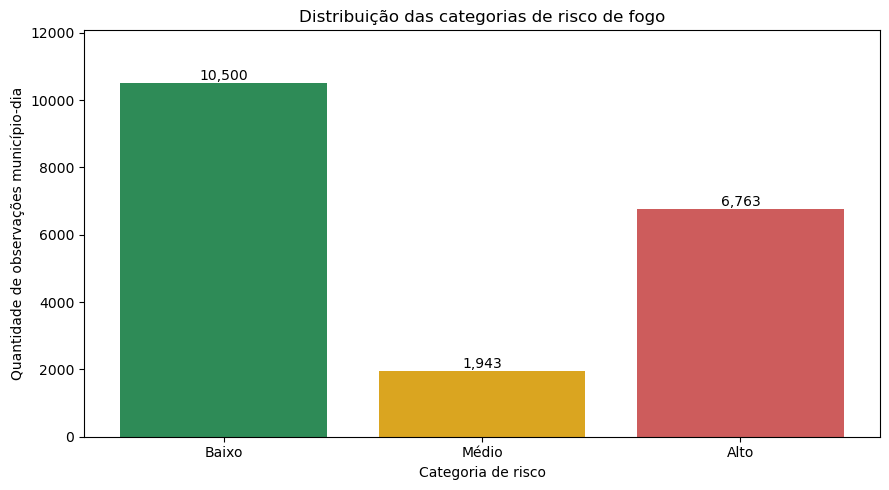

In [121]:
# Importa a biblioteca de visualização
import matplotlib.pyplot as plt

# Define a ordem das categorias
ordem_classes = ["Baixo", "Médio", "Alto"]

# Conta as observações por classe
contagem_risco = (
    df_base_v2["classe_risco"]
    .value_counts()
    .reindex(ordem_classes)
)

# Cria o gráfico
plt.figure(figsize=(9, 5))

barras = plt.bar(
    contagem_risco.index,
    contagem_risco.values,
    color=["#2E8B57", "#DAA520", "#CD5C5C"]
)

# Adiciona os valores sobre as barras
for barra in barras:
    altura = barra.get_height()

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 100,
        f"{int(altura):,}",
        ha="center"
    )

# Personaliza o gráfico
plt.title("Distribuição das categorias de risco de fogo")
plt.xlabel("Categoria de risco")
plt.ylabel("Quantidade de observações município-dia")

plt.ylim(0, contagem_risco.max() * 1.15)

plt.tight_layout()
plt.show()

### Análise da distribuição das categorias de risco de fogo

O gráfico apresenta a distribuição das 19.206 observações município-dia da base consolidada, considerando as três categorias derivadas do indicador `risco_fogo`.

A categoria **Baixo** apresentou a maior frequência, com 10.500 observações (54,67%), seguida pela categoria **Alto**, com 6.763 observações (35,21%).

A categoria **Médio** apresentou a menor representatividade, com 1.943 observações (10,12%).

#### Interpretação dos resultados

A distribuição demonstra um desequilíbrio entre as classes, especialmente pela menor frequência da categoria Médio.

Esse comportamento poderá influenciar o treinamento e a avaliação dos modelos de classificação, pois algoritmos podem apresentar maior facilidade para identificar as categorias com maior quantidade de exemplos.

Por esse motivo, a avaliação posterior deverá considerar métricas como precisão, recall e F1-score por classe, além de métricas agregadas, como F1-macro.

#### Limitações da análise

As categorias foram construídas a partir do maior valor diário de `risco_fogo` associado aos focos detectados em cada município.

Portanto, os resultados descrevem exclusivamente as observações município-dia presentes na base de detecções e não representam a distribuição geral do risco de fogo em todos os municípios brasileiros.

Além disso, a variável-alvo permanece sujeita à validação metodológica definitiva.

#### Conclusão

A análise identificou um desequilíbrio relevante entre as categorias de risco, que deverá ser considerado na seleção e na avaliação dos modelos preditivos.

Nenhuma técnica de balanceamento foi aplicada nesta etapa.

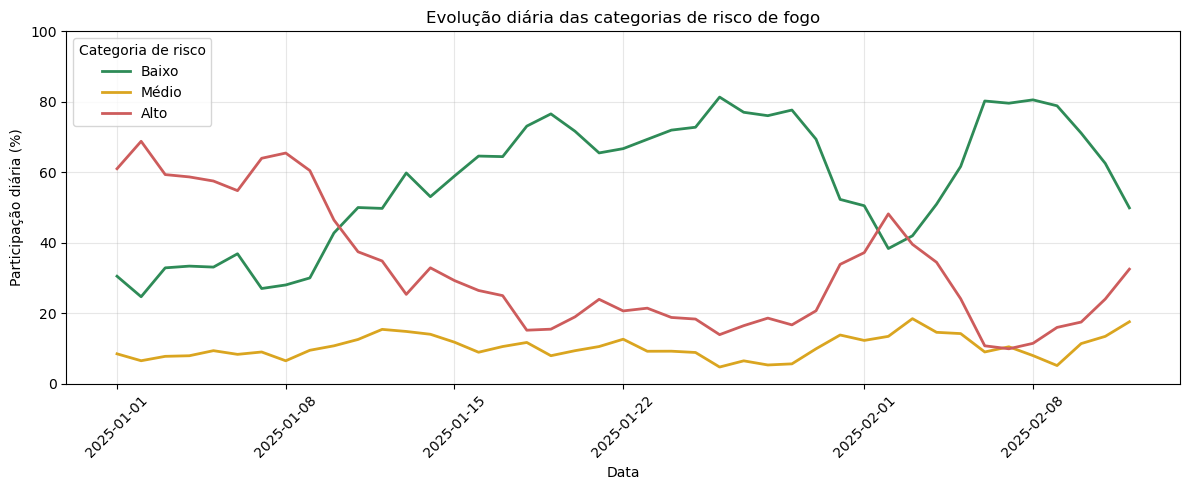

Dias analisados: 43
Primeira data: 2025-01-01
Última data: 2025-02-12


In [122]:
# Organiza a distribuição das classes por data
distribuicao_temporal = pd.crosstab(
    df_base_v2["data"],
    df_base_v2["classe_risco"],
    normalize="index"
) * 100

# Garante a ordem das categorias
distribuicao_temporal = distribuicao_temporal[
    ["Baixo", "Médio", "Alto"]
]

# Converte o índice para datas
distribuicao_temporal.index = pd.to_datetime(
    distribuicao_temporal.index
)

# Cria o gráfico
plt.figure(figsize=(12, 5))

cores = {
    "Baixo": "#2E8B57",
    "Médio": "#DAA520",
    "Alto": "#CD5C5C"
}

for categoria in ["Baixo", "Médio", "Alto"]:

    plt.plot(
        distribuicao_temporal.index,
        distribuicao_temporal[categoria],
        label=categoria,
        color=cores[categoria],
        linewidth=2
    )

# Personaliza a visualização
plt.title("Evolução diária das categorias de risco de fogo")

plt.xlabel("Data")
plt.ylabel("Participação diária (%)")

plt.ylim(0, 100)
plt.legend(title="Categoria de risco")
plt.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Confere o período analisado
print("Dias analisados:", len(distribuicao_temporal))

print(
    "Primeira data:",
    distribuicao_temporal.index.min().date()
)

print(
    "Última data:",
    distribuicao_temporal.index.max().date()
)

### Análise da evolução temporal das categorias de risco

Foi analisada a distribuição percentual diária das categorias Baixo, Médio e Alto, considerando as observações município-dia disponíveis entre 1º de janeiro e 12 de fevereiro de 2025.

A visualização compreende 43 dias e apresenta a participação relativa de cada categoria no total de observações de cada data.

#### Principais resultados

A distribuição das categorias apresentou oscilações relevantes ao longo do período analisado.

No início de janeiro, observou-se predominância da categoria Alto, com participação próxima de 60% das observações diárias.

Ao longo do mês, houve aumento da participação relativa da categoria Baixo, que passou a predominar na segunda metade de janeiro, atingindo aproximadamente 80% em alguns dias.

No início de fevereiro, ocorreram novas alterações na composição das classes, com aumento temporário da participação da categoria Alto.

A categoria Médio apresentou participação relativamente baixa durante todo o período, permanecendo minoritária em comparação às demais.

#### Implicações para a modelagem

A variação temporal observada indica que a distribuição das categorias não permaneceu constante ao longo dos 43 dias.

Esse comportamento deverá ser considerado na futura separação entre treinamento, validação e teste.

Recomenda-se uma divisão cronológica para respeitar a ordem temporal das observações e reduzir o risco de avaliações excessivamente otimistas.

Também será necessário verificar a representatividade das três classes nos conjuntos resultantes.

#### Limitações

A análise considera exclusivamente municípios-dia com registros de focos detectados e valores válidos do indicador de risco.

Portanto, as variações observadas não representam necessariamente alterações gerais no risco de incêndio em todos os municípios brasileiros.

Além disso, o período de 43 dias não permite estabelecer conclusões sobre tendências sazonais de longo prazo.

#### Conclusão

A análise identificou variações relevantes na composição diária das categorias de risco, reforçando a importância de respeitar a dimensão temporal durante a modelagem.

Nenhuma transformação ou técnica de balanceamento foi aplicada nesta etapa.

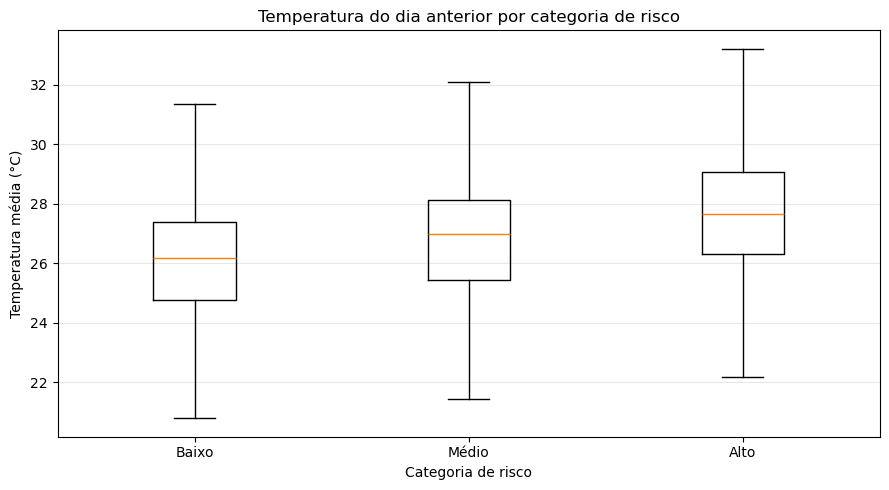

Estatísticas da temperatura por categoria:


,count,mean,median,std
classe_risco,,,,
Baixo,7933,25.97,26.19,2.32
Médio,1417,26.59,27.00,2.69
Alto,4796,27.63,27.65,2.63



Observações com temperatura disponível: 14146


In [123]:
# Seleciona as informações necessárias
df_eda_temperatura = df_base_v2[
    [
        "classe_risco",
        "temperatura_media",
        "horas_com_temperatura"
    ]
].copy()

# Mantém observações com temperatura disponível
df_eda_temperatura = df_eda_temperatura.dropna(
    subset=["temperatura_media"]
)

# Organiza os valores por categoria
ordem_classes = ["Baixo", "Médio", "Alto"]

dados_temperatura = [
    df_eda_temperatura.loc[
        df_eda_temperatura["classe_risco"] == categoria,
        "temperatura_media"
    ]
    for categoria in ordem_classes
]

# Cria o gráfico
plt.figure(figsize=(9, 5))

plt.boxplot(
    dados_temperatura,
    tick_labels=ordem_classes,
    showfliers=False
)

# Personaliza a visualização
plt.title("Temperatura do dia anterior por categoria de risco")
plt.xlabel("Categoria de risco")
plt.ylabel("Temperatura média (°C)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Apresenta estatísticas descritivas
print("Estatísticas da temperatura por categoria:")

display(
    df_eda_temperatura.groupby(
        "classe_risco",
        observed=True
    )["temperatura_media"].agg(
        ["count", "mean", "median", "std"]
    ).reindex(ordem_classes).round(2)
)

# Verifica a quantidade de observações utilizadas
print(
    "\nObservações com temperatura disponível:",
    len(df_eda_temperatura)
)

### Relação entre temperatura média anterior e categorias de risco

Foi investigada a distribuição da temperatura média do dia anterior à previsão, considerando as categorias Baixo, Médio e Alto.

A análise utilizou 14.146 observações município-dia com temperatura disponível.

#### Resultados

| Categoria | Observações | Média (°C) | Mediana (°C) | Desvio-padrão (°C) |
|---|---:|---:|---:|---:|
| Baixo | 7.933 | 25,97 | 26,19 | 2,32 |
| Médio | 1.417 | 26,59 | 27,00 | 2,69 |
| Alto | 4.796 | 27,63 | 27,65 | 2,63 |

#### Interpretação

Observou-se um aumento progressivo da temperatura média entre as categorias Baixo, Médio e Alto.

A categoria Alto apresentou temperatura média aproximadamente 1,66 °C superior à categoria Baixo.

O comportamento das medianas também indicou temperaturas mais elevadas nas categorias superiores de risco.

Entretanto, o boxplot revelou sobreposição entre as distribuições, demonstrando que a temperatura isoladamente não permite distinguir completamente as categorias.

#### Limitações

A análise considera apenas observações com temperatura disponível, incluindo medições diárias calculadas a partir de coberturas horárias potencialmente parciais.

Além disso, diferentes municípios podem compartilhar informações da mesma estação meteorológica, e um mesmo município pode aparecer em diversas datas.

As observações, portanto, não devem ser consideradas necessariamente independentes.

A associação encontrada não demonstra causalidade.

Também é necessário reconhecer que o indicador de risco utilizado na construção das categorias já considera condições ambientais em sua metodologia.

#### Conclusão

A temperatura média do dia anterior apresentou associação descritiva positiva com a categoria de risco de fogo.

Esse resultado justifica investigar estatisticamente as diferenças entre as distribuições, considerando as limitações de dependência espacial e temporal dos dados.

Nenhuma relação causal foi estabelecida nesta análise.

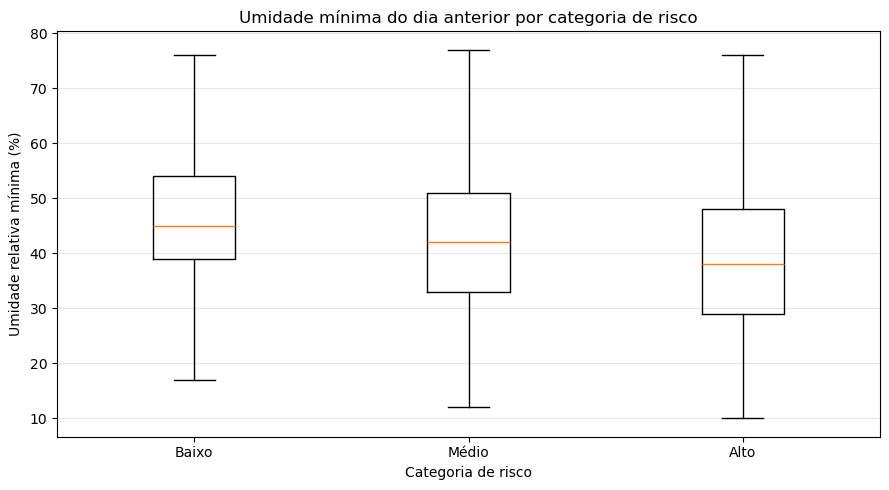

Estatísticas da umidade por categoria:


,count,mean,median,std
classe_risco,,,,
Baixo,7518,46.57,45.0,11.36
Médio,1363,42.55,42.0,11.92
Alto,4522,38.66,38.0,13.02



Observações com umidade disponível: 13403


In [124]:
# Seleciona as informações necessárias
df_eda_umidade = df_base_v2[
    [
        "classe_risco",
        "umidade_minima",
        "horas_com_umidade"
    ]
].copy()

# Mantém observações com umidade disponível
df_eda_umidade = df_eda_umidade.dropna(
    subset=["umidade_minima"]
)

# Define a ordem das categorias
ordem_classes = ["Baixo", "Médio", "Alto"]

# Organiza os valores por categoria
dados_umidade = [
    df_eda_umidade.loc[
        df_eda_umidade["classe_risco"] == categoria,
        "umidade_minima"
    ]
    for categoria in ordem_classes
]

# Cria o gráfico
plt.figure(figsize=(9, 5))

plt.boxplot(
    dados_umidade,
    tick_labels=ordem_classes,
    showfliers=False
)

# Personaliza a visualização
plt.title("Umidade mínima do dia anterior por categoria de risco")
plt.xlabel("Categoria de risco")
plt.ylabel("Umidade relativa mínima (%)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Apresenta as estatísticas descritivas
print("Estatísticas da umidade por categoria:")

display(
    df_eda_umidade.groupby(
        "classe_risco",
        observed=True
    )["umidade_minima"].agg(
        ["count", "mean", "median", "std"]
    ).reindex(ordem_classes).round(2)
)

# Verifica a quantidade de observações utilizadas
print(
    "\nObservações com umidade disponível:",
    len(df_eda_umidade)
)

### Relação entre umidade relativa mínima anterior e categorias de risco

Foi investigada a distribuição da umidade relativa mínima registrada no dia anterior à previsão, considerando as categorias Baixo, Médio e Alto.

A análise utilizou 13.403 observações município-dia com valores disponíveis de umidade.

#### Resultados

| Categoria | Observações | Média (%) | Mediana (%) | Desvio-padrão |
|---|---:|---:|---:|---:|
| Baixo | 7.518 | 46,57 | 45,00 | 11,36 |
| Médio | 1.363 | 42,55 | 42,00 | 11,92 |
| Alto | 4.522 | 38,66 | 38,00 | 13,02 |

#### Interpretação

Observou-se uma redução progressiva da umidade relativa mínima entre as categorias Baixo, Médio e Alto.

A categoria Alto apresentou umidade média 7,91 pontos percentuais inferior à categoria Baixo.

As medianas também diminuíram progressivamente, indicando que a diferença não depende exclusivamente de valores extremos.

O boxplot revelou, entretanto, sobreposição entre as distribuições, demonstrando que a umidade isoladamente não permite distinguir completamente as categorias.

#### Relação com a temperatura

Em conjunto com a análise anterior, os resultados sugerem um padrão meteorológico associado às categorias superiores de risco:

- Temperaturas médias anteriores mais elevadas.
- Umidade relativa mínima anterior mais baixa.

Esse comportamento é fisicamente plausível, mas não demonstra causalidade.

#### Limitações

A análise considera somente observações com umidade disponível. Em dias com medições parciais, o menor valor observado pode não representar o mínimo efetivo daquele dia.

Além disso, diferentes municípios podem compartilhar a mesma estação meteorológica, e um município pode aparecer em diferentes datas, produzindo dependência entre observações.

O indicador de risco utilizado para construir as classes também incorpora informações ambientais em sua metodologia.

Portanto, os resultados representam associações descritivas e não demonstram capacidade de prever diretamente a ocorrência de incêndios.

#### Conclusão

A umidade relativa mínima do dia anterior apresentou associação descritiva inversa com as categorias de risco de fogo.

Esse resultado complementa a análise de temperatura e oferece fundamento para investigar diferenças estatísticas entre as categorias, respeitando as limitações espaciais e temporais dos dados.

Nenhuma relação causal foi estabelecida nesta etapa.

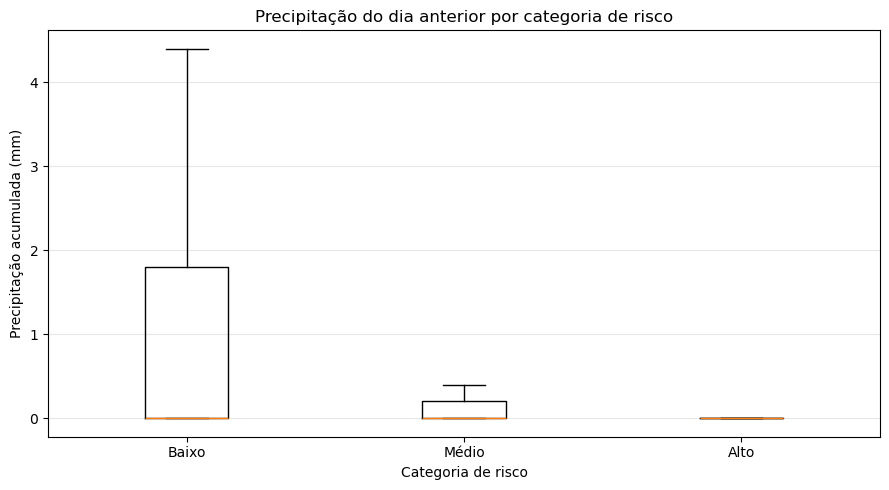

Estatísticas da precipitação por categoria:


,count,mean,median,std
classe_risco,,,,
Baixo,4933,3.28,0.0,8.57
Médio,1015,1.10,0.0,3.80
Alto,3367,0.59,0.0,2.50



Observações com precipitação completa: 9315
Observações com precipitação igual a zero: 6147


In [125]:
# Seleciona as informações necessárias
df_eda_precipitacao = df_base_v2[
    ["classe_risco", "precipitacao_24h"]
].copy()

# Mantém somente observações com precipitação completa
df_eda_precipitacao = df_eda_precipitacao.dropna(
    subset=["precipitacao_24h"]
)

# Define a ordem das categorias
ordem_classes = ["Baixo", "Médio", "Alto"]

# Organiza os valores por categoria
dados_precipitacao = [
    df_eda_precipitacao.loc[
        df_eda_precipitacao["classe_risco"] == categoria,
        "precipitacao_24h"
    ]
    for categoria in ordem_classes
]

# Cria o gráfico
plt.figure(figsize=(9, 5))

plt.boxplot(
    dados_precipitacao,
    tick_labels=ordem_classes,
    showfliers=False
)

# Personaliza a visualização
plt.title("Precipitação do dia anterior por categoria de risco")
plt.xlabel("Categoria de risco")
plt.ylabel("Precipitação acumulada (mm)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Apresenta estatísticas descritivas
print("Estatísticas da precipitação por categoria:")

display(
    df_eda_precipitacao.groupby(
        "classe_risco",
        observed=True
    )["precipitacao_24h"].agg(
        ["count", "mean", "median", "std"]
    ).reindex(ordem_classes).round(2)
)

# Verifica a quantidade de observações utilizadas
print(
    "\nObservações com precipitação completa:",
    len(df_eda_precipitacao)
)

# Verifica a frequência de dias sem chuva registrada
print(
    "Observações com precipitação igual a zero:",
    (df_eda_precipitacao["precipitacao_24h"] == 0).sum()
)

### Relação entre precipitação do dia anterior e categorias de risco

Foi investigada a distribuição da precipitação acumulada no dia anterior à previsão, considerando as categorias Baixo, Médio e Alto.

A análise utilizou exclusivamente observações com 24 medições válidas de precipitação, totalizando 9.315 registros município-dia.

#### Resultados

| Categoria | Observações | Média (mm) | Mediana (mm) | Desvio-padrão (mm) |
|---|---:|---:|---:|---:|
| Baixo | 4.933 | 3,28 | 0,00 | 8,57 |
| Médio | 1.015 | 1,10 | 0,00 | 3,80 |
| Alto | 3.367 | 0,59 | 0,00 | 2,50 |

Das 9.315 observações analisadas, 6.147 apresentaram precipitação igual a zero, correspondendo a aproximadamente 66% do conjunto.

#### Interpretação

Observou-se redução progressiva da precipitação média entre as categorias Baixo, Médio e Alto.

A categoria Alto apresentou precipitação média 2,69 mm inferior à categoria Baixo.

Esse resultado é compatível com a hipótese de que condições meteorológicas mais secas estejam associadas a categorias superiores do indicador de risco.

Entretanto, as três categorias apresentaram mediana igual a zero, indicando elevada concentração de observações sem precipitação registrada.

A distribuição mostrou comportamento assimétrico, com predominância de valores baixos ou nulos e presença de acumulados mais elevados em uma parcela das observações.

#### Relação com as demais variáveis

Em conjunto, as análises meteorológicas identificaram três padrões descritivos associados às categorias superiores de risco:

- Temperaturas médias anteriores mais elevadas.
- Umidade relativa mínima anterior mais baixa.
- Precipitação média anterior menor.

Esses resultados apresentam coerência física, mas não demonstram relações causais.

#### Limitações

A análise considera exclusivamente observações com 24 medições válidas de precipitação no dia anterior.

A associação entre municípios e estações meteorológicas é uma aproximação espacial, e diferentes municípios podem compartilhar dados da mesma estação.

Além disso, a precipitação apresenta elevada concentração de zeros, característica que deverá ser considerada na escolha dos procedimentos estatísticos.

O indicador `risco_fogo` é calculado a partir de condições ambientais, portanto as associações encontradas não representam uma validação independente da ocorrência de incêndios.

#### Conclusão

A precipitação média do dia anterior apresentou associação descritiva inversa com as categorias de risco.

O resultado complementa as análises de temperatura e umidade e fornece evidências exploratórias para a formulação de hipóteses estatísticas.

Nenhuma relação causal foi estabelecida nesta etapa.

In [126]:
# Seleciona as informações necessárias
df_teste_temperatura = df_base_v2[
    ["data", "classe_risco", "temperatura_media"]
].copy()

# Mantém somente as categorias Baixo e Alto
df_teste_temperatura = df_teste_temperatura[
    df_teste_temperatura["classe_risco"].isin(
        ["Baixo", "Alto"]
    )
].copy()

# Remove observações sem temperatura disponível
df_teste_temperatura = df_teste_temperatura.dropna(
    subset=["temperatura_media"]
)

# Calcula a temperatura média por data e categoria
temperaturas_diarias = (
    df_teste_temperatura
    .groupby(["data", "classe_risco"], observed=True)[
        "temperatura_media"
    ]
    .mean()
    .unstack()
)

# Calcula a diferença diária entre as categorias
temperaturas_diarias["diferenca"] = (
    temperaturas_diarias["Alto"]
    - temperaturas_diarias["Baixo"]
)

# Remove datas sem comparação disponível
temperaturas_diarias = temperaturas_diarias.dropna(
    subset=["Baixo", "Alto"]
)

# Apresenta os resultados
print(
    "Dias com comparação disponível:",
    len(temperaturas_diarias)
)

print("\nEstatísticas das diferenças diárias:")
display(
    temperaturas_diarias["diferenca"]
    .describe()
    .round(2)
)

print("\nPrimeiros cinco dias:")
display(temperaturas_diarias.head().round(2))

Dias com comparação disponível: 42

Estatísticas das diferenças diárias:


count    42.00
mean      1.31
std       0.92
min      -0.32
25%       0.63
50%       1.19
75%       1.88
max       3.49
Name: diferenca, dtype: float64


Primeiros cinco dias:


classe_risco,Alto,Baixo,diferenca
data,,,
2025-01-02,28.87,26.58,2.29
2025-01-03,28.62,26.93,1.69
2025-01-04,28.76,26.46,2.30
2025-01-05,28.51,26.27,2.24
2025-01-06,28.18,24.69,3.49


In [127]:
# Organiza as diferenças em ordem cronológica
diferencas_ordenadas = (
    temperaturas_diarias["diferenca"]
    .sort_index()
)

# Calcula a autocorrelação de defasagem 1
autocorrelacao_lag1 = diferencas_ordenadas.autocorr(
    lag=1
)

# Conta os dias com diferença positiva e negativa
dias_positivos = (diferencas_ordenadas > 0).sum()
dias_negativos = (diferencas_ordenadas < 0).sum()
dias_iguais = (diferencas_ordenadas == 0).sum()

# Apresenta os resultados
print(
    f"Autocorrelação (lag 1): "
    f"{autocorrelacao_lag1:.3f}"
)

print("\nDistribuição das diferenças diárias:")
print("Dias com diferença positiva:", dias_positivos)
print("Dias com diferença negativa:", dias_negativos)
print("Dias com diferença igual a zero:", dias_iguais)

print("\nTotal de dias:", len(diferencas_ordenadas))

Autocorrelação (lag 1): 0.739

Distribuição das diferenças diárias:
Dias com diferença positiva: 40
Dias com diferença negativa: 2
Dias com diferença igual a zero: 0

Total de dias: 42


In [128]:
# Verifica se a biblioteca statsmodels está instalada
import importlib.util

biblioteca = importlib.util.find_spec("statsmodels")

if biblioteca is not None:
    print("Statsmodels está instalada.")
else:
    print("Statsmodels não está instalada.")

Statsmodels está instalada.


In [129]:
# Importa a biblioteca de modelos estatísticos
import statsmodels.api as sm

# Organiza as diferenças diárias
diferencas = (
    temperaturas_diarias["diferenca"]
    .sort_index()
    .dropna()
)

# Cria uma constante para cada observação
X = np.ones((len(diferencas), 1))

# Ajusta a regressão com erros-padrão HAC
modelo_hac = sm.OLS(
    diferencas.to_numpy(),
    X
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 3}
)

# Recupera os resultados
diferenca_media = modelo_hac.params[0]
erro_padrao = modelo_hac.bse[0]
estatistica_teste = modelo_hac.tvalues[0]
valor_p = modelo_hac.pvalues[0]

# Intervalo de confiança de 95%
intervalo_confianca = modelo_hac.conf_int(alpha=0.05)[0]

# Apresenta os resultados
print("Teste estatístico com correção HAC")
print("Observações:", len(diferencas))
print("Defasagens consideradas: 3")

print(f"\nDiferença média: {diferenca_media:.3f} °C")
print(f"Erro-padrão HAC: {erro_padrao:.3f}")
print(f"Estatística de teste: {estatistica_teste:.3f}")
print(f"Valor-p: {valor_p:.6f}")

print(
    "Intervalo de confiança de 95%:",
    f"[{intervalo_confianca[0]:.3f}, "
    f"{intervalo_confianca[1]:.3f}] °C"
)

Teste estatístico com correção HAC
Observações: 42
Defasagens consideradas: 3

Diferença média: 1.313 °C
Erro-padrão HAC: 0.232
Estatística de teste: 5.663
Valor-p: 0.000000
Intervalo de confiança de 95%: [0.859, 1.768] °C


In [130]:
# Define as defasagens para análise de sensibilidade
defasagens = [1, 3, 5, 7]

# Armazena os resultados
resultados_sensibilidade = []

# Executa o teste para cada defasagem
for lag in defasagens:

    modelo = sm.OLS(
        diferencas.to_numpy(),
        X
    ).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": lag}
    )

    intervalo = modelo.conf_int(alpha=0.05)[0]

    resultados_sensibilidade.append({
        "Defasagens": lag,
        "Diferença média (°C)": modelo.params[0],
        "Erro-padrão": modelo.bse[0],
        "Valor-p": modelo.pvalues[0],
        "IC inferior": intervalo[0],
        "IC superior": intervalo[1]
    })

# Organiza os resultados
df_sensibilidade = pd.DataFrame(
    resultados_sensibilidade
)

# Apresenta a comparação
print("Análise de sensibilidade — Correção HAC")

display(
    df_sensibilidade.round(6)
)

Análise de sensibilidade — Correção HAC


,Defasagens,Diferença média (°C),Erro-padrão,Valor-p,IC inferior,IC superior
0,1,1.313283,0.183676,0.000000,0.953285,1.673280
1,3,1.313283,0.231913,0.000000,0.858742,1.767823
2,5,1.313283,0.260783,0.000000,0.802157,1.824408
3,7,1.313283,0.278805,0.000002,0.766835,1.859730


### Teste de hipótese estatística — Temperatura média anterior e categorias de risco

#### 1. Objetivo

Investigar se existe diferença estatisticamente significativa na temperatura média do dia anterior entre observações município-dia classificadas nas categorias Baixo e Alto.

A análise considera exclusivamente observações com temperatura disponível no período de 2 de janeiro a 12 de fevereiro de 2025.

#### 2. Formulação das hipóteses

**Hipótese nula (H₀):** a diferença média diária de temperatura entre as categorias Alto e Baixo é igual a zero.

**Hipótese alternativa (H₁):** a diferença média diária de temperatura entre as categorias Alto e Baixo é diferente de zero.

Foi adotado um nível de significância de 5% (α = 0,05).

#### 3. Metodologia

Inicialmente, foram calculadas as temperaturas médias das categorias Baixo e Alto em cada data.

Em seguida, foi obtida a diferença diária:

**Diferença = Temperatura média Alto − Temperatura média Baixo**

Foram identificados 42 dias com informações suficientes para a comparação.

A análise exploratória apresentou autocorrelação de primeira defasagem igual a 0,739, indicando dependência temporal relevante.

Por esse motivo, foi utilizada uma regressão linear contendo apenas uma constante, com erros-padrão robustos à heterocedasticidade e à autocorrelação temporal (HAC/Newey-West).

A análise principal considerou três defasagens. Adicionalmente, foi realizada uma análise de sensibilidade com 1, 3, 5 e 7 defasagens.

#### 4. Resultados

A diferença média diária estimada foi de **+1,313 °C**, indicando temperaturas anteriores mais elevadas nas observações classificadas como Alto.

No modelo principal, com três defasagens HAC, foram obtidos:

| Indicador | Resultado |
|---|---:|
| Dias analisados | 42 |
| Diferença média | +1,313 °C |
| Erro-padrão HAC | 0,232 |
| Estatística de teste | 5,663 |
| Valor-p | < 0,000001 |
| Intervalo de confiança de 95% | [0,859; 1,768] °C |

O valor-p apresentado é inferior ao nível de significância adotado.

O intervalo de confiança de 95% também não contém zero.

#### 5. Análise de sensibilidade

Foram comparadas quatro configurações de defasagem HAC:

| Defasagens | Erro-padrão | IC de 95% (°C) |
|---|---:|---|
| 1 | 0,184 | [0,953; 1,673] |
| 3 | 0,232 | [0,859; 1,768] |
| 5 | 0,261 | [0,802; 1,824] |
| 7 | 0,279 | [0,767; 1,860] |

A conclusão estatística permaneceu consistente em todas as configurações: os valores-p foram inferiores a 0,05 e os intervalos de confiança não incluíram zero.

Portanto, o resultado mostrou-se robusto às defasagens HAC investigadas.

#### 6. Decisão estatística

Ao nível de significância de 5%, **rejeita-se a hipótese nula** no procedimento adotado.

Os resultados fornecem evidências estatísticas de que a diferença média diária de temperatura entre as categorias Alto e Baixo é diferente de zero no recorte analisado.

A diferença estimada foi positiva, indicando temperatura média anterior aproximadamente 1,31 °C superior na categoria Alto.

#### 7. Limitações

O procedimento considera a dependência temporal por meio de erros-padrão HAC, mas não controla completamente possíveis diferenças geográficas ou mudanças na composição dos municípios entre as categorias.

As observações também estão condicionadas à presença de focos detectados e à disponibilidade de temperatura.

Além disso, o indicador utilizado para construir as categorias de risco já incorpora condições ambientais em sua metodologia.

Portanto, a associação identificada não demonstra causalidade, não constitui uma validação independente da ocorrência de incêndios e não garante capacidade preditiva do modelo.

A análise de sensibilidade avaliou diferentes defasagens HAC, mas não elimina todas as possíveis fontes de dependência ou viés.

#### 8. Conclusão

Foi identificada uma diferença positiva e estatisticamente significativa na temperatura média do dia anterior entre as categorias Alto e Baixo, considerando o procedimento estatístico adotado.

O resultado permaneceu consistente nas quatro configurações de defasagem investigadas.

Essa evidência complementa a análise exploratória e contribui para compreender as relações entre condições meteorológicas anteriores e o indicador de risco de fogo.

A interpretação permanece restrita ao conjunto de observações e às hipóteses metodológicas utilizadas.

### Definição do problema de negócio e indicador de desempenho

#### 1. Contexto

O monitoramento de condições ambientais favoráveis à ocorrência de fogo na vegetação é relevante para o planejamento de ações preventivas e de acompanhamento territorial.

Informações meteorológicas e características de uso e cobertura da terra podem contribuir para a estimativa antecipada de níveis de risco.

#### 2. Objetivo do projeto

Desenvolver e avaliar modelos de classificação multiclasse capazes de estimar o nível de risco de fogo para determinado município e dia, utilizando informações disponíveis até o dia anterior à previsão.

O resultado será apresentado em três categorias: Baixo, Médio e Alto.

#### 3. Variável-alvo candidata

A variável-alvo proposta é `classe_risco`, construída a partir do maior valor diário de `risco_fogo` associado aos focos detectados em cada município.

A classificação utiliza três intervalos adaptados da categorização do INPE:

| Categoria | Intervalo |
|---|---|
| Baixo | 0,00 ≤ risco ≤ 0,40 |
| Médio | 0,40 < risco ≤ 0,70 |
| Alto | 0,70 < risco ≤ 1,00 |

Essa adaptação não constitui uma classificação oficial de três níveis do INPE.

#### 4. Unidade de observação

Cada observação representa uma combinação município-dia.

A base consolidada contém 19.206 observações com valores válidos do indicador de risco, referentes ao período de 1º de janeiro a 12 de fevereiro de 2025.

#### 5. Informações explicativas candidatas

As variáveis candidatas incluem:

- Indicadores meteorológicos do dia anterior.
- Distância até a estação meteorológica associada.
- Indicadores de disponibilidade das medições.
- Características territoriais históricas provenientes do MapBiomas.

As variáveis `risco_maximo` e `quantidade_focos` não serão utilizadas como atributos explicativos, pois dependem de informações do próprio dia previsto.

#### 6. KPI principal

O indicador principal proposto para avaliação dos modelos é o **F1-score macro**.

Essa métrica considera igualmente o desempenho nas três categorias, sendo adequada para um problema com distribuição desigual de classes.

Como indicadores complementares, serão utilizados recall da categoria Alto, precisão e recall por classe, acurácia e matriz de confusão.

A meta quantitativa de desempenho será fundamentada posteriormente, após a construção do modelo de referência.

#### 7. Estratégia de validação

A avaliação deverá respeitar a ordem cronológica das observações, evitando divisões aleatórias que misturem informações de períodos próximos.

Será necessário verificar a representatividade das classes nos conjuntos de treinamento, validação e teste.

#### 8. Limitações do escopo

A base de queimadas contém registros associados a focos detectados por satélites, não abrangendo necessariamente todos os municípios e dias sem detecções.

Consequentemente, a variável-alvo proposta representa uma categorização de um indicador previamente calculado, condicionado à presença de registros de focos.

O projeto não deverá apresentar essa classificação como previsão direta da ocorrência de incêndios ou como estimativa validada para todos os municípios brasileiros.

A abordagem também apresenta limitações associadas à curta cobertura temporal, à disponibilidade meteorológica, à aproximação espacial das estações e à defasagem das informações territoriais.

#### 9. Resultado esperado

Produzir uma solução de classificação multiclasse reproduzível, com métricas adequadas, interpretação transparente e documentação das limitações dos dados.

A adoção definitiva da variável-alvo e a abrangência operacional da solução dependerão da validação metodológica nas próximas etapas.

In [131]:
# Seleciona observações com registro meteorológico anterior
df_avaliacao_temporal = df_base_v2.loc[
    df_base_v2["data_medicao"].notna()
].copy()

# Converte a data para formato datetime
df_avaliacao_temporal["data"] = pd.to_datetime(
    df_avaliacao_temporal["data"]
)

# Identifica as datas disponíveis
datas_disponiveis = sorted(
    df_avaliacao_temporal["data"].unique()
)

# Divide as datas em dois períodos para diagnóstico
ponto_divisao = int(len(datas_disponiveis) * 0.8)

data_corte = datas_disponiveis[ponto_divisao]

# Identifica o período de cada observação
df_avaliacao_temporal["periodo"] = "Inicial"

df_avaliacao_temporal.loc[
    df_avaliacao_temporal["data"] >= data_corte,
    "periodo"
] = "Final"

# Apresenta a distribuição das categorias
tabela_periodos = pd.crosstab(
    df_avaliacao_temporal["periodo"],
    df_avaliacao_temporal["classe_risco"]
)

print("Observações com registro meteorológico anterior:")
print(len(df_avaliacao_temporal))

print("\nData de início do período final:")
print(pd.Timestamp(data_corte).date())

print("\nDistribuição das classes por período:")
display(tabela_periodos)

print("\nDistribuição percentual por período:")
display(
    (tabela_periodos.div(
        tabela_periodos.sum(axis=1),
        axis=0
    ) * 100).round(2)
)

Observações com registro meteorológico anterior:
18652

Data de início do período final:
2025-02-04

Distribuição das classes por período:


classe_risco,Alto,Baixo,Médio
periodo,,,
Final,769,2309,439
Inicial,5656,8022,1457



Distribuição percentual por período:


classe_risco,Alto,Baixo,Médio
periodo,,,
Final,21.87,65.65,12.48
Inicial,37.37,53.00,9.63


### Avaliação preliminar da divisão temporal

#### Objetivo

Investigar a distribuição das categorias de risco em dois períodos cronológicos, considerando observações município-dia com registro meteorológico associado ao dia anterior.

A análise tem caráter exploratório e não representa a definição definitiva dos conjuntos de treinamento e teste.

#### Resultados

Após a exclusão das observações sem registro meteorológico anterior, permaneceram 18.652 observações.

A data de 4 de fevereiro de 2025 foi utilizada como referência para separar os períodos inicial e final.

| Categoria | Período inicial | Período final |
|---|---:|---:|
| Baixo | 8.022 (53,00%) | 2.309 (65,65%) |
| Médio | 1.457 (9,63%) | 439 (12,48%) |
| Alto | 5.656 (37,37%) | 769 (21,87%) |
| **Total** | **15.135** | **3.517** |

#### Interpretação

As três categorias estão presentes em ambos os períodos.

Entretanto, foram identificadas diferenças relevantes na composição das classes.

A participação da categoria Alto diminuiu de 37,37% para 21,87%, enquanto a participação da categoria Baixo aumentou de 53,00% para 65,65%.

Essas mudanças indicam que a distribuição das categorias varia ao longo do tempo, podendo influenciar a capacidade de generalização dos futuros modelos.

#### Implicações para a modelagem

A divisão cronológica permanece como estratégia recomendada para a avaliação dos modelos, respeitando a ordem temporal das observações.

O F1-score macro será utilizado como indicador principal, acompanhado de métricas por classe, especialmente o recall da categoria Alto.

A escolha definitiva dos períodos de treinamento, validação e teste será realizada na etapa de modelagem.

#### Limitações

O período analisado contém apenas 42 dias com informações meteorológicas anteriores disponíveis.

Além disso, a existência de um registro meteorológico não garante que todas as variáveis estejam preenchidas.

A análise também considera exclusivamente municípios-dia com focos detectados e valores válidos do indicador de risco.

Portanto, os resultados não devem ser interpretados como representativos de todos os municípios brasileiros.

#### Conclusão

A análise identificou mudanças relevantes na distribuição temporal das categorias de risco, reforçando a necessidade de uma avaliação cronológica cuidadosa.

A divisão investigada permanece exploratória e não foi utilizada para treinamento ou seleção de modelos.

In [132]:
# Define o caminho da segunda versão
arquivo_base_v2 = (
    projeto
    / "dados"
    / "processados"
    / "base_consolidada_v2.csv"
)

# Verifica se o arquivo já existe
if arquivo_base_v2.exists():

    print("A versão 2 já existe. Exportação não realizada.")

else:

    # Exporta a base preparada
    df_base_v2.to_csv(
        arquivo_base_v2,
        index=False,
        encoding="utf-8-sig"
    )

    print("Versão 2 exportada com sucesso!")

# Confirma a existência do arquivo
print("Arquivo encontrado:", arquivo_base_v2.exists())

# Verifica as dimensões após a leitura
df_verificacao_v2 = pd.read_csv(
    arquivo_base_v2,
    dtype={"id_municipio": "string"}
)

print("Dimensões originais:", df_base_v2.shape)
print("Dimensões após leitura:", df_verificacao_v2.shape)

# Confere a integridade
print(
    "Municípios-dia duplicados:",
    df_verificacao_v2.duplicated(
        subset=["id_municipio", "data"]
    ).sum()
)

print(
    "Classificações ausentes:",
    df_verificacao_v2["classe_risco"].isna().sum()
)

print("\nLocalização:")
print(arquivo_base_v2)

A versão 2 já existe. Exportação não realizada.
Arquivo encontrado: True
Dimensões originais: (19206, 45)
Dimensões após leitura: (19206, 45)
Municípios-dia duplicados: 0
Classificações ausentes: 0

Localização:
C:\Users\adl_c\Sprint18_Projeto_Final\dados\processados\base_consolidada_v2.csv


In [133]:
# Define as três variáveis meteorológicas analisadas
variaveis_clima = [
    "temperatura_media",
    "umidade_minima",
    "precipitacao_soma"
]

# Identifica observações com as três variáveis ausentes
clima_totalmente_ausente = df_base_v2[variaveis_clima].isna().all(axis=1)

# Identifica observações com pelo menos uma variável ausente
clima_parcialmente_ausente = df_base_v2[variaveis_clima].isna().any(axis=1)

# Calcula as quantidades e os percentuais
total = len(df_base_v2)

print("Total de observações:", total)

print(
    "Três variáveis meteorológicas ausentes:",
    clima_totalmente_ausente.sum(),
    f"({clima_totalmente_ausente.mean():.2%})"
)

print(
    "Pelo menos uma variável meteorológica ausente:",
    clima_parcialmente_ausente.sum(),
    f"({clima_parcialmente_ausente.mean():.2%})"
)

Total de observações: 19206
Três variáveis meteorológicas ausentes: 4814 (25.07%)
Pelo menos uma variável meteorológica ausente: 8334 (43.39%)


In [134]:
import pandas as pd

df_base_v2 = pd.read_csv(
    "../dados/processados/base_consolidada_v2.csv"
)

print("Dimensões da base:", df_base_v2.shape)

Dimensões da base: (19206, 45)


In [135]:
# Identifica as colunas relacionadas às informações meteorológicas
colunas_meteorologicas = [
    coluna for coluna in df_base_v2.columns
    if any(termo in coluna.lower() for termo in
           ["temperatura", "umidade", "precipitacao", "horas_com"])
]

print("Colunas meteorológicas encontradas:\n")

for coluna in colunas_meteorologicas:
    print(coluna)

Colunas meteorológicas encontradas:

temperatura_media
precipitacao_soma
umidade_minima
horas_com_temperatura
horas_com_precipitacao
horas_com_umidade
precipitacao_24h


In [136]:
# Compara os valores ausentes nos dois indicadores de precipitação

colunas = [
    "temperatura_media",
    "umidade_minima",
    "precipitacao_soma",
    "precipitacao_24h"
]

print("Valores ausentes por variável:\n")

for coluna in colunas:
    quantidade = df_base_v2[coluna].isna().sum()
    percentual = df_base_v2[coluna].isna().mean() * 100

    print(f"{coluna}: {quantidade} ({percentual:.2f}%)")

Valores ausentes por variável:

temperatura_media: 5060 (26.35%)
umidade_minima: 5803 (30.21%)
precipitacao_soma: 7391 (38.48%)
precipitacao_24h: 9891 (51.50%)


In [137]:
# Verifica ausências considerando a precipitação acumulada em 24 horas

variaveis_clima_24h = [
    "temperatura_media",
    "umidade_minima",
    "precipitacao_24h"
]

ausencia_total_24h = df_base_v2[variaveis_clima_24h].isna().all(axis=1)
ausencia_parcial_24h = df_base_v2[variaveis_clima_24h].isna().any(axis=1)

print("Total de observações:", len(df_base_v2))

print(
    "Três variáveis ausentes:",
    ausencia_total_24h.sum(),
    f"({ausencia_total_24h.mean():.2%})"
)

print(
    "Pelo menos uma variável ausente:",
    ausencia_parcial_24h.sum(),
    f"({ausencia_parcial_24h.mean():.2%})"
)

Total de observações: 19206
Três variáveis ausentes: 4846 (25.23%)
Pelo menos uma variável ausente: 10664 (55.52%)


In [138]:
# Classifica as observações pela disponibilidade de dados meteorológicos

quantidade_ausentes = df_base_v2[
    variaveis_clima_24h
].isna().sum(axis=1)

disponibilidade_clima = pd.Series(
    {
        "Dados completos": (quantidade_ausentes == 0).sum(),
        "Dados parcialmente ausentes": (
            (quantidade_ausentes > 0) &
            (quantidade_ausentes < 3)
        ).sum(),
        "Dados totalmente ausentes": (quantidade_ausentes == 3).sum()
    }
)

resultado_disponibilidade = pd.DataFrame({
    "Quantidade": disponibilidade_clima,
    "Percentual (%)": (
        disponibilidade_clima / len(df_base_v2) * 100
    ).round(2)
})

display(resultado_disponibilidade)

,Quantidade,Percentual (%)
Dados completos,8542,44.48
Dados parcialmente ausentes,5818,30.29
Dados totalmente ausentes,4846,25.23


### Análise complementar — Disponibilidade dos dados meteorológicos

A análise de valores ausentes foi realizada sobre as variáveis
`temperatura_media`, `umidade_minima` e `precipitacao_24h`,
considerando as 19.206 observações da base consolidada.

Os resultados indicaram:

- **8.542 observações (44,48%)** com as três variáveis disponíveis.
- **5.818 observações (30,29%)** com ausência de uma ou duas variáveis.
- **4.846 observações (25,23%)** com as três variáveis ausentes.

Portanto, **55,52% das observações apresentam pelo menos uma
informação meteorológica ausente**.

Essa limitação deve ser considerada na interpretação dos resultados,
pois reduz a disponibilidade de informações meteorológicas para
parte significativa das observações.

Na etapa de modelagem, os valores ausentes são tratados por meio
de imputação pela mediana, ajustada exclusivamente com os dados
de treinamento, evitando vazamento de informações entre os conjuntos.

Entretanto, a imputação não recupera as condições meteorológicas
efetivamente observadas. Nos registros sem nenhuma dessas três
variáveis, as previsões dependem dos demais atributos disponíveis
e dos valores imputados.

A manutenção dessas observações preserva a cobertura da base,
mas exige cautela na interpretação das previsões e na avaliação
da capacidade de generalização do modelo.

In [139]:
# Classifica a disponibilidade das variáveis meteorológicas
quantidade_ausentes = df_base_v2[
    variaveis_clima_24h
].isna().sum(axis=1)

df_analise_clima = pd.DataFrame({
    "classe_risco": df_base_v2["classe_risco"],
    "disponibilidade_clima": quantidade_ausentes.map({
        0: "Completo",
        1: "Parcial",
        2: "Parcial",
        3: "Totalmente ausente"
    })
})

# Calcula a distribuição por categoria de risco
tabela_clima_risco = pd.crosstab(
    df_analise_clima["classe_risco"],
    df_analise_clima["disponibilidade_clima"]
)

# Calcula os percentuais dentro de cada categoria
percentuais_clima_risco = (
    tabela_clima_risco
    .div(tabela_clima_risco.sum(axis=1), axis=0)
    * 100
).round(2)

print("Quantidade de observações:")
display(tabela_clima_risco)

print("Percentual dentro de cada categoria de risco:")
display(percentuais_clima_risco)

Quantidade de observações:


disponibilidade_clima,Completo,Parcial,Totalmente ausente
classe_risco,,,
Alto,2999,1917,1847
Baixo,4609,3391,2500
Médio,934,510,499


Percentual dentro de cada categoria de risco:


disponibilidade_clima,Completo,Parcial,Totalmente ausente
classe_risco,,,
Alto,44.34,28.35,27.31
Baixo,43.90,32.30,23.81
Médio,48.07,26.25,25.68


### Análise complementar — Disponibilidade meteorológica por categoria de risco

A distribuição dos dados meteorológicos ausentes foi analisada
separadamente para as categorias Baixo, Médio e Alto.

Os resultados demonstraram que a ausência de informações
meteorológicas está presente nas três categorias.

A proporção de observações com as três variáveis ausentes foi:

- **Baixo:** 23,81%.
- **Médio:** 25,68%.
- **Alto:** 27,31%.

A categoria Alto apresentou a maior proporção de registros
totalmente ausentes, enquanto a categoria Médio apresentou
a maior disponibilidade de dados completos (48,07%).

Esses resultados indicam diferenças moderadas na disponibilidade
meteorológica entre as categorias de risco.

A ausência de informações pode limitar a capacidade dos modelos
de identificar padrões associados às condições meteorológicas.

Entretanto, essa análise é descritiva e não permite afirmar
que os valores ausentes provocaram erros de classificação.

A investigação reforça a necessidade de interpretar os resultados
da modelagem considerando as limitações de cobertura e qualidade
dos dados meteorológicos.

In [140]:
# Identifica as variáveis presentes na base consolidada

import pandas as pd

df_base_v2 = pd.read_csv(
    "../dados/processados/base_consolidada_v2.csv"
)

print("Total de variáveis:", len(df_base_v2.columns))

for numero, coluna in enumerate(df_base_v2.columns, start=1):
    print(f"{numero:02d}. {coluna}")

Total de variáveis: 45
01. id_municipio
02. data
03. id_estacao
04. distancia_km
05. data_medicao
06. data_previsao
07. temperatura_media
08. precipitacao_soma
09. umidade_minima
10. horas_com_temperatura
11. horas_com_precipitacao
12. horas_com_umidade
13. precipitacao_24h
14. risco_maximo
15. quantidade_focos
16. classe_risco
17. area_classe_0
18. area_classe_3
19. area_classe_4
20. area_classe_5
21. area_classe_9
22. area_classe_11
23. area_classe_12
24. area_classe_13
25. area_classe_15
26. area_classe_20
27. area_classe_21
28. area_classe_23
29. area_classe_24
30. area_classe_25
31. area_classe_29
32. area_classe_30
33. area_classe_31
34. area_classe_32
35. area_classe_33
36. area_classe_39
37. area_classe_40
38. area_classe_41
39. area_classe_46
40. area_classe_47
41. area_classe_48
42. area_classe_49
43. area_classe_50
44. area_classe_62
45. possui_mapbiomas


In [141]:
# Examina a estrutura das variáveis da base consolidada

resumo_variaveis = pd.DataFrame({
    "Tipo de dado": df_base_v2.dtypes.astype(str),
    "Valores ausentes": df_base_v2.isna().sum(),
    "Exemplo": df_base_v2.apply(
        lambda coluna: coluna.dropna().iloc[0]
        if not coluna.dropna().empty else None
    )
})

# Apresenta as variáveis anteriores às classes MapBiomas
display(resumo_variaveis.head(16))

# Apresenta o indicador de disponibilidade MapBiomas
display(resumo_variaveis.tail(1))

,Tipo de dado,Valores ausentes,Exemplo
id_municipio,int64,0,2401453
data,object,0,2025-01-04
id_estacao,object,0,A318
distancia_km,float64,0,34.495316
data_medicao,object,554,2025-01-03
data_previsao,object,554,2025-01-04
temperatura_media,float64,5060,29.020833
precipitacao_soma,float64,7391,0.0
umidade_minima,float64,5803,50.0
horas_com_temperatura,float64,554,24.0


,Tipo de dado,Valores ausentes,Exemplo
possui_mapbiomas,bool,0,True


### Dicionário de dados — Base consolidada

A base consolidada contém 19.206 observações município-dia e 45 variáveis. As definições abaixo descrevem os principais campos utilizados na preparação, na análise exploratória e na modelagem.

| Variável | Descrição |
|---|---|
| `id_municipio` | Identificador do município associado à observação. |
| `data` | Data de referência da observação município-dia. |
| `id_estacao` | Identificador da estação meteorológica associada ao município. |
| `distancia_km` | Distância, em quilômetros, entre o município e a estação meteorológica associada. |
| `data_medicao` | Data das medições meteorológicas utilizadas. |
| `data_previsao` | Data de referência para a previsão, correspondente à observação analisada. |
| `temperatura_media` | Temperatura média diária registrada na estação meteorológica, em graus Celsius. |
| `precipitacao_soma` | Soma das medições de precipitação no período diário, em milímetros. |
| `umidade_minima` | Menor umidade relativa do ar registrada no dia, em percentual. |
| `horas_com_temperatura` | Quantidade de medições horárias válidas de temperatura. |
| `horas_com_precipitacao` | Quantidade de medições horárias válidas de precipitação. |
| `horas_com_umidade` | Quantidade de medições horárias válidas de umidade. |
| `precipitacao_24h` | Indicador de precipitação acumulada em 24 horas, em milímetros. |
| `risco_maximo` | Maior valor do indicador de risco de fogo registrado para o município e a data. |
| `quantidade_focos` | Quantidade de focos de queimadas detectados no município e na data. |
| `classe_risco` | Categoria de risco derivada do indicador `risco_maximo`: Baixo, Médio ou Alto. |
| `possui_mapbiomas` | Indicador booleano da disponibilidade de informações territoriais do MapBiomas. |

**Observação metodológica:** `risco_maximo` e `quantidade_focos` não foram utilizados como atributos explicativos dos modelos. A variável `classe_risco` foi utilizada como alvo da classificação.

As variáveis territoriais `area_classe_*` serão documentadas separadamente, considerando os códigos de classificação do MapBiomas.

### Dicionário complementar — Variáveis territoriais MapBiomas

As 28 variáveis com prefixo `area_classe_` representam
informações de área associadas às classes de cobertura e
uso da terra da classificação MapBiomas.

O número presente no nome da variável corresponde ao
identificador da classe na legenda utilizada pela fonte.

**Variáveis presentes na base:**

`area_classe_0`, `area_classe_3`, `area_classe_4`,
`area_classe_5`, `area_classe_9`, `area_classe_11`,
`area_classe_12`, `area_classe_13`, `area_classe_15`,
`area_classe_20`, `area_classe_21`, `area_classe_23`,
`area_classe_24`, `area_classe_25`, `area_classe_29`,
`area_classe_30`, `area_classe_31`, `area_classe_32`,
`area_classe_33`, `area_classe_39`, `area_classe_40`,
`area_classe_41`, `area_classe_46`, `area_classe_47`,
`area_classe_48`, `area_classe_49`, `area_classe_50`
e `area_classe_62`.

**Observação:** os nomes oficiais das classes e a unidade
de medida das áreas deverão ser conferidos na documentação
da fonte antes da entrega definitiva.

O indicador `possui_mapbiomas` informa se a observação
dispõe de dados territoriais associados.

In [142]:
# Seleciona as variáveis meteorológicas utilizadas no modelo
variaveis_correlacao = [
    "temperatura_media",
    "umidade_minima",
    "precipitacao_24h"
]

# Calcula a matriz de correlação de Pearson
matriz_correlacao = df_base_v2[
    variaveis_correlacao
].corr(method="pearson")

print("Matriz de correlação — Variáveis meteorológicas")
display(matriz_correlacao.round(3))

Matriz de correlação — Variáveis meteorológicas


,temperatura_media,umidade_minima,precipitacao_24h
temperatura_media,1.000,-0.345,-0.137
umidade_minima,-0.345,1.000,0.275
precipitacao_24h,-0.137,0.275,1.000


### Análise complementar — Correlação entre variáveis meteorológicas

Foi calculada a matriz de correlação de Pearson para as variáveis
`temperatura_media`, `umidade_minima` e `precipitacao_24h`,
utilizadas na modelagem.

Os resultados indicaram:

- **Temperatura × Umidade:** correlação negativa de -0,345.
- **Temperatura × Precipitação:** correlação negativa de -0,137.
- **Umidade × Precipitação:** correlação positiva de 0,275.

A associação linear mais expressiva ocorreu entre temperatura
e umidade mínima, indicando uma tendência de temperaturas
mais elevadas estarem associadas a menores valores de umidade.

Nenhuma das três combinações apresentou correlação linear forte.

A análise utilizou os pares de observações disponíveis para
cada combinação de variáveis, considerando a presença de
valores ausentes na base.

Esses resultados são descritivos e não permitem estabelecer
relações causais. Também não descartam relações não lineares
ou correlações entre outros atributos explicativos.

In [143]:
# Seleciona as variáveis explicativas utilizadas na modelagem
colunas_analise = [
    "temperatura_media",
    "umidade_minima",
    "precipitacao_24h",
    "horas_com_temperatura",
    "horas_com_umidade",
    "horas_com_precipitacao",
    "distancia_km",
    "possui_mapbiomas"
] + [
    coluna for coluna in df_base_v2.columns
    if coluna.startswith("area_classe_")
]

# Calcula a matriz de correlação
matriz_completa = df_base_v2[colunas_analise].corr()

# Seleciona apenas uma ocorrência de cada par
import numpy as np

mascara_superior = np.triu(
    np.ones(matriz_completa.shape, dtype=bool),
    k=1
)

pares_correlacao = (
    matriz_completa
    .where(mascara_superior)
    .stack()
    .reset_index()
)

pares_correlacao.columns = [
    "Variável 1",
    "Variável 2",
    "Correlação"
]

# Filtra correlações fortes e ordena pela intensidade
correlacoes_fortes = pares_correlacao[
    pares_correlacao["Correlação"].abs() >= 0.80
].copy()

correlacoes_fortes["Intensidade"] = (
    correlacoes_fortes["Correlação"].abs()
)

correlacoes_fortes = correlacoes_fortes.sort_values(
    "Intensidade", ascending=False
)

print("Pares com correlação absoluta >= 0,80:")
display(
    correlacoes_fortes[
        ["Variável 1", "Variável 2", "Correlação"]
    ].round(3)
)

Pares com correlação absoluta >= 0,80:


,Variável 1,Variável 2,Correlação
101,horas_com_temperatura,horas_com_umidade,0.855


### Análise complementar — Correlação entre os atributos explicativos

Foi calculada a matriz de correlação de Pearson entre os 36 atributos explicativos utilizados na modelagem.

Para facilitar a identificação de possíveis redundâncias, foram selecionados os pares com correlação absoluta igual ou superior a 0,80.

A análise identificou apenas um par acima desse limite:

- **`horas_com_temperatura` × `horas_com_umidade`: 0,855.**

A correlação positiva forte indica que a disponibilidade de medições válidas de temperatura e umidade apresenta comportamento semelhante nas observações analisadas.

Esse resultado sugere possível redundância informacional entre os dois indicadores.

Entretanto, a correlação elevada não determina, isoladamente, a necessidade de excluir atributos, especialmente em modelos baseados em árvores, como o Random Forest.

Assim, nenhuma variável foi removida com base exclusivamente nessa análise.

Os resultados são exploratórios, consideram os pares de valores disponíveis e não estabelecem relações causais.

In [144]:
# Análise inicial de valores extremos nas variáveis meteorológicas

variaveis_outliers = [
    "temperatura_media",
    "umidade_minima",
    "precipitacao_24h"
]

# Calcula estatísticas descritivas e percentis
resumo_outliers = df_base_v2[variaveis_outliers].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
)

print("Distribuição das variáveis meteorológicas:")
display(resumo_outliers.round(2).T)

Distribuição das variáveis meteorológicas:


,count,mean,std,min,1%,25%,50%,75%,99%,max
temperatura_media,14146.0,26.59,2.59,14.06,19.48,25.2,26.74,28.05,33.43,36.21
umidade_minima,13403.0,43.49,12.54,7.00,16.00,35.0,43.00,52.00,74.00,96.00
precipitacao_24h,9315.0,2.07,6.66,0.00,0.00,0.0,0.00,0.40,34.97,101.00


In [145]:
# Identifica valores extremos utilizando o método IQR

resultados_iqr = []

for coluna in variaveis_outliers:
    dados = df_base_v2[coluna].dropna()

    q1 = dados.quantile(0.25)
    q3 = dados.quantile(0.75)

    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    quantidade_outliers = (
        (dados < limite_inferior) |
        (dados > limite_superior)
    ).sum()

    resultados_iqr.append({
        "Variável": coluna,
        "Limite inferior": round(limite_inferior, 2),
        "Limite superior": round(limite_superior, 2),
        "Outliers": quantidade_outliers,
        "Percentual (%)": round(
            quantidade_outliers / len(dados) * 100, 2
        )
    })

df_resultados_iqr = pd.DataFrame(resultados_iqr)

display(df_resultados_iqr)

,Variável,Limite inferior,Limite superior,Outliers,Percentual (%)
0,temperatura_media,20.92,32.33,555,3.92
1,umidade_minima,9.50,77.50,70,0.52
2,precipitacao_24h,-0.60,1.00,1853,19.89


### Análise complementar — Identificação de outliers e plausibilidade

Foi realizada uma investigação exploratória de valores extremos nas variáveis `temperatura_media`, `umidade_minima` e `precipitacao_24h`.

Inicialmente, foram examinados os valores mínimos, máximos e percentis. Os intervalos observados foram:

- **Temperatura média:** 14,06 °C a 36,21 °C.
- **Umidade mínima:** 7% a 96%.
- **Precipitação em 24 horas:** 0 a 101 mm.

Esses intervalos não apresentaram valores imediatamente incompatíveis com as características físicas das variáveis analisadas.

Em seguida, foi aplicado o método do intervalo interquartil (IQR), considerando limites de 1,5 vez o IQR.

Os resultados foram:

- **Temperatura média:** 555 outliers (3,92% dos valores válidos).
- **Umidade mínima:** 70 outliers (0,52%).
- **Precipitação em 24 horas:** 1.853 outliers (19,89%).

A maior proporção de valores extremos ocorreu na precipitação. Entretanto, sua distribuição apresenta concentração de observações próximas de zero, resultando em limite superior de apenas 1,00 mm pelo método IQR.

Assim, a quantidade elevada de valores sinalizados nessa variável não constitui, isoladamente, evidência de erro nos registros.

**Decisão metodológica:** nenhum valor foi excluído ou substituído exclusivamente por ser classificado como outlier pelo IQR.

A manutenção desses registros preserva possíveis condições meteorológicas extremas relevantes para o problema estudado. A análise é exploratória e não substitui uma validação individual das medições com suas fontes originais.